# Human Influence in Rural Wildfire Ignitions

## Group: 02
### Name(s) & ID(s) of Group Members:
- Benedita Barreto da Costa Gonçalves - 202205903
- Isabela Moreira Merelles - 202602764
- Maria Leonor Soares Carvalho - 202307522
- Mariana Vale de Oliveira Coelho de Pinho - 202306234

## Table of Contents

1. [Research Question](#1-research-question)
2. [Collect Data](#2-collect-data)
   - 2.1 Dataset Source
   - 2.2 Dataset Details
   - 2.3 Data Preparation
3. [Explore Data](#3-explore-data)
   - 3.1 Q1: Changes in negligent causes
   - 3.2 Q2: Daily negligent ignitions on weekends and weekdays
   - 3.3 Q3: Burnt area across municipalities
   - 3.4 Q4: Burnt area by cause type and period
4. [Draw Inferences](#4-draw-inferences)
   - 4.1 Q1: Z-test for proportions and chi-square tests
   - 4.2 Q2: Welch's two-sample t-test
   - 4.3 Q3: One-way ANOVA
   - 4.4 Q4: Two-way ANOVA
5. [Formulate Conclusions](#5-formulate-conclusions)
   - 5.1 to 5.4: one conclusion per question (Q1 to Q4)
   - 5.5 Overall answer
6. [Look Back and Ahead](#6-look-back-and-ahead)
   - 6.1 Limitations
   - 6.2 Alternative Approaches and Future Work

[Appendix A: Additional Robustness Checks](#appendix-a)

[References](#references)

---

<a id="1-research-question"></a>
## 1) Research Question

How did human-caused wildfire ignitions and their burnt area change before and after 2017, and how do they differ across four Portuguese municipalities?

### Context

2017 was the most severe wildfire year on record in Portugal. By 31 October, the provisional ICNF report counted 16,981 occurrences and 442,418 ha of burnt forest and shrubland, half of it in October (Instituto da Conservação da Natureza e das Florestas [ICNF], 2017). The fires caused 117 deaths, 64 in June, most of them in the Pedrógão Grande fire of 17 June, 48 in October and 5 in the following months among the seriously injured (Fernandes & Lourenço, 2019). The government responded with a reform of the prevention and suppression system, whose principles were set out in Resolução do Conselho de Ministros n.º 157-A/2017. The Agency for Integrated Rural Fire Management (AGIF) was created by Decreto-Lei n.º 12/2018, and the Integrated Rural Fire Management System (SGIFR) was established by Decreto-Lei n.º 82/2021, of 13 October.

For this reason, 2001–2016 is compared with 2018–2025, and 2017 is left out as an exceptional transition year. Because the reform was introduced gradually, the post-2017 period mixes years before and after Decreto-Lei n.º 82/2021, so the analysis describes change around 2017 rather than the effect of any single measure.

### Study Area

The four municipalities form two pairs of neighbouring municipalities in contrasting regions. Chaves and Montalegre (Alto Tâmega, in the North) are inland, mountainous and sparsely populated, with extensive pastoral land use in which fire has traditionally been used to renew pasture and to burn agricultural residues. Ourém and Tomar (Médio Tejo, in the Centre) lie at lower altitude, are more densely populated, have a denser network of settlements and roads, and have a large share of pine and eucalyptus forest. The two regions therefore differ in the human factors highlighted in the theme (population density, land use and accessibility), and choosing two municipalities in each region helps to separate regional contrasts from differences between individual municipalities.

### Secondary Research Questions

1. **Q1.** Did the proportion of negligent fires among human-caused fires change between the pre-2017 and post-2017 periods, and was the change the same in the critical summer period and in the non-critical months?

    Difference in proportions (Variables: `Cause_Type`, `Period`, `Season_Risk_Period`). Tests: two-proportion Z-test run separately for each season; Breslow-Day chi-square test of homogeneity of odds ratios to compare the two seasons.

2. **Q2.** Did the mean number of daily negligent wildfire ignitions differ significantly between weekends and weekdays in the post-2017 period in the municipalities of Chaves, Montalegre, Ourém and Tomar?

    Mean comparison (Variables: `Daily_Ignitions_Count`, `Day_Type`; `Period` is used only to restrict the data to 2018–2025). Test: Welch's two-sample t-test over all calendar days, complemented by the same test on days with at least one ignition.

3. **Q3.** Does the mean log-transformed burnt area per fire (equivalently, the geometric mean burnt area per fire) differ significantly across Chaves, Montalegre, Ourém and Tomar during 2018–2025?

    ANOVA (Variables: `Log_Total_Burnt_Area`, `Municipality`). Test: one-way ANOVA with Tukey HSD. All fires are included, whatever their cause (the reasons are given in Section 3.3).

4. **Q4.** Did the disparity in final burnt area between intentional and negligent causes narrow in the post-2017 period in the municipalities under study?

    ANOVA and analysis of covariance (Variables: `Log_Total_Burnt_Area`, `Cause_Type`, `Period`, `FWI`). Tests: two-way ANOVA; the same model with `FWI` as a covariate, to check whether differences in fire weather explain the results.

---

<a id="2-collect-data"></a>
## 2) Collect Data

### 2.1 Dataset Source

The dataset used in this project was sourced from the Institute for Nature Conservation and Forests (ICNF), specifically the wildfire statistics published under the Information Management section of [their website](https://www.icnf.pt/florestas/gfr/gfrgestaoinformacao/estatisticas). This dataset contains every rural fire occurrence recorded in the SGIF from 2001 to 2025, whatever its cause (ICNF, n.d.). The records are split across three ICNF files (2001–2010, 2011–2020 and 2021–2025), and were combined into a single dataset before analysis.

The raw file contains 40 columns covering fire identifiers, location, timestamps, burnt area by land cover, fire weather indices, and cause classification. Only a subset of these columns was used in the analysis, and several variables were derived from them. The full mapping is described below so that the variables can be reproduced from the raw file.

### 2.2 Dataset Details

The analysis is built on three main qualitative variables (`Cause_Type`, `Period` and `Municipality`) and three quantitative variables (`Daily_Ignitions_Count`, `Total_Burnt_Area` and `FWI`). `Season_Risk_Period` and `Day_Type` are calendar classifications derived from the dates and are used only to split the data within Q1 and Q2, `Cause_Type_Period` combines two of the main variables, and `Log_Total_Burnt_Area` is a transformation of `Total_Burnt_Area`.

#### Qualitative Variables
- **Cause_Type**: Intentional vs. Negligent. Derived from the cause classification column (`TipoCausa`), keeping only fires whose cause was classified as intentional or negligent. Fires with a natural cause, reignitions, fires with an unknown cause and fires without a cause classification were excluded.
- **Period**: Pre-2017 (2001–2016) vs. Post-2017 (2018–2025). Derived from `Ano`. 2017 is excluded as a transition year (see the context in Section 1). The post-2017 group mixes years before and after Decreto-Lei n.º 82/2021 (see limitations).
- **Municipality**: Chaves, Montalegre, Ourém, Tomar. Taken from `Concelho`.
- **Season_Risk_Period**: Critical Period vs. Non-Critical Period. Derived from `Mes`, with the critical period defined as 1 June to 30 September. Under Decreto-Lei n.º 124/2006, the legal critical period ran by default from 1 July to 30 September, so June falls outside it in most years (Fernandes & Lourenço, 2019). June is included here as an operational definition of the high-risk season, because large fires also occur in that month, as the Pedrógão Grande fire of 17 June 2017 showed. The results of Q1 refer to this operational definition, not to the legal one.
- **Day_Type**: Weekend vs. Weekday. Derived from the fire alert date (`DataHoraAlerta`), with Saturday and Sunday classified as weekend.
- **Cause_Type_Period**: Combined factor of `Cause_Type` and `Period`, used in Q4 to describe how the four municipalities contribute to each cause and period group.

#### Quantitative Variables
- **Daily_Ignitions_Count**: Number of negligent ignitions per municipality per day, computed by counting records grouped by `Date` and `Concelho`.
- **Total_Burnt_Area**: Total surface burnt per occurrence, in hectares, from `AreaTotal_ha`.
- **Log_Total_Burnt_Area**: log10(`Total_Burnt_Area`) for fires with a burnt area above 0 ha (missing for fires with 0 ha, see Section 2.3), the response variable of Q3 and Q4.
- **FWI**: Fire Weather Index on the day of the fire, from the `FWI` column of the SGIF records. It summarises the fire danger due to weather (temperature, humidity, wind and accumulated drought) and is used in Q4. It is available for 99.4% of the Q4 fires in both periods.

### 2.3 Data Preparation

#### Setup

All libraries, file paths and plotting conventions are defined once in the cell below and reused in every section. Each factor level keeps the same colour in all figures.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.stats import norm
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.proportion as smp
from statsmodels.stats.contingency_tables import StratifiedTable, Table2x2
from statsmodels.stats.oneway import anova_oneway
from IPython.display import display

%matplotlib inline
%config InlineBackend.figure_format = "retina"

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

# ---------------------------------------------------------------- paths
project_path = Path.cwd()
raw = project_path / "01_dataset/raw"
processed = project_path / "01_dataset/processed"
processed.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------- fixed factor orders
MUNICIPALITIES = ["Chaves", "Montalegre", "Ourém", "Tomar"]
PERIOD_ORDER = ["Pre-2017", "Post-2017"]
CAUSE_ORDER = ["Intentional", "Negligent"]
SEASON_ORDER = ["Critical", "Non-Critical"]
DAY_ORDER = ["Weekday", "Weekend"]

# ---------------------------------- colours (colour-blind-safe set)
BLUE, ORANGE, GREEN, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"

PAL_PERIOD = dict(zip(PERIOD_ORDER, [BLUE, ORANGE]))
PAL_CAUSE = dict(zip(CAUSE_ORDER, [BLUE, ORANGE]))
PAL_SEASON = dict(zip(SEASON_ORDER, [BLUE, ORANGE]))
PAL_DAY = dict(zip(DAY_ORDER, [BLUE, ORANGE]))
PAL_MUN = dict(zip(MUNICIPALITIES, [BLUE, ORANGE, GREEN, YELLOW]))

# ------------------------------------------------ common plot style
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "font.sans-serif": ["DejaVu Sans"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})


def fig_title(fig, text):
    """Figure-level title for multi-panel figures, same look as the axes titles."""
    fig.suptitle(text, x=0.01, ha="left", fontsize=12, fontweight="bold")


def qq_panel(ax, values, color, title, ylabel="Sample quantiles"):
    """Normal Q-Q plot with a reference line through the quartiles."""
    (osm, osr), _ = stats.probplot(values, dist="norm")
    ax.scatter(osm, osr, s=6, color=color, alpha=.5, edgecolor="none")
    lo, hi = np.percentile(values, [25, 75])
    z_lo, z_hi = stats.norm.ppf([.25, .75])
    slope = (hi - lo) / (z_hi - z_lo)
    ax.plot(osm, lo + slope * (osm - z_lo), color=INK, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Theoretical quantiles")
    ax.set_ylabel(ylabel)

Python 3.11.9 | numpy 1.26.4 | pandas 2.1.4 | scipy 1.13.0 | statsmodels 0.15.0 | matplotlib 3.8.4 | seaborn 0.13.2


#### Loading the raw files

In [2]:
needed_cols = [
    "Ano", "Mes", "Dia", "AreaTotal_ha", "FWI",
    "DataHoraAlerta", "Concelho", "TipoCausa", "Codigo_SGIF",
]

df1 = pd.read_excel(raw / "Registos_Incendios_SGIF_2021_2025.xlsx", usecols=needed_cols)
df2 = pd.read_excel(raw / "Registos_Incendios_SGIF_2011_2020.xlsx", usecols=needed_cols)
df3 = pd.read_excel(raw / "Registos_Incendios_SGIF_2001_2010.xlsx", usecols=needed_cols)

# confirm that the raw files share the same schema
print("df1 vs df2:", df1.columns.equals(df2.columns))
print("df2 vs df3:", df2.columns.equals(df3.columns))

df1 vs df2: True
df2 vs df3: True


Before deriving variables, the sample size was checked by municipality and year to confirm that all four municipalities are represented across the full period.

In [3]:
# Concatenate the three files (2001 to 2025)
df = pd.concat([df1, df2, df3], ignore_index=True)

# Keep the four municipalities and the full 2001-2025 window
df_final = df[df["Concelho"].isin(MUNICIPALITIES)].copy()
df_final = df_final[df_final["Ano"].between(2001, 2025)].copy()

print(df_final["Concelho"].value_counts())
print(pd.crosstab(df_final["Concelho"], df_final["Ano"], margins=True))

Concelho
Montalegre    5635
Chaves        3914
Ourém         2691
Tomar         2280
Name: count, dtype: int64
Ano         2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  ...  \
Concelho                                                                ...   
Chaves       259   307   127   188   326   167   130   139   308   127  ...   
Montalegre   262   283   177   194   390   147   238   149   475   177  ...   
Ourém        118   159   116   166   293   188   136   144    99    97  ...   
Tomar         58   115    86   166   186   125   130   108   110    95  ...   
All          697   864   506   714  1195   627   634   540   992   496  ...   

Ano         2017  2018  2019  2020  2021  2022  2023  2024  2025    All  
Concelho                                                                 
Chaves       132    67    66    73    46   105    36    68    94   3914  
Montalegre   314   119   168   134   191   192   117    94   131   5635  
Ourém         96    82    63    97    6

#### Derived variables

In [4]:
# Quantitative variables

# Alert date, used for Date and Day_Type (Q2)
df_final["DataHoraAlerta"] = pd.to_datetime(df_final["DataHoraAlerta"], errors="coerce")

# Total_Burnt_Area
df_final["Total_Burnt_Area"] = df_final["AreaTotal_ha"]

# Log scale used in the ANOVAs of Q3 and Q4: fires with 0 ha are left as missing (rule below)
df_final["Log_Total_Burnt_Area"] = np.log10(
    df_final["Total_Burnt_Area"].where(df_final["Total_Burnt_Area"] > 0)
)

# FWI is used as read from the SGIF file (Fire Weather Index on the day of the fire)

In [5]:
# Qualitative variables

# Period (2017 is a transition year and is excluded from every question)
df_final["Period"] = np.where(df_final["Ano"] <= 2016, "Pre-2017",
                       np.where(df_final["Ano"] >= 2018, "Post-2017", "Transition"))

# Season_Risk_Period
df_final["Season_Risk_Period"] = np.where(
    df_final["Mes"].isin([6, 7, 8, 9]),
    "Critical", "Non-Critical"
)

# Day_Type
df_final["Day_Type"] = np.where(
    df_final["DataHoraAlerta"].dt.dayofweek >= 5,
    "Weekend", "Weekday"
)

In [6]:
# Cause_Type: keep only validated human causes
cause_map = {
    "Negligente": "Negligent",
    "Intencional": "Intentional",
}

df_final["Cause_Type"] = df_final["TipoCausa"].map(cause_map)

df_final["Cause_Type_Period"] = np.where(
    df_final["Cause_Type"].isna(),
    np.nan,
    df_final["Cause_Type"].astype(str) + "_" + df_final["Period"].astype(str),
)

# Daily count of negligent ignitions (2017 excluded), used in Q2
df_final["Date"] = df_final["DataHoraAlerta"].dt.date

df_neg = df_final[
    (df_final["Cause_Type"] == "Negligent")
    & (df_final["Period"] != "Transition")
].copy()

daily = (
    df_neg.groupby(["Concelho", "Date", "Period"])
    .size()
    .reset_index(name="Daily_Ignitions_Count")
)

daily["Day_Type"] = np.where(
    pd.to_datetime(daily["Date"]).dt.dayofweek >= 5, "Weekend", "Weekday"
)

#### Fires with 0 ha

Fires recorded with a burnt area of 0 ha are valid ignitions that were extinguished before burning a measurable area. They are kept in the analyses that count fires or ignitions (Q1 and Q2), because these questions concern whether a fire started, not how large it became. They are excluded from the analyses of burnt area on the logarithmic scale (Q3 and Q4), because the logarithm of 0 is undefined. This affects 1 of 2,739 fires in Q3 and 3 of 6,519 fires in Q4. No constant is added before taking the logarithm, so the back-transformed means are exact geometric means.

In [7]:
# Missing values in each column
print("Number of missing values for each column:")
print(df_final.isnull().sum())

Number of missing values for each column:
Codigo_SGIF                0
Ano                        0
Mes                        0
Dia                        0
AreaTotal_ha               0
DataHoraAlerta             0
Concelho                   0
FWI                       48
TipoCausa               6043
Total_Burnt_Area           0
Log_Total_Burnt_Area     293
Period                     0
Season_Risk_Period         0
Day_Type                   0
Cause_Type              7357
Cause_Type_Period       7357
Date                       0
dtype: int64


In [8]:
df_final.describe()

,Ano,Mes,Dia,AreaTotal_ha,DataHoraAlerta,FWI,Total_Burnt_Area,Log_Total_Burnt_Area
count,14520.000000,14520.000000,14520.000000,14520.000000,14520,1.447200e+04,14520.000000,14227.000000
mean,2011.001446,6.891116,15.793595,9.087475,2011-07-14 14:38:06.070247936,2.144626e+01,9.087475,-0.767152
min,2001.000000,1.000000,1.000000,0.000000,2001-02-18 20:45:00,4.813435e-08,0.000000,-4.301030
25%,2005.000000,5.000000,8.000000,0.010000,2005-08-25 18:52:30,9.261526e+00,0.010000,-2.000000
50%,2010.000000,8.000000,16.000000,0.200000,2010-10-28 16:55:00,2.062896e+01,0.200000,-0.602060
75%,2016.000000,9.000000,23.000000,1.130000,2016-09-11 15:47:45,3.136600e+01,1.130000,0.136725
max,2025.000000,12.000000,31.000000,6379.000000,2025-11-04 18:49:00,9.228536e+01,6379.000000,3.804753
std,6.668413,2.635995,8.666318,116.325010,NaN,1.402077e+01,116.325010,1.241346


#### Saving the processed data

The processed data are saved so that each question can be analysed from its own file.

In [9]:
df_final.to_excel(processed / "wildfires_processed.xlsx", index=False)
daily.to_excel(processed / "daily_ignitions.xlsx", index=False)

In [10]:
# Q1: Negligent vs Intentional, Pre vs Post, Critical vs Non-Critical (Z-test)
q1 = df_final[
    (df_final["Cause_Type"].notna()) & (df_final["Period"] != "Transition")
].copy()
q1.to_excel(processed / "q1_cause_period_season.xlsx", index=False)

# Q2: Daily negligent ignitions, Weekend vs Weekday (t-test)
q2 = daily.dropna(subset=["Date", "Daily_Ignitions_Count"]).copy()
q2.to_excel(processed / "q2_daily_ignitions.xlsx", index=False)

# Q3: Burnt area by municipality, 2018-2025, all causes (one-way ANOVA)
q3 = df_final[
    (df_final["Total_Burnt_Area"].notna())
    & (df_final["Period"] == "Post-2017")
].copy()
q3.to_excel(processed / "q3_burnt_area_municipality.xlsx", index=False)

# Q4: Burnt area by Cause_Type and Period (two-way ANOVA)
q4 = df_final[
    (df_final["Cause_Type"].notna())
    & (df_final["Period"] != "Transition")
    & (df_final["Total_Burnt_Area"] > 0)      # rule for fires with 0 ha (Section 2.3)
].copy()
q4.to_excel(processed / "q4_burnt_area_cause_period.xlsx", index=False)

#### Missing values

| Question | Variables used | Rows dropped where |
|---|---|---|
| Q1 | `Cause_Type`, `Period`, `Season_Risk_Period` | `Cause_Type` is missing or `Period == 'Transition'` (2017) |
| Q2 | `Daily_Ignitions_Count`, `Day_Type`, `Period` | Non-negligent causes, date is missing, or `Period == 'Transition'` |
| Q3 | `Log_Total_Burnt_Area`, `Municipality` | `Total_Burnt_Area` is missing or the fire is outside 2018–2025; the fire with 0 ha is then excluded from the log scale (Section 2.3) |
| Q4 | `Log_Total_Burnt_Area`, `Cause_Type`, `Period` | `Cause_Type` is missing, `Total_Burnt_Area` is missing or 0 ha, or `Period == 'Transition'` |

In [11]:
log = pd.DataFrame({
    "dataset": ["pooled", "q1", "q2", "q3", "q4"],
    "n_rows": [len(df_final), len(q1), len(q2), len(q3), len(q4)],
    "exclusion": [
        "Initial 4-municipality cohort (2001-2025)",
        "Missing Cause_Type and Transition year (2017) excluded",
        "Negligent daily counts (2017 excluded)",
        "Missing Burnt Area excluded; 2018-2025 only",
        "Missing Cause_Type, missing or 0 ha Burnt Area, and 2017 excluded",
    ],
})
log.to_excel(processed / "sample_sizes.xlsx", index=False)
log

,dataset,n_rows,exclusion
0,pooled,14520,Initial 4-municipality cohort (2001-2025)
1,q1,6519,Missing Cause_Type and Transition year (2017) ...
2,q2,2897,Negligent daily counts (2017 excluded)
3,q3,2739,Missing Burnt Area excluded; 2018-2025 only
4,q4,6516,"Missing Cause_Type, missing or 0 ha Burnt Area..."


---

<a id="3-explore-data"></a>
## 3) Explore Data

### 3.1 Q1: Changes in Negligent Causes

This first part explores Q1, that is, whether the change in the proportion of negligent causes after 2017 was concentrated in the critical summer period or also affected the autumn and winter months, when traditional burnings take place.

#### Data

In [12]:
q1 = pd.read_excel(processed / "q1_cause_period_season.xlsx")

q1_counts = pd.crosstab(
    [q1["Period"], q1["Season_Risk_Period"]],
    q1["Cause_Type"],
    margins=True
)
q1_counts

Cause_Type                    Intentional  Negligent   All
Period    Season_Risk_Period                              
Post-2017 Critical                    639        576  1215
          Non-Critical                150       1120  1270
Pre-2017  Critical                   1120       1411  2531
          Non-Critical                261       1242  1503
All                                  2170       4349  6519

The Q1 sample contains 6,519 fires with a recorded human cause. Each period and season combination has more than 1,200 fires, and the smallest cell of the table (post-2017, non-critical, intentional) has 150, so all the counts used in the Z-tests are far above the usual minimum of 10 successes and 10 failures.

#### Descriptive statistics

In [13]:
q1_props = (
    q1.groupby(["Period", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)
q1_props

,Period,Season_Risk_Period,negligent_share
0,Post-2017,Critical,0.474074
1,Post-2017,Non-Critical,0.881890
2,Pre-2017,Critical,0.557487
3,Pre-2017,Non-Critical,0.826347


In the critical period, the negligent share fell from 55.7% to 47.4% after 2017. In the non-critical period, it rose from 82.6% to 88.2%.

The raw counts in the table above cannot explain these changes by themselves, because the pre-2017 period covers 16 years and the post-2017 period only 8. The annual means below put both periods on the same scale.

**Annual mean number of fires**

In [14]:
# Mean number of fires per year (16 years before 2017, 8 after; 2025 is incomplete)
n_years = {"Pre-2017": 16, "Post-2017": 8}
annual = q1.groupby(["Season_Risk_Period", "Period", "Cause_Type"]).size().unstack("Cause_Type")
years = np.array([n_years[p] for p in annual.index.get_level_values("Period")])
annual = annual.div(years, axis=0).reindex(index=SEASON_ORDER, level=0).reindex(index=PERIOD_ORDER, level=1)
annual.round(1)

Cause_Type                    Intentional  Negligent
Season_Risk_Period Period                           
Critical           Pre-2017          70.0       88.2
                   Post-2017         79.9       72.0
Non-Critical       Pre-2017          16.3       77.6
                   Post-2017         18.8      140.0

In the critical period, negligent fires fell from 88.2 to 72.0 per year, while intentional fires rose from 70.0 to 79.9 per year. The lower negligent share in summer therefore results from both movements and not only from fewer negligent fires. In the non-critical months, negligent fires rose from 77.6 to 140.0 per year and intentional fires from 16.3 to 18.8.

These annual means must be read with caution. The share of fires with a recorded human cause rose from 36.4% before 2017 to 90.7% after 2017 (Section 3.2), so part of the increase in post-2017 counts reflects more complete recording rather than more fires. The year 2025 is also incomplete, which slightly underestimates the post-2017 means.

#### Negligent share by season and period

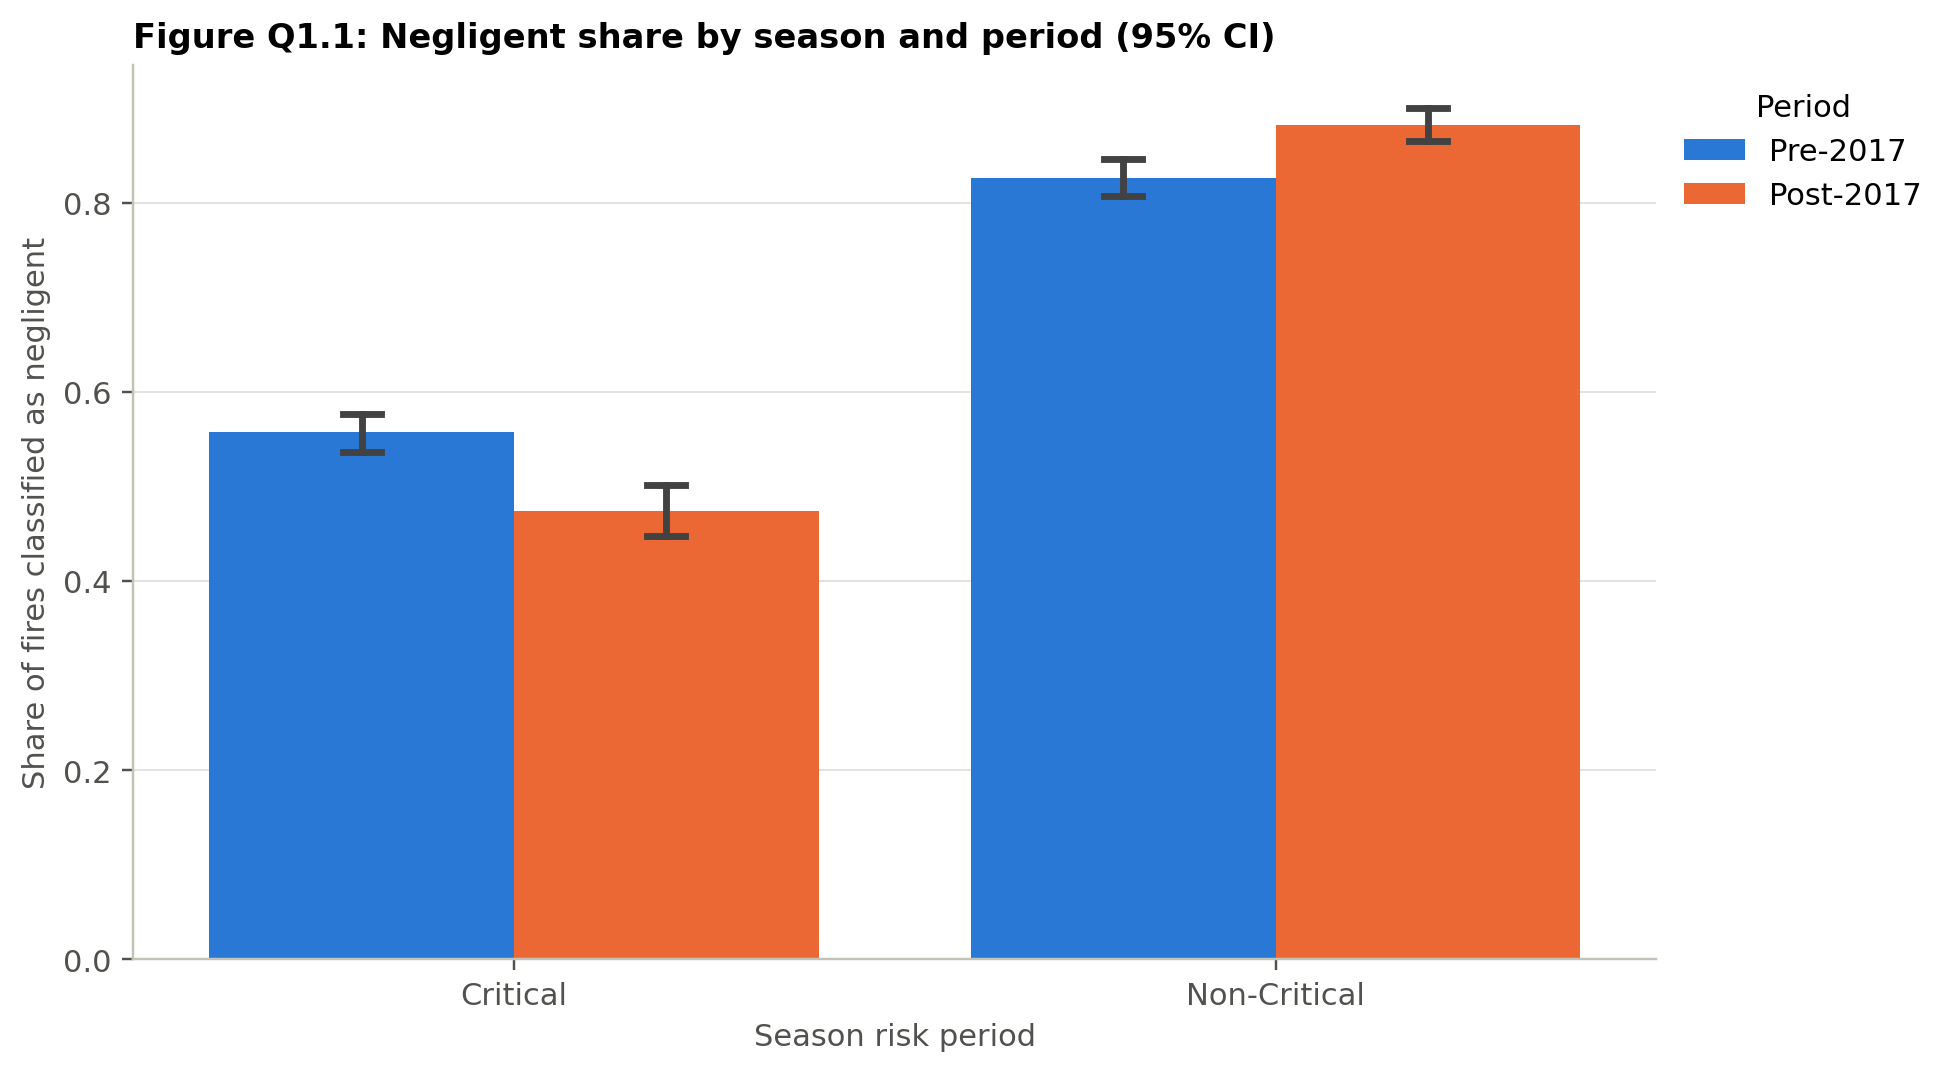

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=q1, x="Season_Risk_Period", y=(q1["Cause_Type"] == "Negligent").astype(int),
    hue="Period", order=SEASON_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD,
    saturation=1, errorbar="ci", capsize=0.1, ax=ax
)
ax.set_title("Figure Q1.1: Negligent share by season and period (95% CI)")
ax.set_xlabel("Season risk period")
ax.set_ylabel("Share of fires classified as negligent")
ax.legend(title="Period", loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

Figure Q1.1 shows the share of negligent fires among human-caused fires before and after 2017, split by season.

In the critical period, the negligent share fell from 55.7% to 47.4%. The 95% confidence intervals do not overlap, which agrees with the significant Z-test in Section 4.1.

In the non-critical period the share was already very high and rose from 82.6% to 88.2%. The change is smaller in percentage points (+5.6 vs. −8.3), but the intervals also do not overlap, and the test in Section 4.1 confirms that this increase is statistically significant.

The two seasons therefore moved in opposite directions.

#### Negligence over time

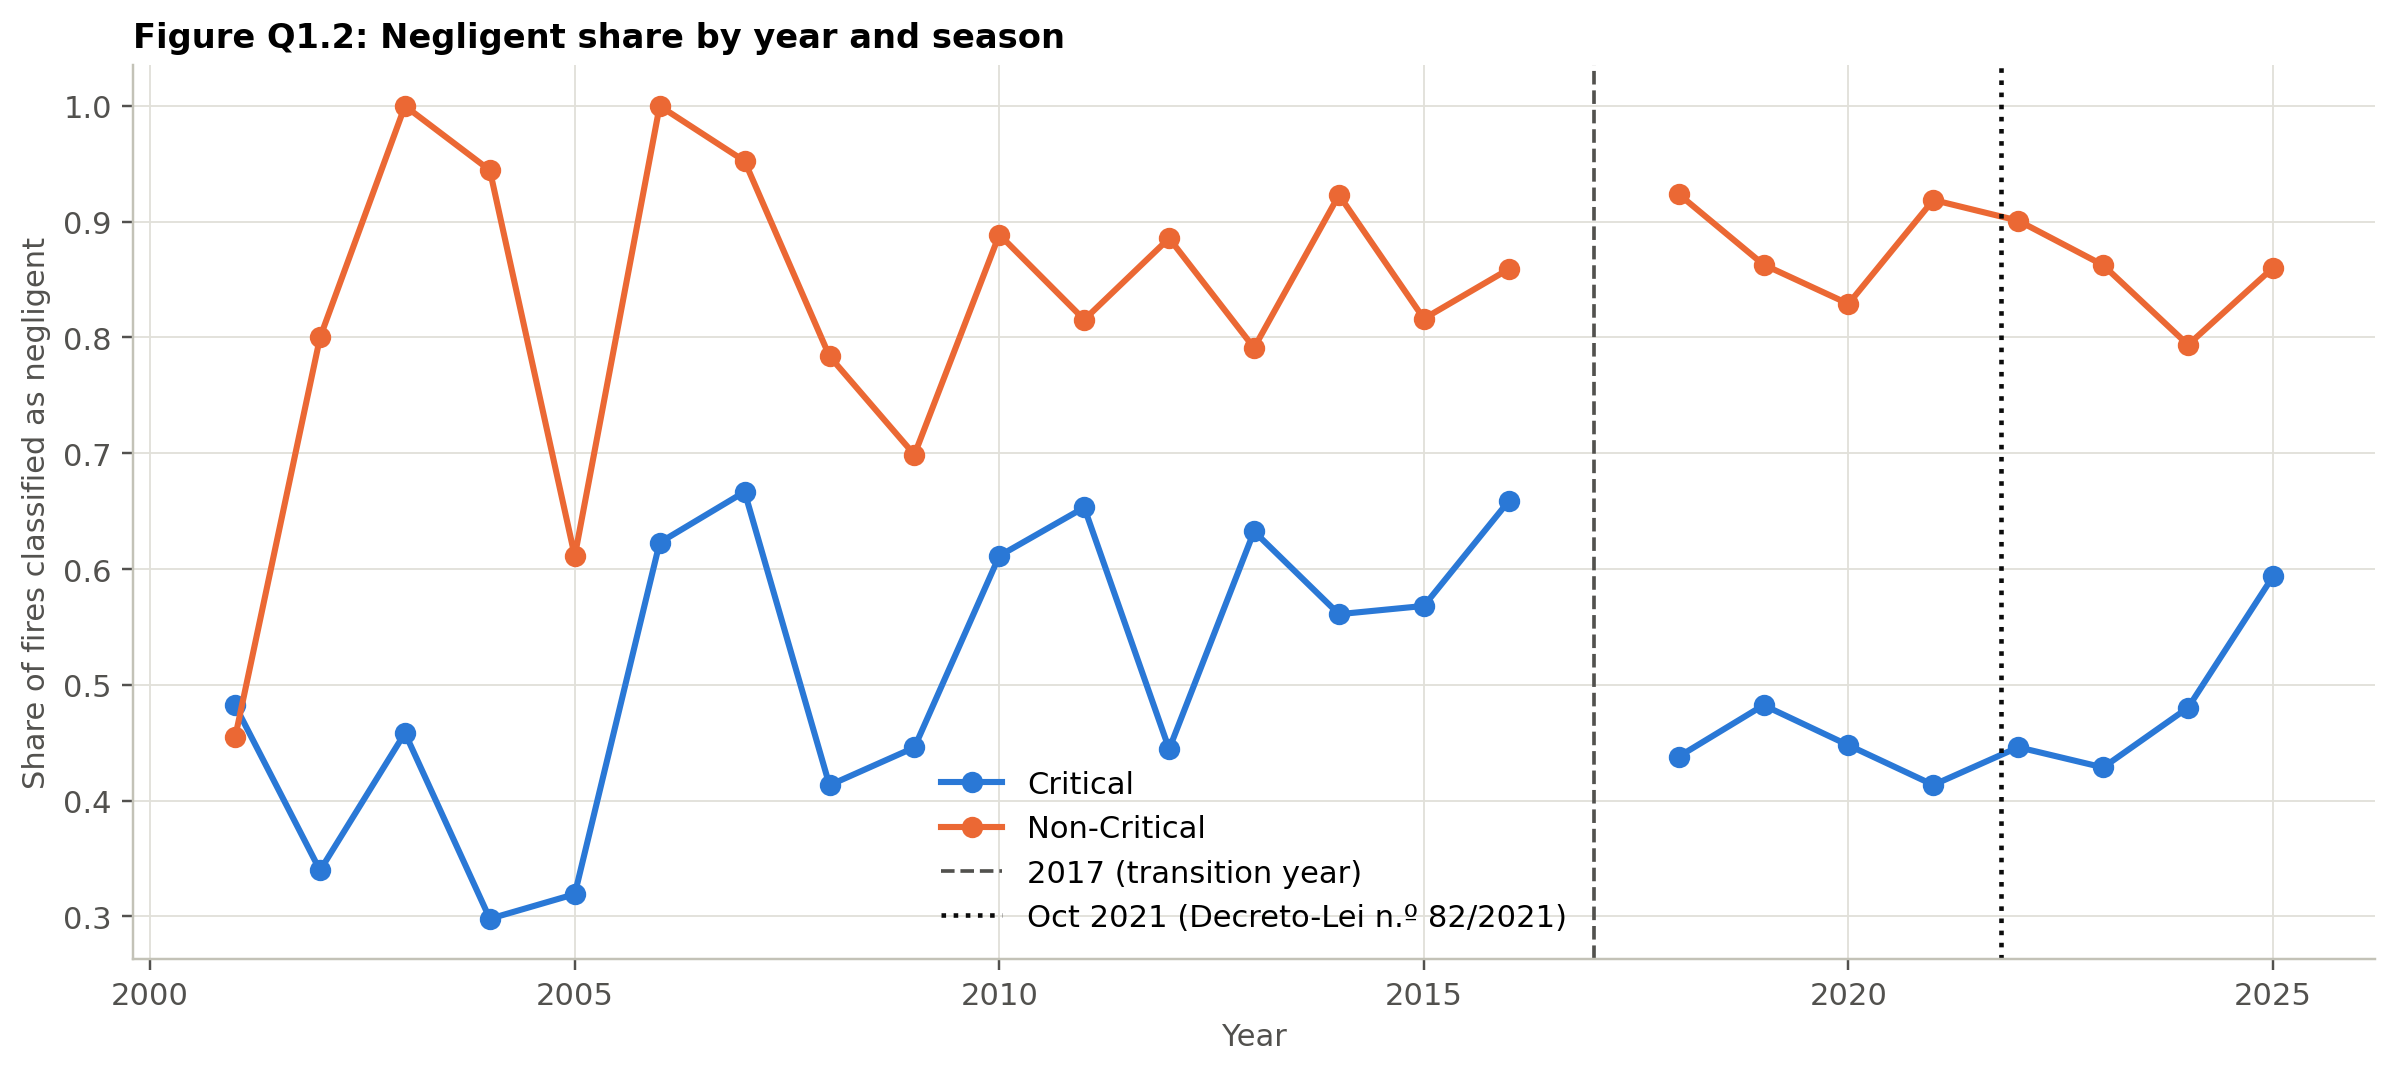

In [16]:
year_season = (
    q1.groupby(["Ano", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)

fig, ax = plt.subplots(figsize=(11, 5))
# pre- and post-2017 are drawn as separate lines, so no line crosses the excluded year 2017
for season in SEASON_ORDER:
    for k, (lo, hi) in enumerate([(2001, 2016), (2018, 2025)]):
        seg = year_season[(year_season["Season_Risk_Period"] == season) & year_season["Ano"].between(lo, hi)]
        ax.plot(seg["Ano"], seg["negligent_share"], color=PAL_SEASON[season], marker="o",
                linewidth=2, label=season if k == 0 else None)
ax.axvline(2017, color=MUTED, linestyle="--", linewidth=1.2, label="2017 (transition year)")
ax.axvline(2021.8, color=INK, linestyle=":", linewidth=1.5, label="Oct 2021 (Decreto-Lei n.º 82/2021)")
ax.set_title("Figure Q1.2: Negligent share by year and season")
ax.set_xlabel("Year")
ax.set_ylabel("Share of fires classified as negligent")
ax.legend(title="")
plt.tight_layout()
plt.show()

#### Summary

The share of negligent fires among fires with a recorded human cause was compared before and after 2017, separately for the critical period (June to September) and for the remaining months. The two seasons moved in opposite directions. In the critical period, the negligent share fell from 55.7% to 47.4%, the result of fewer negligent and more intentional fires per year. In the non-critical months, where negligence was already the dominant cause, it rose from 82.6% to 88.2%, mostly because many more negligent fires were recorded per year. Section 4.1 tests whether these changes, and the difference between them, are statistically significant.

Figure Q1.2 does not show a clear break after Decreto-Lei n.º 82/2021, published in October 2021. If the new system had reduced negligent ignitions, a drop would be expected from 2022 onwards. The non-critical line shows no visible change, and the critical line dips in 2021, before the law could have had any effect, and is back up by 2024 and 2025. Yearly shares are based on few fires in some groups, so this is only a visual impression, and the data cannot attribute any change to a specific policy.

---

### 3.2 Q2: Daily Negligent Ignitions on Weekends and Weekdays

Q1 looked at the balance between negligent and intentional fires across seasons. Q2 looks at the weekly timing of negligent ignitions in the post-2017 period (2018–2025) and asks whether the mean number of daily negligent ignitions differs between weekends and weekdays in Chaves, Montalegre, Ourém and Tomar. A plausible mechanism is that recreational visits and small agricultural burnings by part-time landholders are more frequent at weekends.

The unit of observation is a municipality-day. The file `q2_daily_ignitions.xlsx` contains only the municipality-days with at least one negligent ignition (active days, Y ≥ 1). Days without a record are not missing values. SGIF records every fire, so a municipality-day without a record had zero negligent ignitions. Q2 concerns the mean over all calendar days, E[Y], which is the primary analysis in Section 4.2. The mean on active days, E[Y | Y ≥ 1], is analysed as a complement and is the quantity described below. Pre-2017 values are shown for descriptive context only, because the share of fires with a recorded human cause rose from 36.4% before 2017 to 90.7% after 2017, which makes direct comparisons between periods unreliable.

**Fires with 0 ha.** Negligent ignitions are counted whatever their final burnt area, because Q2 concerns ignitions and not fire size. Only 3 of the 4,349 negligent records in the two periods have 0 ha, so this choice has no practical effect. Because counts are strongly right-skewed, robust measures (median, IQR) are reported next to the mean, standard deviation and skewness.

#### Data

In [17]:
q2 = pd.read_excel(processed / "q2_daily_ignitions.xlsx")

# fixed data types and factor orders
q2["Date"] = pd.to_datetime(q2["Date"])
q2["Period"] = pd.Categorical(q2["Period"], categories=PERIOD_ORDER, ordered=True)
q2["Day_Type"] = pd.Categorical(q2["Day_Type"], categories=DAY_ORDER, ordered=True)

# consistency with the record-level data and share of fires with a recorded human cause
neg_records = df_final[(df_final["Cause_Type"] == "Negligent") & (df_final["Period"] != "Transition")]
assert q2["Daily_Ignitions_Count"].sum() == len(neg_records)
cause_recorded = (df_final[df_final["Period"] != "Transition"]
                  .groupby("Period", observed=False)["Cause_Type"]
                  .apply(lambda s: s.notna().mean()))
print(f"Negligent records (pre- and post-2017): {len(neg_records):,}; "
      f"with 0 ha burnt: {(neg_records['Total_Burnt_Area'] == 0).sum()}")
print(f"Share of fires with a recorded human cause (Intentional or Negligent): "
      f"Pre-2017 = {cause_recorded['Pre-2017']:.1%}, Post-2017 = {cause_recorded['Post-2017']:.1%}")

q2.info()
q2.head()

Negligent records (pre- and post-2017): 4,349; with 0 ha burnt: 3
Share of fires with a recorded human cause (Intentional or Negligent): Pre-2017 = 36.4%, Post-2017 = 90.7%
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2897 entries, 0 to 2896
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Concelho               2897 non-null   object        
 1   Date                   2897 non-null   datetime64[ns]
 2   Period                 2897 non-null   category      
 3   Daily_Ignitions_Count  2897 non-null   int64         
 4   Day_Type               2897 non-null   category      
dtypes: category(2), datetime64[ns](1), int64(1), object(1)
memory usage: 73.9+ KB


,Concelho,Date,Period,Daily_Ignitions_Count,Day_Type
0,Chaves,2001-07-21,Pre-2017,1,Weekend
1,Chaves,2001-07-29,Pre-2017,1,Weekend
2,Chaves,2001-08-10,Pre-2017,1,Weekday
3,Chaves,2001-08-13,Pre-2017,1,Weekday
4,Chaves,2001-08-16,Pre-2017,1,Weekday


#### Descriptive statistics

In [18]:
# Summary statistics by Period and Day_Type (including skewness)
summary_stats = (
    q2.groupby(["Period", "Day_Type"], observed=False)["Daily_Ignitions_Count"]
    .agg(
        n="count",
        mean="mean",
        std="std",
        median="median",
        iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
        min="min",
        max="max",
        skew=lambda x: stats.skew(x),
    )
    .reset_index()
)

# standard error of the mean (SEM)
summary_stats["sem"] = summary_stats["std"] / np.sqrt(summary_stats["n"])

print("Summary statistics for daily negligent ignitions (active days):")
display(summary_stats.round(3))

Summary statistics for daily negligent ignitions (active days):


,Period,Day_Type,n,mean,std,median,iqr,min,max,skew,sem
0,Pre-2017,Weekday,1253,1.505,1.056,1.0,1.0,1,10,3.158,0.030
1,Pre-2017,Weekend,505,1.519,1.067,1.0,1.0,1,8,2.872,0.047
2,Post-2017,Weekday,802,1.455,1.161,1.0,0.0,1,11,4.257,0.041
3,Post-2017,Weekend,337,1.570,1.402,1.0,1.0,1,12,4.025,0.076


#### Distribution of daily negligent ignitions

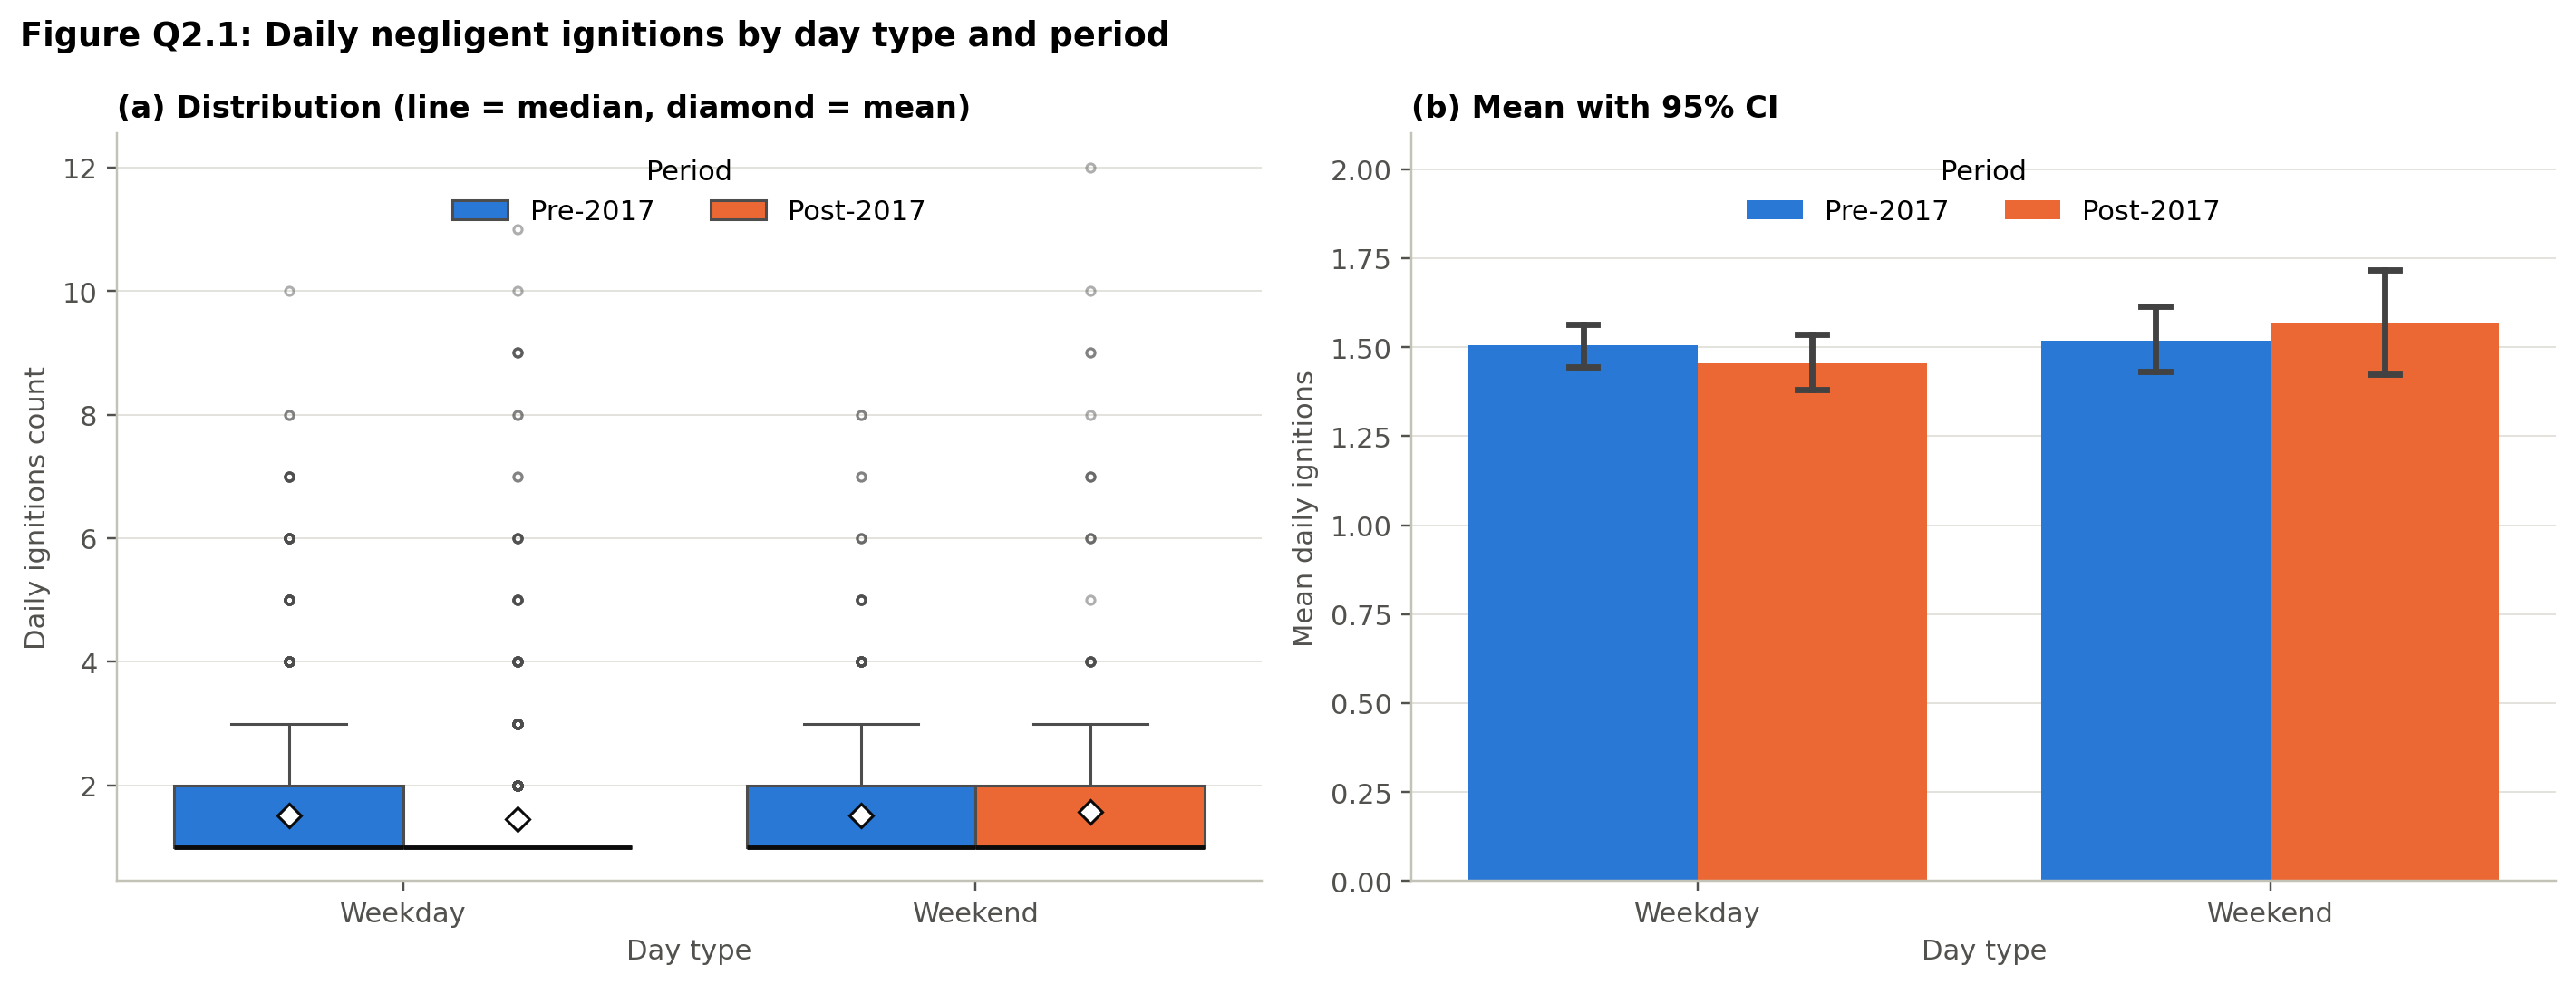

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Boxplot
sns.boxplot(
    data=q2, x="Day_Type", y="Daily_Ignitions_Count", hue="Period",
    order=DAY_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD, saturation=1,
    ax=axes[0], showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": INK, "markersize": 6},
    medianprops={"color": INK, "linewidth": 1.6},
    flierprops={"marker": "o", "markersize": 3, "alpha": .45},
)
axes[0].set_title("(a) Distribution (line = median, diamond = mean)")
axes[0].set_xlabel("Day type")
axes[0].set_ylabel("Daily ignitions count")
axes[0].legend(title="Period", loc="upper center", ncol=2)

# (b) Means with 95% CI
sns.barplot(
    data=q2, x="Day_Type", y="Daily_Ignitions_Count", hue="Period",
    order=DAY_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD, saturation=1,
    errorbar=("ci", 95), capsize=0.1, ax=axes[1]
)
axes[1].set_title("(b) Mean with 95% CI")
axes[1].set_xlabel("Day type")
axes[1].set_ylabel("Mean daily ignitions")
axes[1].set_ylim(0, 2.1)
axes[1].legend(title="Period", loc="upper center", ncol=2)

fig_title(fig, "Figure Q2.1: Daily negligent ignitions by day type and period")
plt.tight_layout()
plt.show()

Figure Q2.1(a) shows that on active days the distribution of daily negligent ignitions is strongly right-skewed in every group (post-2017 skewness of 4.26 on weekdays and 4.02 on weekends). The median is one ignition per day. In the post-2017 weekday group at least 75% of active days had a single ignition, so the IQR is 0, while occasional extreme days reach 11 or 12 ignitions. Figure Q2.1(b) shows that after 2017 the mean on active days is slightly higher on weekends (1.570) than on weekdays (1.455), with largely overlapping 95% confidence intervals.

#### Summary

Across the 2,897 active municipality-days (1,139 after 2017), daily negligent ignition counts are strongly right-skewed and concentrated at one ignition per active day on both weekdays and weekends. In 2018–2025, the mean on active days is 0.115 ignitions per day higher on weekends (1.570, SD = 1.402, n = 337) than on weekdays (1.455, SD = 1.161, n = 802), with overlapping confidence intervals. Section 4.2 tests whether the weekend and weekday means differ, first over all calendar days and then on active days only.

---

### 3.3 Q3: Burnt Area across Municipalities

This section explores Q3, which asks whether the typical burnt area per fire differs between Chaves, Montalegre, Ourém and Tomar in 2018–2025. The unit of observation is one fire (SGIF record), whatever its cause, and the response is `Log_Total_Burnt_Area`, the log10 of the final burnt area in hectares.

**Scale of the conclusions.** For positive areas, 10 raised to the mean of log10(area) is the geometric mean of the area. Q3 therefore compares geometric means, and differences on the log scale become ratios of geometric means. It does not compare arithmetic mean burnt areas in hectares, which are reported only descriptively.

**Why all causes are included.** Q3 compares the size of fires once they have started, which depends mostly on the conditions in each municipality (fuel, terrain, detection and suppression) and much less on why the fire started. Restricting Q3 to fires with a recorded human cause would remove only 254 of the 2,739 fires of 2018–2025 (9.3%: reignitions, unknown and natural causes, and records without a cause), because nearly all fires in this period have a recorded cause. Human influence enters Q3 through the municipalities themselves, which were chosen as contrasting pairs in population density and land use (Section 1). Q4 is the question that compares intentional and negligent fires.

#### Data

The Q3 sample saved in Section 2.3 is read from its file and checked. The assertions stop the notebook if the processed file changes in a way that would invalidate the analysis.

In [20]:
STUDY_YEARS = (2018, 2025)
Y = "Total_Burnt_Area"                               # final burnt area per fire (ha)
LOG = "Log_Total_Burnt_Area"                         # log10(area), response of the ANOVA (Section 2.2)

In [21]:
q3 = pd.read_excel(processed / "q3_burnt_area_municipality.xlsx")
q3["Codigo_SGIF"] = q3["Codigo_SGIF"].astype(str)          # identifiers mix int and str in the Excel file
q3["Concelho"] = pd.Categorical(q3["Concelho"], categories=MUNICIPALITIES)
q3_log = q3[q3[Y] > 0].copy()                                 # log10(area) is undefined for 0 ha

assert q3["Ano"].between(*STUDY_YEARS).all(),               "fires outside 2018-2025"
assert q3[Y].notna().all() and (q3[Y] >= 0).all(),           "missing or negative burnt areas"
assert q3["Codigo_SGIF"].is_unique,                           "duplicated SGIF identifiers"
assert (q3[Y] == q3["AreaTotal_ha"]).all(),                   "Total_Burnt_Area differs from AreaTotal_ha"
assert (q3["Period"] == "Post-2017").all(),                   "Period label inconsistent with Ano"
assert np.allclose(q3_log[LOG], np.log10(q3_log[Y])),         "Log_Total_Burnt_Area differs from log10(area)"
assert len(q3) == 2739, "sample size changed: the numbers reported in the Markdown cells must be updated"

print(f"Q3 sample: {len(q3):,} fires ({q3['Ano'].min()}-{q3['Ano'].max()}) "
      f"-> ANOVA sample (area > 0): {len(q3_log):,}")
print("Fires per municipality:", q3["Concelho"].value_counts(sort=False).to_dict())
print("Causes (TipoCausa):", q3["TipoCausa"].value_counts(dropna=False).to_dict())
print(f"Areas: = 0 ha: {(q3[Y] == 0).sum()} | < 0.01 ha: {(q3[Y] < 0.01).sum()} | "
      f"exactly 0.01 ha: {np.isclose(q3[Y], 0.01).sum()} ({100 * np.isclose(q3[Y], 0.01).mean():.1f}%)")
print("Last alert in the data:", q3["DataHoraAlerta"].max())

# Recording precision of very small fires, by municipality
small = pd.DataFrame({"exactly 0.01 ha": np.isclose(q3[Y], 0.01), "below 0.01 ha": q3[Y] < 0.01})
print(small.groupby(q3["Concelho"], observed=True).sum().T.to_string())

Q3 sample: 2,739 fires (2018-2025) -> ANOVA sample (area > 0): 2,738
Fires per municipality: {'Chaves': 555, 'Montalegre': 1146, 'Ourém': 620, 'Tomar': 418}
Causes (TipoCausa): {'Negligente': 1696, 'Intencional': 789, 'Reacendimento': 130, 'Desconhecida': 98, 'Natural': 14, nan: 12}
Areas: = 0 ha: 1 | < 0.01 ha: 312 | exactly 0.01 ha: 315 (11.5%)
Last alert in the data: 2025-11-04 18:49:00
Concelho         Chaves  Montalegre  Ourém  Tomar
exactly 0.01 ha     126         181      5      3
below 0.01 ha        33          38    141    100


The Q3 sample is defined by the following decisions.

- **All causes are kept.** This includes reignitions (130 records), for the reasons given at the start of this section. Each record has its own SGIF code and burnt area.
- **No outliers are removed.** Very large fires are a genuine feature of the distribution; the log scale limits their influence on the test.
- **The fire with 0 ha is excluded from the log scale.** The log-scale analysis uses 2,738 fires, and the descriptive statistics use all 2,739.
- **0.01 ha is not a recording threshold.** It is the most frequent recorded value (315 fires, 11.5%), but 312 fires have smaller areas.
- **Recording precision differs between municipalities.** Very small fires are mostly recorded as exactly 0.01 ha in Chaves and Montalegre (126 and 181 records, against 33 and 38 below 0.01 ha), whereas Ourém and Tomar record them more precisely, often below 0.01 ha (141 and 100 records, against 5 and 3 at exactly 0.01 ha). Because the log scale magnifies differences among very small areas, part of the gap in geometric means may reflect recording practice. The robustness checks of Section 4.3 (Appendix A.2) therefore repeat the analysis with all areas below 0.01 ha set to 0.01 ha.
- **2025 is incomplete.** The last alert is in early November 2025; its influence is checked in the same robustness checks.

#### Descriptive statistics

Descriptive statistics use the original scale (hectares). The geometric mean, 10 raised to the mean of log10(area), is the quantity compared by the ANOVA; it is computed from fires with area > 0 (in Ourém, 619 of 620). The share of area in the five largest fires is given per municipality only.

In [22]:
def describe(a):
    a = pd.Series(a)
    return pd.Series({"n": len(a), "mean": a.mean(), "sd": a.std(), "Q1": a.quantile(.25), "median": a.median(),
                      "Q3": a.quantile(.75), "max": a.max(), "geometric mean": 10 ** np.log10(a[a > 0]).mean(),
                      "% fires < 1 ha": 100 * (a < 1).mean(),
                      "% of area in 5 largest fires": 100 * a.nlargest(5).sum() / a.sum()})

summary = pd.DataFrame({m: describe(q3.loc[q3["Concelho"] == m, Y]) for m in MUNICIPALITIES}).T
summary.loc["All"] = describe(q3[Y])
summary.loc["All", "% of area in 5 largest fires"] = np.nan      # not comparable with the per-municipality values
summary["n"] = summary["n"].astype(int)
display(summary.round(3))

areas = q3[Y].sort_values(ascending=False)
n_top = int(np.ceil(0.01 * len(areas)))
print(f"The largest 1% of fires ({n_top}) account for {100 * areas.iloc[:n_top].sum() / areas.sum():.1f}% of the total "
      f"burnt area; overall mean / median = {areas.mean() / areas.median():.0f}")

,n,mean,sd,Q1,median,Q3,max,geometric mean,% fires < 1 ha,% of area in 5 largest fires
Chaves,555,18.125,191.871,0.010,0.158,0.962,3367.930,0.139,75.315,82.621
Montalegre,1146,13.682,130.046,0.100,0.772,3.038,4147.733,0.505,66.492,39.959
Ourém,620,13.869,159.285,0.012,0.054,0.196,2936.000,0.051,89.516,83.682
Tomar,418,3.172,35.486,0.010,0.045,0.202,606.525,0.041,93.780,91.268
All,2739,13.021,143.072,0.017,0.162,0.900,4147.733,0.158,77.656,NaN


The largest 1% of fires (28) account for 71.2% of the total burnt area; overall mean / median = 80


#### Distribution of burnt area by municipality

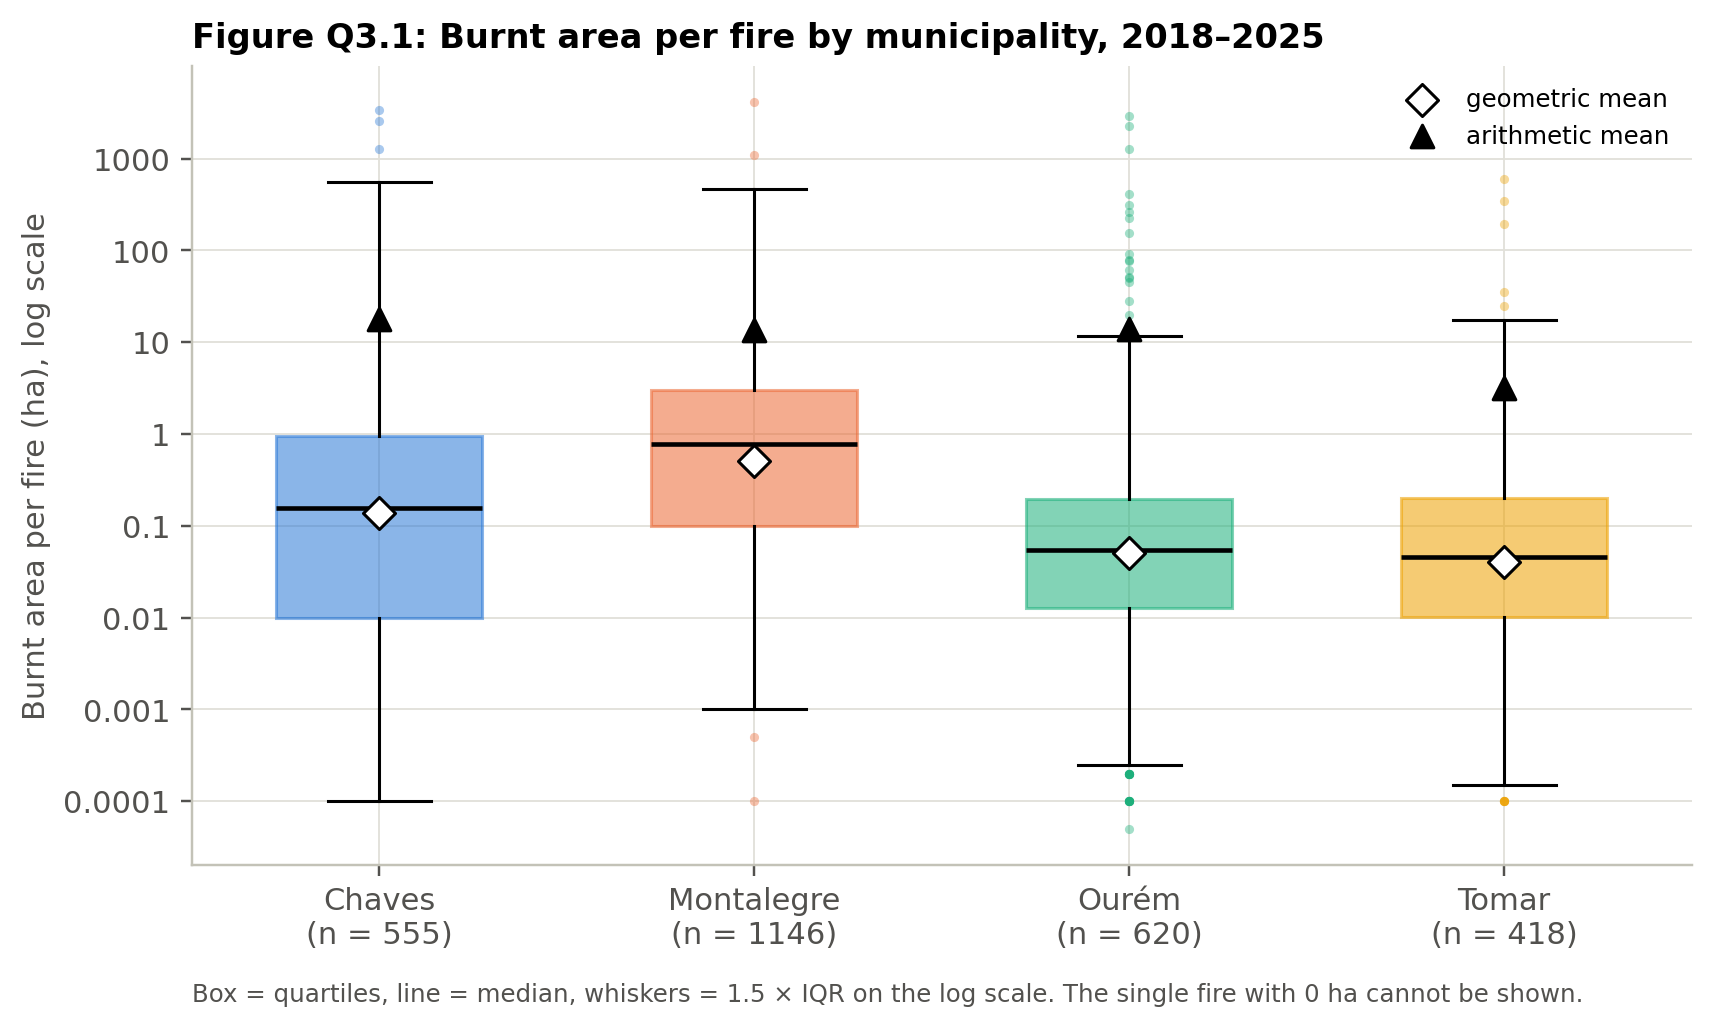

In [23]:
# Figure Q3.1 - distribution of burnt area per fire by municipality.
# The boxplot is computed on log10(area), so whiskers and outliers follow the scale of the analysis.
groups = [np.log10(q3.loc[(q3["Concelho"] == m) & (q3[Y] > 0), Y]) for m in MUNICIPALITIES]
fig, ax = plt.subplots(figsize=(8, 4.8))
bp = ax.boxplot(groups, patch_artist=True, widths=0.55, medianprops=dict(color="black", linewidth=1.5),
                flierprops=dict(marker="o", markersize=3, alpha=.4, markeredgewidth=0))
for patch, fl, m in zip(bp["boxes"], bp["fliers"], MUNICIPALITIES):
    patch.set(facecolor=PAL_MUN[m], alpha=.55, edgecolor=PAL_MUN[m])
    fl.set(markerfacecolor=PAL_MUN[m])
ax.scatter(range(1, 5), np.log10(summary.loc[MUNICIPALITIES, "geometric mean"]), marker="D", s=55,
           facecolor="white", edgecolor="black", zorder=4, label="geometric mean")
ax.scatter(range(1, 5), np.log10(summary.loc[MUNICIPALITIES, "mean"]), marker="^", s=55,
           color="black", zorder=4, label="arithmetic mean")
ax.set_xticks(range(1, 5), [f"{m}\n(n = {int(summary.loc[m, 'n'])})" for m in MUNICIPALITIES])
ticks = np.arange(-4, 4)
ax.set_yticks(ticks, [f"{10.0 ** t:g}" for t in ticks])
ax.set_ylabel("Burnt area per fire (ha), log scale")
ax.set_title("Figure Q3.1: Burnt area per fire by municipality, 2018–2025")
ax.legend(frameon=False, loc="upper right", fontsize=8)
ax.text(0, -0.17, "Box = quartiles, line = median, whiskers = 1.5 × IQR on the log scale. "
        "The single fire with 0 ha cannot be shown.", transform=ax.transAxes, fontsize=8, color=MUTED)
plt.tight_layout()
plt.show()

Burnt area is extremely right-skewed: 77.7% of the fires burnt less than 1 ha, while the largest 1% (28 fires) account for 71.2% of the total burnt area, and the overall arithmetic mean (13.0 ha) is about 80 times the median (0.16 ha). The arithmetic means rank the municipalities Chaves > Ourém > Montalegre > Tomar, whereas the medians and geometric means rank them Montalegre > Chaves > Ourém > Tomar. The difference arises because each arithmetic mean depends on a handful of fires: the five largest fires hold between 40% (Montalegre) and 91% (Tomar) of each municipality's burnt area (Figure Q3.1, triangles far above the boxes). A comparison of arithmetic means would therefore mostly reflect a few extreme events.

#### Summary

In 2018–2025, burnt area per fire is extremely right-skewed in all four municipalities, so each arithmetic mean depends on a handful of very large fires and ranks the municipalities differently from the medians and geometric means. On the log scale used in the ANOVA, the typical fire is largest in Montalegre (geometric mean 0.50 ha), followed by Chaves (0.14 ha), Ourém (0.05 ha) and Tomar (0.04 ha). The recording precision of very small fires differs between the two regions, which may widen the gap between them. Section 4.3 tests whether the geometric means differ.

---

### 3.4 Q4: Burnt Area by Cause Type and Period

This section explores Q4, which asks whether the gap in final burnt area between intentional and negligent fires became smaller after 2017 in the four municipalities under study.

The burnt area is analysed on a log10 scale because it is extremely right-skewed, with most fires below 1 ha and a few above 1,000 ha. Following the rule in Section 2.3, the 3 fires with 0 ha are excluded, so no constant is added before taking the logarithm. The back-transformed mean, 10^mean, is therefore the geometric mean of the burnt area, which describes the typical fire much better than the arithmetic mean.

#### Data

In [24]:
q4 = pd.read_excel(processed / "q4_burnt_area_cause_period.xlsx")

# fixed order of the factor levels for tables and plots
q4["Period"] = pd.Categorical(q4["Period"], categories=PERIOD_ORDER, ordered=True)
q4["Cause_Type"] = pd.Categorical(q4["Cause_Type"], categories=CAUSE_ORDER, ordered=True)

pd.crosstab(q4["Cause_Type"], q4["Period"], margins=True)

Period,Pre-2017,Post-2017,All
Cause_Type,,,
Intentional,1381,789,2170
Negligent,2651,1695,4346
All,4032,2484,6516


#### Descriptive statistics

In [25]:
q4_desc = (
    q4.groupby(["Period", "Cause_Type"], observed=True)
      .agg(n=("Log_Total_Burnt_Area", "size"),
           mean_log=("Log_Total_Burnt_Area", "mean"),
           sd_log=("Log_Total_Burnt_Area", "std"),
           median_ha=("Total_Burnt_Area", "median"),
           mean_ha=("Total_Burnt_Area", "mean"))
)
# geometric mean in hectares (back-transformation of the mean of log10(area))
q4_desc["geom_mean_ha"] = 10 ** q4_desc["mean_log"]
q4_desc.round(3)

n  mean_log  sd_log  median_ha  mean_ha  \
Period    Cause_Type                                                
Pre-2017  Intentional  1381    -0.580   1.272      0.260   24.761   
          Negligent    2651    -0.414   1.149      0.500    8.628   
Post-2017 Intentional   789    -0.991   1.281      0.085   23.227   
          Negligent    1695    -0.664   1.221      0.290    8.731   

                       geom_mean_ha  
Period    Cause_Type                 
Pre-2017  Intentional         0.263  
          Negligent           0.385  
Post-2017 Intentional         0.102  
          Negligent           0.217

The design is unbalanced (from 789 to 2,651 fires per group), but every group is large. The table also shows why the log scale is needed. Intentional fires have a much higher arithmetic mean (around 23 to 25 ha vs. 9 ha), but a lower median (0.26 vs. 0.50 ha before 2017), because a few very large intentional fires inflate the mean. The geometric means (0.10 to 0.39 ha) are of the same order of magnitude as the medians (0.09 to 0.50 ha) and, unlike the arithmetic means, show negligent fires as larger than intentional fires in both periods.

#### Distribution of burnt area by group

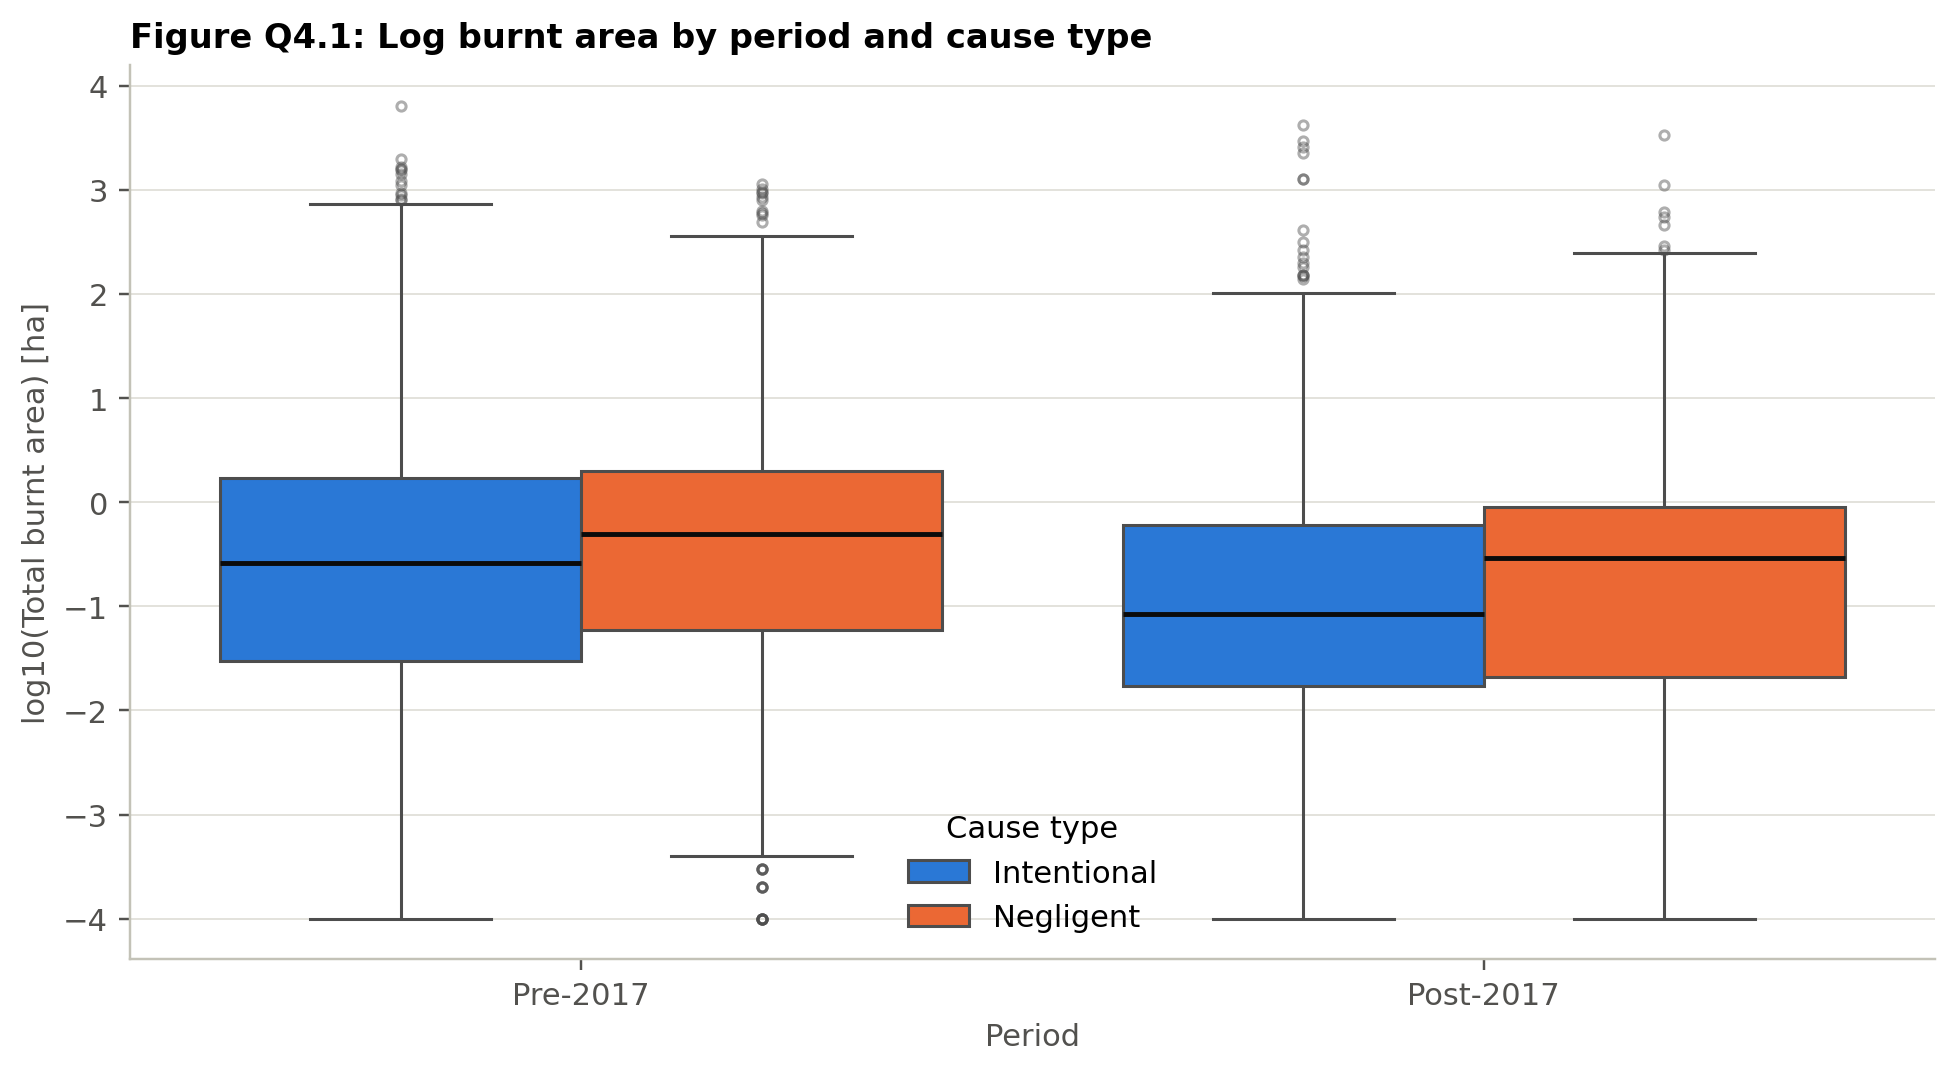

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=q4, x="Period", y="Log_Total_Burnt_Area", hue="Cause_Type",
            order=PERIOD_ORDER, hue_order=CAUSE_ORDER, palette=PAL_CAUSE, saturation=1,
            medianprops={"color": INK, "linewidth": 1.6},
            flierprops={"marker": "o", "markersize": 3, "alpha": .45}, ax=ax)
ax.set_title("Figure Q4.1: Log burnt area by period and cause type")
ax.set_ylabel("log10(Total burnt area) [ha]")
ax.set_xlabel("Period")
ax.legend(title="Cause type")
plt.tight_layout()
plt.show()

In [27]:
# Numbers behind Figure Q4.1 (boxplot statistics on the log scale)
box_rows = []
for (cause, period), g in q4.groupby(["Cause_Type", "Period"], observed=True):
    x = g["Log_Total_Burnt_Area"]
    area = g["Total_Burnt_Area"]
    lo, med, hi = x.quantile([0.25, 0.5, 0.75])
    iqr = hi - lo
    box_rows.append({
        "Cause_Type": cause,
        "Period": period,
        "min": x.min(),
        "lower_whisker": x[x >= lo - 1.5 * iqr].min(),
        "Q1": lo,
        "median": med,
        "Q3": hi,
        "upper_whisker": x[x <= hi + 1.5 * iqr].max(),
        "max": x.max(),
        "n_outliers_upper": (x > hi + 1.5 * iqr).sum(),
        "n_outliers_lower": (x < lo - 1.5 * iqr).sum(),
        "n_0.01_ha": (area == 0.01).sum(),
    })
pd.DataFrame(box_rows).round(3)

,Cause_Type,Period,min,lower_whisker,Q1,median,Q3,upper_whisker,max,n_outliers_upper,n_outliers_lower,n_0.01_ha
0,Intentional,Pre-2017,-4.0,-4.000,-1.523,-0.585,0.230,2.859,3.805,12,0,76
1,Intentional,Post-2017,-4.0,-4.000,-1.770,-1.071,-0.222,2.008,3.618,16,0,32
2,Negligent,Pre-2017,-4.0,-3.398,-1.228,-0.301,0.301,2.556,3.060,10,15,268
3,Negligent,Post-2017,-4.0,-4.000,-1.675,-0.538,-0.046,2.394,3.527,7,0,229


In [28]:
# Most frequent burnt area values (in ha)
q4["Total_Burnt_Area"].value_counts().head(6)

Total_Burnt_Area
0.01    605
0.50    442
1.00    375
2.00    227
0.10    193
1.50    166
Name: count, dtype: int64

Figure Q4.1 shows that the four distributions overlap heavily, as expected for a variable with high natural variability. Even so, the median of negligent fires is higher than that of intentional fires in both periods (−0.30 vs. −0.59 before 2017 and −0.54 vs. −1.07 after 2017), and all medians are lower after 2017. The lower whiskers reach −4 in three groups because of very small fires recorded with 0.0001 ha; among negligent fires before 2017, these fires appear as 15 lower outliers. Areas are often recorded as rounded values, and 0.01 ha is the most frequent value (605 fires).

#### Interaction plot

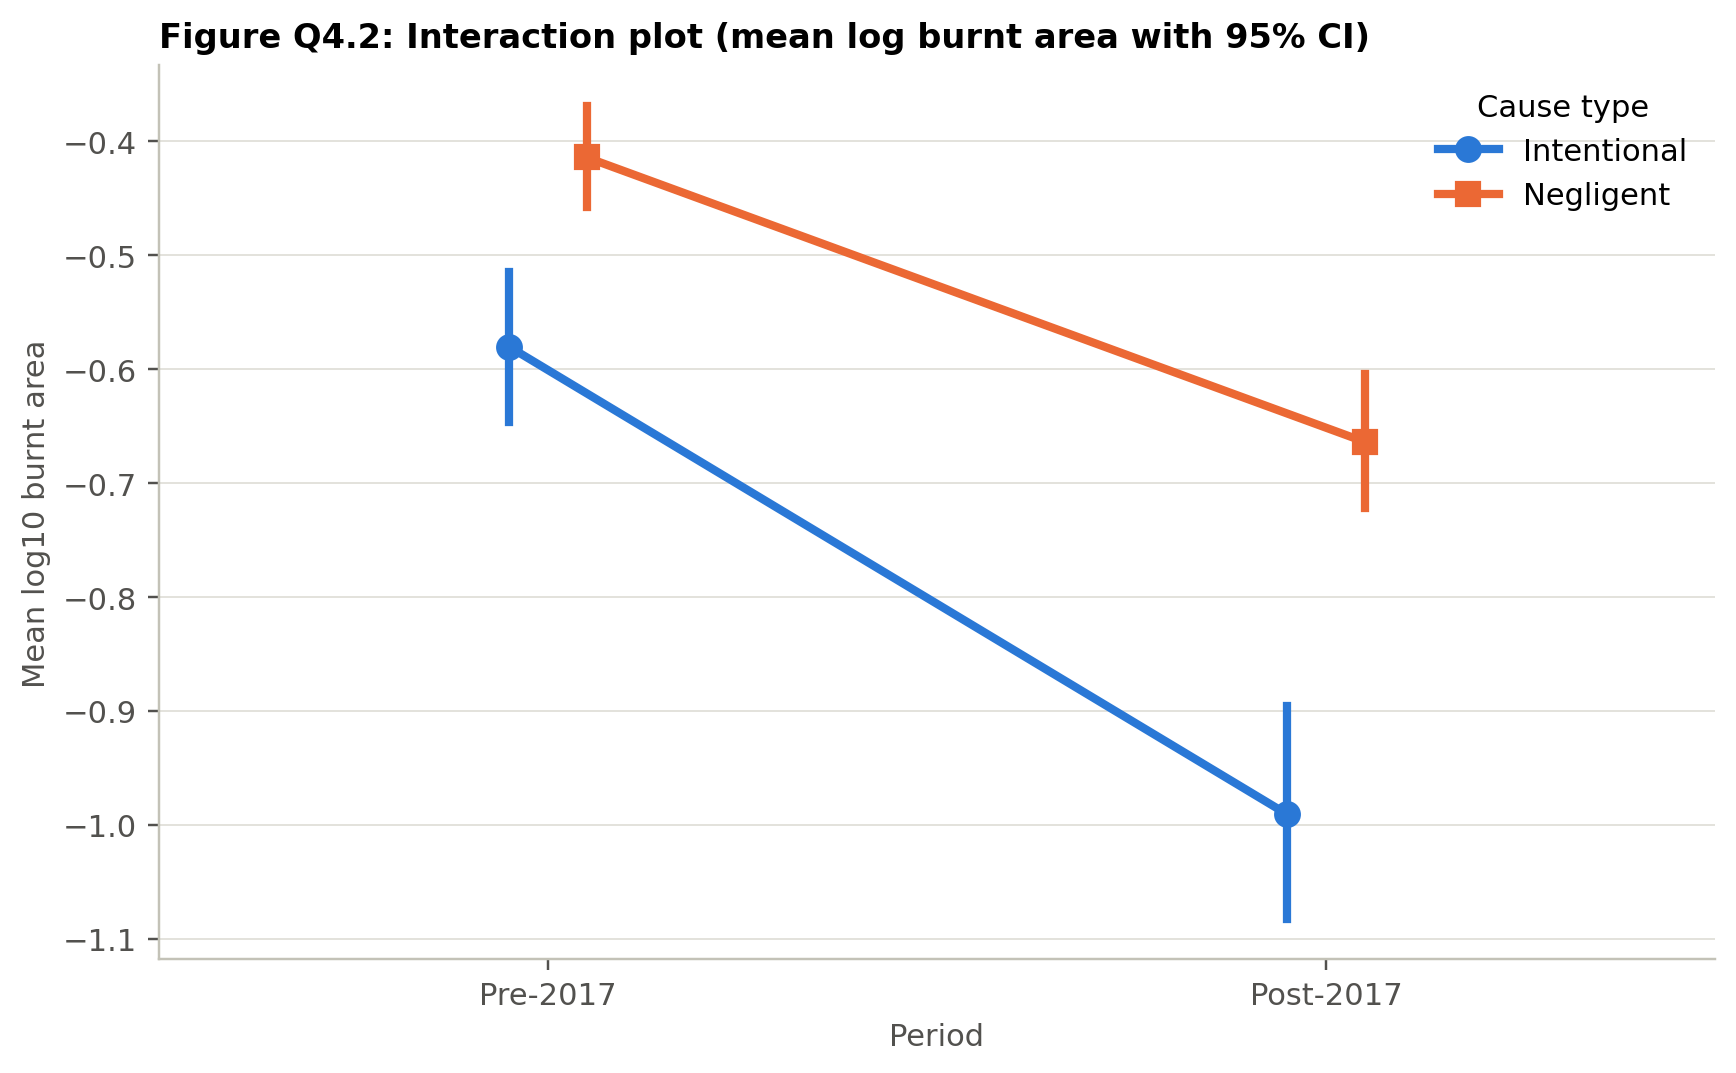

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.pointplot(data=q4, x="Period", y="Log_Total_Burnt_Area", hue="Cause_Type",
              order=PERIOD_ORDER, hue_order=CAUSE_ORDER, palette=PAL_CAUSE,
              errorbar=("ci", 95), dodge=0.1, markers=["o", "s"], ax=ax)
ax.set_title("Figure Q4.2: Interaction plot (mean log burnt area with 95% CI)")
ax.set_ylabel("Mean log10 burnt area")
ax.set_xlabel("Period")
ax.legend(title="Cause type")
plt.tight_layout()
plt.show()

In [30]:
# Numbers behind Figure Q4.2
q4_means = (
    q4.groupby(["Period", "Cause_Type"], observed=True)["Log_Total_Burnt_Area"]
      .agg(n="size", mean="mean", sd="std")
)
q4_means["se"] = q4_means["sd"] / np.sqrt(q4_means["n"])
t_crit_q4 = stats.t.ppf(0.975, q4_means["n"] - 1)
q4_means["ci_low"] = q4_means["mean"] - t_crit_q4 * q4_means["se"]
q4_means["ci_high"] = q4_means["mean"] + t_crit_q4 * q4_means["se"]
display(q4_means.round(3))

mean_tab = q4_means["mean"].unstack()
drop = mean_tab.loc["Pre-2017"] - mean_tab.loc["Post-2017"]
gap = mean_tab["Negligent"] - mean_tab["Intentional"]
print("Drop after 2017 (log units):")
print(drop.round(3))
print("\nGap Negligent - Intentional (log units):")
print(gap.round(3))
print(f"\nChange in the gap: {gap['Post-2017'] - gap['Pre-2017']:.3f}")

n   mean     sd     se  ci_low  ci_high
Period    Cause_Type                                             
Pre-2017  Intentional  1381 -0.580  1.272  0.034  -0.647   -0.513
          Negligent    2651 -0.414  1.149  0.022  -0.458   -0.371
Post-2017 Intentional   789 -0.991  1.281  0.046  -1.080   -0.901
          Negligent    1695 -0.664  1.221  0.030  -0.722   -0.606

Drop after 2017 (log units):
Cause_Type
Intentional    0.41
Negligent      0.25
dtype: float64

Gap Negligent - Intentional (log units):
Period
Pre-2017     0.166
Post-2017    0.327
dtype: float64

Change in the gap: 0.161


Figure Q4.2 is the most direct visual answer to the research question. If the gap between causes had narrowed after 2017, the two lines would converge. Instead, they move slightly apart. The mean for intentional fires drops by 0.41 log units (from −0.58 to −0.99), while the mean for negligent fires drops by 0.25 (from −0.41 to −0.66). As a result, the gap between causes goes from 0.17 to 0.33 log units, an increase of 0.16.

#### Fire weather and burnt area

Fires with FWI: 6,476 of 6,516


n   mean     sd  median
Period    Cause_Type                             
Pre-2017  Intentional  1381  28.46  13.04   29.15
          Negligent    2625  18.75  12.94   16.65
Post-2017 Intentional   788  30.32  15.40   30.98
          Negligent    1682  14.57  13.03    9.35

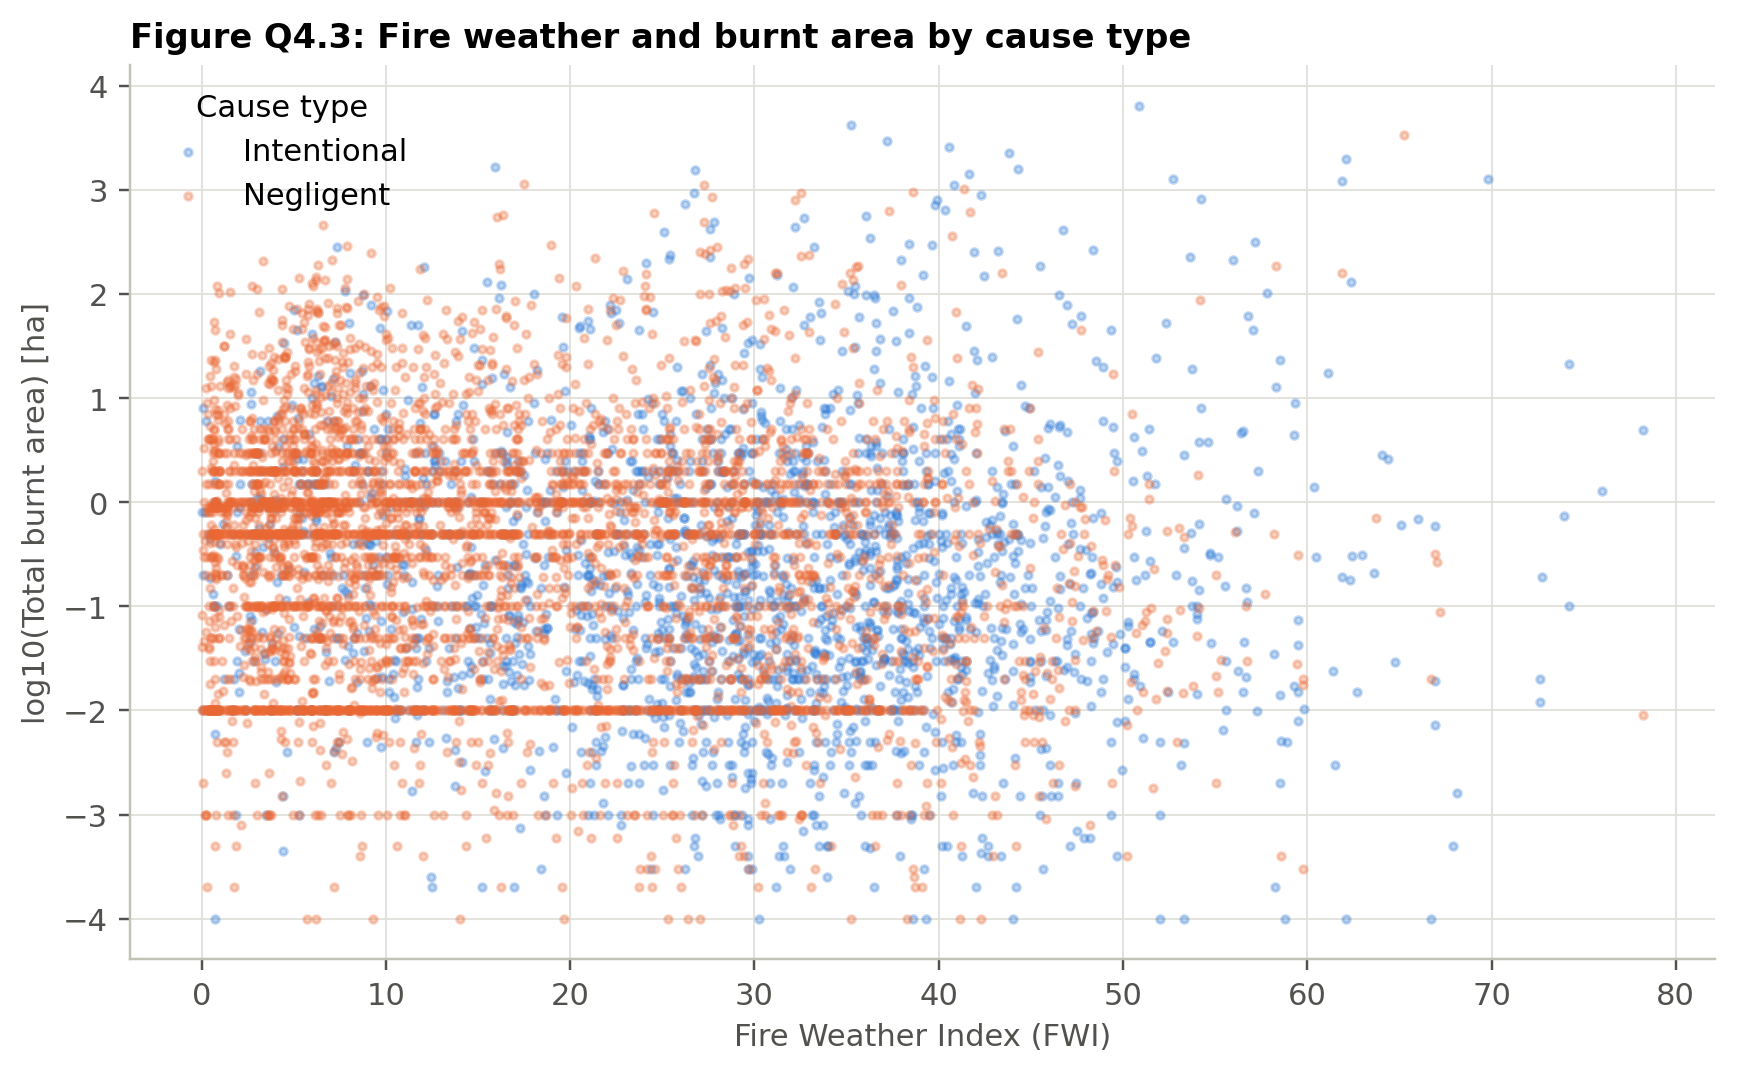

In [31]:
q4_fwi = q4.dropna(subset=["FWI"]).copy()
print(f"Fires with FWI: {len(q4_fwi):,} of {len(q4):,}")

display(q4_fwi.groupby(["Period", "Cause_Type"], observed=True)["FWI"]
              .agg(n="count", mean="mean", sd="std", median="median").round(2))

fig, ax = plt.subplots(figsize=(8, 5))
for cause in CAUSE_ORDER:
    g = q4_fwi[q4_fwi["Cause_Type"] == cause]
    ax.scatter(g["FWI"], g["Log_Total_Burnt_Area"], s=6, alpha=0.3, color=PAL_CAUSE[cause], label=cause)
ax.set_xlabel("Fire Weather Index (FWI)")
ax.set_ylabel("log10(Total burnt area) [ha]")
ax.set_title("Figure Q4.3: Fire weather and burnt area by cause type")
ax.legend(title="Cause type")
plt.tight_layout()
plt.show()

Intentional fires start on days of much higher fire danger than negligent fires (mean FWI of 28.5 and 30.3, against 18.8 and 14.6), which is consistent with negligent fires being concentrated in the cooler non-critical months (Q1). After 2017, the mean FWI rose slightly for intentional fires and fell for negligent fires. Figure Q4.3 shows no clear increase in burnt area with FWI: fires of every size occur across the whole range, and the horizontal bands are the rounded areas (0.01, 0.1, 0.5 and 1 ha) discussed above.

#### Summary

The descriptive analysis suggests that the gap between causes did not narrow after 2017. In both periods, the typical negligent fire burnt a larger area than the typical intentional fire, and all groups had smaller fires after 2017. Intentional fires decreased more, so the two lines in Figure Q4.2 move slightly apart. Whether these differences are statistically significant is tested in Section 4.4.

---

<a id="4-draw-inferences"></a>
## 4) Draw Inferences

#### Assumptions shared by all tests

All four questions use observational records, so the three assumptions shared by the tests are discussed once here and only referred to in each section.

**Independence.** Each record is a separate fire (or, in Q2, a separate municipality-day), but records are not fully independent. Fires on the same day or in the same season share weather and fuel conditions, neighbouring municipalities (Chaves and Montalegre, Ourém and Tomar) are exposed to the same weather systems, and some records are reignitions of earlier fires. Independence cannot be tested from the data. If observations are positively correlated, the standard errors are too small and the p-values too low. For this reason, effect sizes are reported next to the p-values, Q2 and Q3 repeat their main test with standard errors clustered by date, and in Q4 the trend and step model uses standard errors clustered by year.

**Normality of the sample means.** None of the response variables is normally distributed. Daily counts are discrete and right-skewed, and burnt area is only approximately symmetric on the log scale. All tests compare means or proportions, and every group has at least several hundred observations, so by the Central Limit Theorem the sampling distribution of each mean or proportion is approximately normal, although strong skewness slows this convergence. The shape of the data, which differs from question to question, is checked in each section.

**Equal variances.** Levene's test and its median-centred version (Brown-Forsythe) are reported, but with several hundred observations per group they detect differences too small to matter in practice. The decision is therefore based on the ratio of the largest to the smallest group standard deviation. When this ratio is below 2, the methods that assume equal variances are adequate (Moore et al., 2017). Q2 uses Welch's t-test directly, which does not assume equal variances. In Q3 and Q4 the classical ANOVA is used when the ratio is below 2, and a version that does not assume equal variances is reported as a check (Welch's ANOVA in Q3 and heteroscedasticity-consistent standard errors in Q4).

### 4.1 Q1: Z-test for Proportions and Chi-square Tests

This section tests whether the proportion of negligent fires among human-caused fires changed after 2017 in each season, and whether the change was the same in the critical and in the non-critical months. A two-proportion Z-test is run separately for each season, the equivalent chi-square test adds the odds ratio as an effect size, and the Breslow-Day test compares the two seasons directly. If the reduction in negligent causes was concentrated in the critical period, a significant drop would be expected in the critical period and no significant change, or an increase, in the non-critical period.

#### Terminology

- **$Y$**: whether a human-caused fire is negligent ($Y = 1$) or intentional ($Y = 0$), for the 6,519 fires with a classified cause in Chaves, Montalegre, Ourém and Tomar.
- **$p_1$** and **$p_2$**: the proportion of negligent fires in the Pre-2017 and in the Post-2017 period, within one season.
- **$n_1$** and **$n_2$**: the number of human-caused fires in the Pre-2017 and in the Post-2017 period, within one season.
- **$OR_s$**: the odds ratio of a fire being negligent, Post-2017 versus Pre-2017, in season $s$ (Critical or Non-Critical), where the odds are negligent / intentional. $OR_s < 1$ means that negligent fires became relatively less common after 2017, and $OR_s > 1$ that they became more common.
- **$\alpha$**: the significance level, set at 0.05.

#### Hypotheses

**Change within each season** (tested separately in each season $s$)

- **H₀:** $p_1 = p_2$, which is equivalent to $OR_s = 1$ (the proportion of negligent fires is the same before and after 2017).
- **H₁:** $p_1 \neq p_2$, which is equivalent to $OR_s \neq 1$ (the proportion of negligent fires changed after 2017).

**Difference between seasons** (`Period × Season_Risk_Period` interaction)

- **H₀:** $OR_{Critical} = OR_{Non\text{-}Critical}$ (the change after 2017 is the same in both seasons).
- **H₁:** $OR_{Critical} \neq OR_{Non\text{-}Critical}$ (the change after 2017 differs between seasons).

#### Checking the assumptions

1. **Independence.** See the shared assumptions at the start of Section 4. Unlike Q2, Q3 and the trend and step model of Q4, Q1 does not use clustered standard errors (Section 6.1).
2. **Large sample size.** The Z-test requires at least 10 successes and 10 failures per group, and the chi-square tests require expected counts of at least 5. The smallest observed count in the 2 × 2 × 2 table is 150 (Post-2017, Non-Critical, Intentional) and the smallest expected count is 188, so all the approximations are reliable.

#### Two-proportion Z-test

The number of negligent fires is the number of successes, and the number of human-caused fires is the sample size for each period and season. The pre-2017 period covers 16 years and the post-2017 period 8, so raw counts are not directly comparable, and the test compares proportions. A Z-test is run for each season separately.

- **Critical period.** Pre-2017 ($n_1 = 2531$) vs. Post-2017 ($n_2 = 1215$).
- **Non-critical period.** Pre-2017 ($n_1 = 1503$) vs. Post-2017 ($n_2 = 1270$).

The sample proportions are

$$
\hat p_{pre} = \frac{x_{pre}}{n_{pre}}
\qquad
\hat p_{post} = \frac{x_{post}}{n_{post}}
$$

In [32]:
# Aggregated counts
counts = (
    q1.assign(Negligent=(q1["Cause_Type"] == "Negligent"))
      .groupby(["Season_Risk_Period", "Period"])["Negligent"]
      .agg(negligent="sum", total="size")
)

SEASON_KEYS = {"Critical": "Critical", "Non-Critical": "Non-critical"}

data = {
    key: {
        "pre_negligent":  int(counts.loc[(season, "Pre-2017"),  "negligent"]),
        "pre_total":      int(counts.loc[(season, "Pre-2017"),  "total"]),
        "post_negligent": int(counts.loc[(season, "Post-2017"), "negligent"]),
        "post_total":     int(counts.loc[(season, "Post-2017"), "total"]),
    }
    for season, key in SEASON_KEYS.items()
}

# checking if the four groups cover every fire
assert sum(v["pre_total"] + v["post_total"] for v in data.values()) == len(q1)

# Observed proportions
summary_rows = []

for season, values in data.items():
    p_pre = values["pre_negligent"] / values["pre_total"]
    p_post = values["post_negligent"] / values["post_total"]

    summary_rows.append({
        "Season": season,
        "Pre-2017 proportion": p_pre,
        "Post-2017 proportion": p_post,
        "Change (percentage points)": (p_post - p_pre) * 100
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,Season,Pre-2017 proportion,Post-2017 proportion,Change (percentage points)
0,Critical,0.557487,0.474074,-8.341309
1,Non-critical,0.826347,0.881890,5.554246


Under H₀, both periods have the same population proportion, estimated by the pooled proportion

$$
\hat p = \frac{x_{pre} + x_{post}}{n_{pre} + n_{post}}
$$

The standard error and the test statistic are

$$
SE = \sqrt{\hat p(1-\hat p)\left(\frac{1}{n_{pre}} + \frac{1}{n_{post}}\right)}
\qquad
Z = \frac{\hat p_{post} - \hat p_{pre}}{SE}
$$

and the two-sided p-value is

$$
p = 2\left[1 - \Phi(|Z|)\right]
$$

where $\Phi$ is the cumulative distribution function of the standard normal distribution.

In [33]:

def two_proportion_z_test(x_pre, n_pre, x_post, n_post):

    # Sample proportions
    p_pre = x_pre / n_pre
    p_post = x_post / n_post

    # Pooled proportion under H0: p_pre = p_post
    p_pooled = (x_pre + x_post) / (n_pre + n_post)

    # Pooled standard error
    standard_error = (
        p_pooled * (1 - p_pooled) *
        (1 / n_pre + 1 / n_post)
    ) ** 0.5

    # Z-statistic: post-2017 minus pre-2017
    z_stat = (p_post - p_pre) / standard_error

    # Two-sided p-value
    p_value = 2 * norm.sf(abs(z_stat))

    return {
        "Pre-2017 proportion": p_pre,
        "Post-2017 proportion": p_post,
        "Pooled proportion": p_pooled,
        "Standard error": standard_error,
        "Z-statistic": z_stat,
        "p-value": p_value
    }


# Run the test separately for each season
results = {}

for season, values in data.items():
    results[season] = two_proportion_z_test(
        x_pre=values["pre_negligent"],
        n_pre=values["pre_total"],
        x_post=values["post_negligent"],
        n_post=values["post_total"]
    )

results_df = pd.DataFrame(results).T
results_df

,Pre-2017 proportion,Post-2017 proportion,Pooled proportion,Standard error,Z-statistic,p-value
Critical,0.557487,0.474074,0.530432,0.017419,-4.788731,0.000002
Non-critical,0.826347,0.881890,0.851785,0.013543,4.101290,0.000041


In [34]:
alpha = 0.05

for season, result in results.items():
    print(f"--- {season} period ---")
    print(f"Z-statistic: {result['Z-statistic']:.4f}")
    print(f"p-value: {result['p-value']:.3e}")

    if result["p-value"] < alpha:
        print("Decision: Reject H0.")
        print("There is evidence that the proportion changed after 2017.")
    else:
        print("Decision: Fail to reject H0.")
        print("There is not enough evidence that the proportion changed.")

    print()

--- Critical period ---
Z-statistic: -4.7887
p-value: 1.678e-06
Decision: Reject H0.
There is evidence that the proportion changed after 2017.

--- Non-critical period ---
Z-statistic: 4.1013
p-value: 4.109e-05
Decision: Reject H0.
There is evidence that the proportion changed after 2017.



**Interpretation.** H₀ is rejected in both seasons (p < 0.001), but the changes go in opposite directions. In the critical period, the negligent share fell from 55.7% to 47.4% (Z = −4.79), and in the non-critical period it rose from 82.6% to 88.2% (Z = 4.10). Two significant results in opposite directions are not by themselves a test that the two changes differ, which is examined with the Breslow-Day test below.

#### Chi-square test of independence inside each season

For one season, the 2 × 2 table is laid out as follows (rows: period; columns: cause), with $n = a + b + c + d$ fires.

| | Negligent | Intentional |
|---|---|---|
| **Post-2017** | $a$ | $b$ |
| **Pre-2017** | $c$ | $d$ |

Pearson's chi-square test without continuity correction compares the observed count $O_{ij}$ of each cell with the count expected under independence,

$$
E_{ij} = \frac{(\text{row total}_i)\,(\text{column total}_j)}{n}
\qquad
\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}
$$

which follows approximately a chi-square distribution with $(2-1)(2-1) = 1$ degree of freedom under H₀. For a 2 × 2 table without continuity correction, $\chi^2 = Z^2$, so this test gives the same p-values as the Z-tests. What it adds is the odds ratio as an effect size,

$$
OR_s = \frac{a / b}{c / d} = \frac{a\,d}{b\,c}
$$

with a 95% confidence interval based on the normal approximation for $\ln(OR)$:

$$
\exp\left( \ln \widehat{OR} \pm 1.96 \sqrt{\frac{1}{a} + \frac{1}{b} + \frac{1}{c} + \frac{1}{d}} \right)
$$

Two tests are run, one per season, each for its own hypothesis. Both p-values are far below $0.05 / 2 = 0.025$, so a Bonferroni correction would not change the decisions.

In [35]:
q1_chi = q1.copy()
ROWS_PP = ["Post-2017", "Pre-2017"]
COLS_NI = ["Negligent", "Intentional"]       


def table_pp(sub):
    """2 x 2 table: rows = Period (Post, Pre), columns = Cause_Type (Negligent, Intentional)."""
    return (pd.crosstab(sub["Period"], sub["Cause_Type"])
              .reindex(index=ROWS_PP, columns=COLS_NI, fill_value=0))


season_tables = {s: table_pp(q1_chi[q1_chi["Season_Risk_Period"] == s]) for s in SEASON_ORDER}

# the tables must reproduce the counts used in the Z-tests above
assert season_tables["Critical"].loc["Pre-2017", "Negligent"] == data["Critical"]["pre_negligent"]
assert season_tables["Critical"].loc["Post-2017"].sum() == data["Critical"]["post_total"]
assert season_tables["Non-Critical"].loc["Pre-2017", "Negligent"] == data["Non-critical"]["pre_negligent"]
assert season_tables["Non-Critical"].loc["Post-2017"].sum() == data["Non-critical"]["post_total"]

rows_chi = []
for s, t in season_tables.items():
    chi2, p, dof, expected = stats.chi2_contingency(t.values, correction=False)
    t22 = Table2x2(t.values)
    lo, hi = t22.oddsratio_confint()
    rows_chi.append({"Season": s, "chi2 (1 df)": chi2, "p-value": p,
                     "min expected count": expected.min(),
                     "OR (Post / Pre)": t22.oddsratio, "95% CI low": lo, "95% CI high": hi})
chi_season = pd.DataFrame(rows_chi).set_index("Season")
display(chi_season.round(8))

# consistency with the Z-tests (chi2 = Z^2)
for s, key in [("Critical", "Critical"), ("Non-Critical", "Non-critical")]:
    assert np.isclose(chi_season.loc[s, "chi2 (1 df)"], results[key]["Z-statistic"] ** 2), "chi2 differs from Z^2"
print("chi2 equals Z^2 in both seasons: the chi-square test reproduces the Z-tests.")

,chi2 (1 df),p-value,min expected count,OR (Post / Pre),95% CI low,95% CI high
Season,,,,,,
Critical,22.931943,0.000002,570.524560,0.715505,0.623753,0.820753
Non-Critical,16.820583,0.000041,188.232961,1.569082,1.263696,1.948269


chi2 equals Z^2 in both seasons: the chi-square test reproduces the Z-tests.


**Interpretation.** In the critical period, χ²(1) = 22.93, p < 0.001, OR = 0.72 (95% CI 0.62 to 0.82): the odds of a fire being negligent were about 28% lower after 2017. In the non-critical period, χ²(1) = 16.82, p < 0.001, OR = 1.57 (95% CI 1.26 to 1.95): the odds were about 57% higher. These are the same tests as the Z-tests (χ² = Z²), with the addition of an effect size.

#### Breslow-Day test: do the odds ratios differ between seasons?

The difference between seasons is tested with two complementary tests, both based on the chi-square distribution.

1. **Breslow-Day test of homogeneity of odds ratios (with Tarone's adjustment).** The two seasons are the $K = 2$ strata, each with its own 2 × 2 table. A common odds ratio $\widehat{OR}_{MH}$ is first estimated with the Mantel-Haenszel method. Then, in each season $k$, the expected count $\hat a_k$ of the top-left cell (Post-2017 and Negligent) is computed from the margins of the table and the common odds ratio, and compared with the observed count $a_k$. Tarone's adjustment subtracts $\left(\sum_k a_k - \sum_k \hat a_k\right)^2 / \sum_k \widehat{\operatorname{Var}}(a_k)$, which corrects for the fact that the common odds ratio was estimated from the same data. Under H₀, the statistic follows approximately a chi-square distribution with $K - 1 = 1$ degree of freedom.
2. **Logistic regression with an interaction (cross-check).** With Pre-2017 and Critical as reference levels, $e^{\beta_1} = OR_{Critical}$ and $e^{\beta_1 + \beta_3} = OR_{Non\text{-}Critical}$, so $e^{\beta_3}$ is the ratio of odds ratios (Non-Critical / Critical). The hypothesis $\beta_3 = 0$ is tested with a likelihood-ratio test that compares the model with and without the interaction.


The Breslow-Day statistic is

$$
X^2_{BD} = \sum_{k=1}^{K} \frac{(a_k - \hat a_k)^2}{\widehat{\operatorname{Var}}(a_k)}
$$

the logistic model is

$$
\ln\frac{P(\text{negligent})}{1 - P(\text{negligent})} = \beta_0 + \beta_1\,\text{Post} + \beta_2\,\text{NonCritical} + \beta_3\,(\text{Post} \times \text{NonCritical})
$$

and the likelihood-ratio statistic is

$$
LR = 2\,(\ell_{full} - \ell_{reduced}) \sim \chi^2_1 \quad \text{under } H_0
$$

In [36]:
strat_season = StratifiedTable([season_tables[s].values.astype(float) for s in SEASON_ORDER])
bd_season = strat_season.test_equal_odds(adjust=True)      # Breslow-Day with Tarone's adjustment
print("Breslow-Day (Tarone) test of equal odds ratios in the two seasons:")
print(f"  chi2(1) = {bd_season.statistic:.3f}, p = {bd_season.pvalue:.3e}")

# Cross-check: logistic regression with a Period x Season interaction (likelihood-ratio test)
q1_chi["Negligent"] = (q1_chi["Cause_Type"] == "Negligent").astype(int)
f_full = smf.logit("Negligent ~ C(Period, Treatment('Pre-2017')) * C(Season_Risk_Period, Treatment('Critical'))",
                   data=q1_chi).fit(disp=0)
f_red = smf.logit("Negligent ~ C(Period, Treatment('Pre-2017')) + C(Season_Risk_Period, Treatment('Critical'))",
                  data=q1_chi).fit(disp=0)
lr_stat = 2 * (f_full.llf - f_red.llf)
lr_p = stats.chi2.sf(lr_stat, 1)
inter_name = f_full.params.index[-1]                        # the Period x Season term
ror = np.exp(f_full.params[inter_name])
ror_lo, ror_hi = np.exp(f_full.conf_int().loc[inter_name])
print(f"Logistic regression, likelihood-ratio test of the interaction: chi2(1) = {lr_stat:.3f}, p = {lr_p:.3e}")
print(f"Ratio of odds ratios (Non-Critical / Critical) = {ror:.2f} (95% CI {ror_lo:.2f} to {ror_hi:.2f})")
print(f"OR Critical = {chi_season.loc['Critical', 'OR (Post / Pre)']:.2f}, "
      f"OR Non-Critical = {chi_season.loc['Non-Critical', 'OR (Post / Pre)']:.2f}")

Breslow-Day (Tarone) test of equal odds ratios in the two seasons:
  chi2(1) = 36.502, p = 1.525e-09
Logistic regression, likelihood-ratio test of the interaction: chi2(1) = 36.835, p = 1.286e-09
Ratio of odds ratios (Non-Critical / Critical) = 2.19 (95% CI 1.70 to 2.83)
OR Critical = 0.72, OR Non-Critical = 1.57


**Interpretation.** The Breslow-Day test rejects equal odds ratios (χ²(1) = 36.50, p < 0.001), and the likelihood-ratio test of the `Period × Season` interaction agrees (χ²(1) = 36.83, p < 0.001). The ratio of odds ratios (Non-Critical / Critical) is 2.19 (95% CI 1.70 to 2.83), so the change after 2017 was not the same in both seasons: it went in opposite directions, and the difference between the two changes is itself statistically significant.

The interaction is measured on the odds-ratio (multiplicative) scale. On the proportion scale used in the Z-tests, the same pattern appears as −8.3 percentage points in the critical period and +5.6 points in the non-critical period.

#### Robustness check: controlling for municipality

Because the four municipalities differ in their mix of causes and their share of the fires changed between periods, the tests were repeated within municipalities (Mantel-Haenszel test and logistic regression with municipality; full results in [Appendix A.1](#appendix-a)). The difference between seasons remains significant (χ²(1) = 10.95, p < 0.001). The increase in the non-critical period also holds within municipalities (OR = 1.49, p < 0.001), but the decrease in the critical period does not (OR = 0.95, p = 0.54): it reflects mainly the larger share of fires from Ourém, where most human-caused fires are intentional.

---

### 4.2 Q2: Welch's Two-Sample t-test

This section tests whether the mean number of daily negligent ignitions differs between weekends and weekdays in the post-2017 period.

#### Terminology

- **$Y$**: the number of negligent ignitions in one municipality on one day, post-2017.
- **$\mu_{Weekend}$** and **$\mu_{Weekday}$**: the population mean of $Y$ over all weekend days and all weekdays, zeros included, $E[Y]$. This is the quantity named in Q2 and the subject of the primary test.
- **$\mu'_{Weekend}$** and **$\mu'_{Weekday}$**: the population mean of $Y$ on active days only, $E[Y \mid Y \geq 1]$, used in the complementary test (337 weekend days and 802 weekdays).
- **$\alpha$**: the significance level, set at 0.05.

#### Hypotheses

**Primary test** (all calendar days)

- **H₀:** $\mu_{Weekend} - \mu_{Weekday} = 0$ (there is no difference in the mean daily negligent ignitions between weekends and weekdays).
- **H₁:** $\mu_{Weekend} - \mu_{Weekday} \neq 0$ (two-sided).

**Complementary test** (active days)

- **H₀:** $\mu'_{Weekend} - \mu'_{Weekday} = 0$.
- **H₁:** $\mu'_{Weekend} - \mu'_{Weekday} \neq 0$ (two-sided).

The two tests are linked by $E[Y] = P(Y \geq 1) \times E[Y \mid Y \geq 1]$. The mean over all days combines the probability that a municipality-day has at least one negligent ignition with the mean count on active days.

#### Checking the assumptions

1. **Independence.** See the shared assumptions at the start of Section 4. Municipalities with ignitions on the same date share weather and day type, so both tests are repeated with standard errors clustered by date.
2. **Normality.** It is checked below with histograms and normal Q-Q plots of the counts on active days, for each day type.
3. **Equal variances.** They are checked with the ratio of the largest to the smallest group standard deviation, following the criterion set at the start of Section 4.

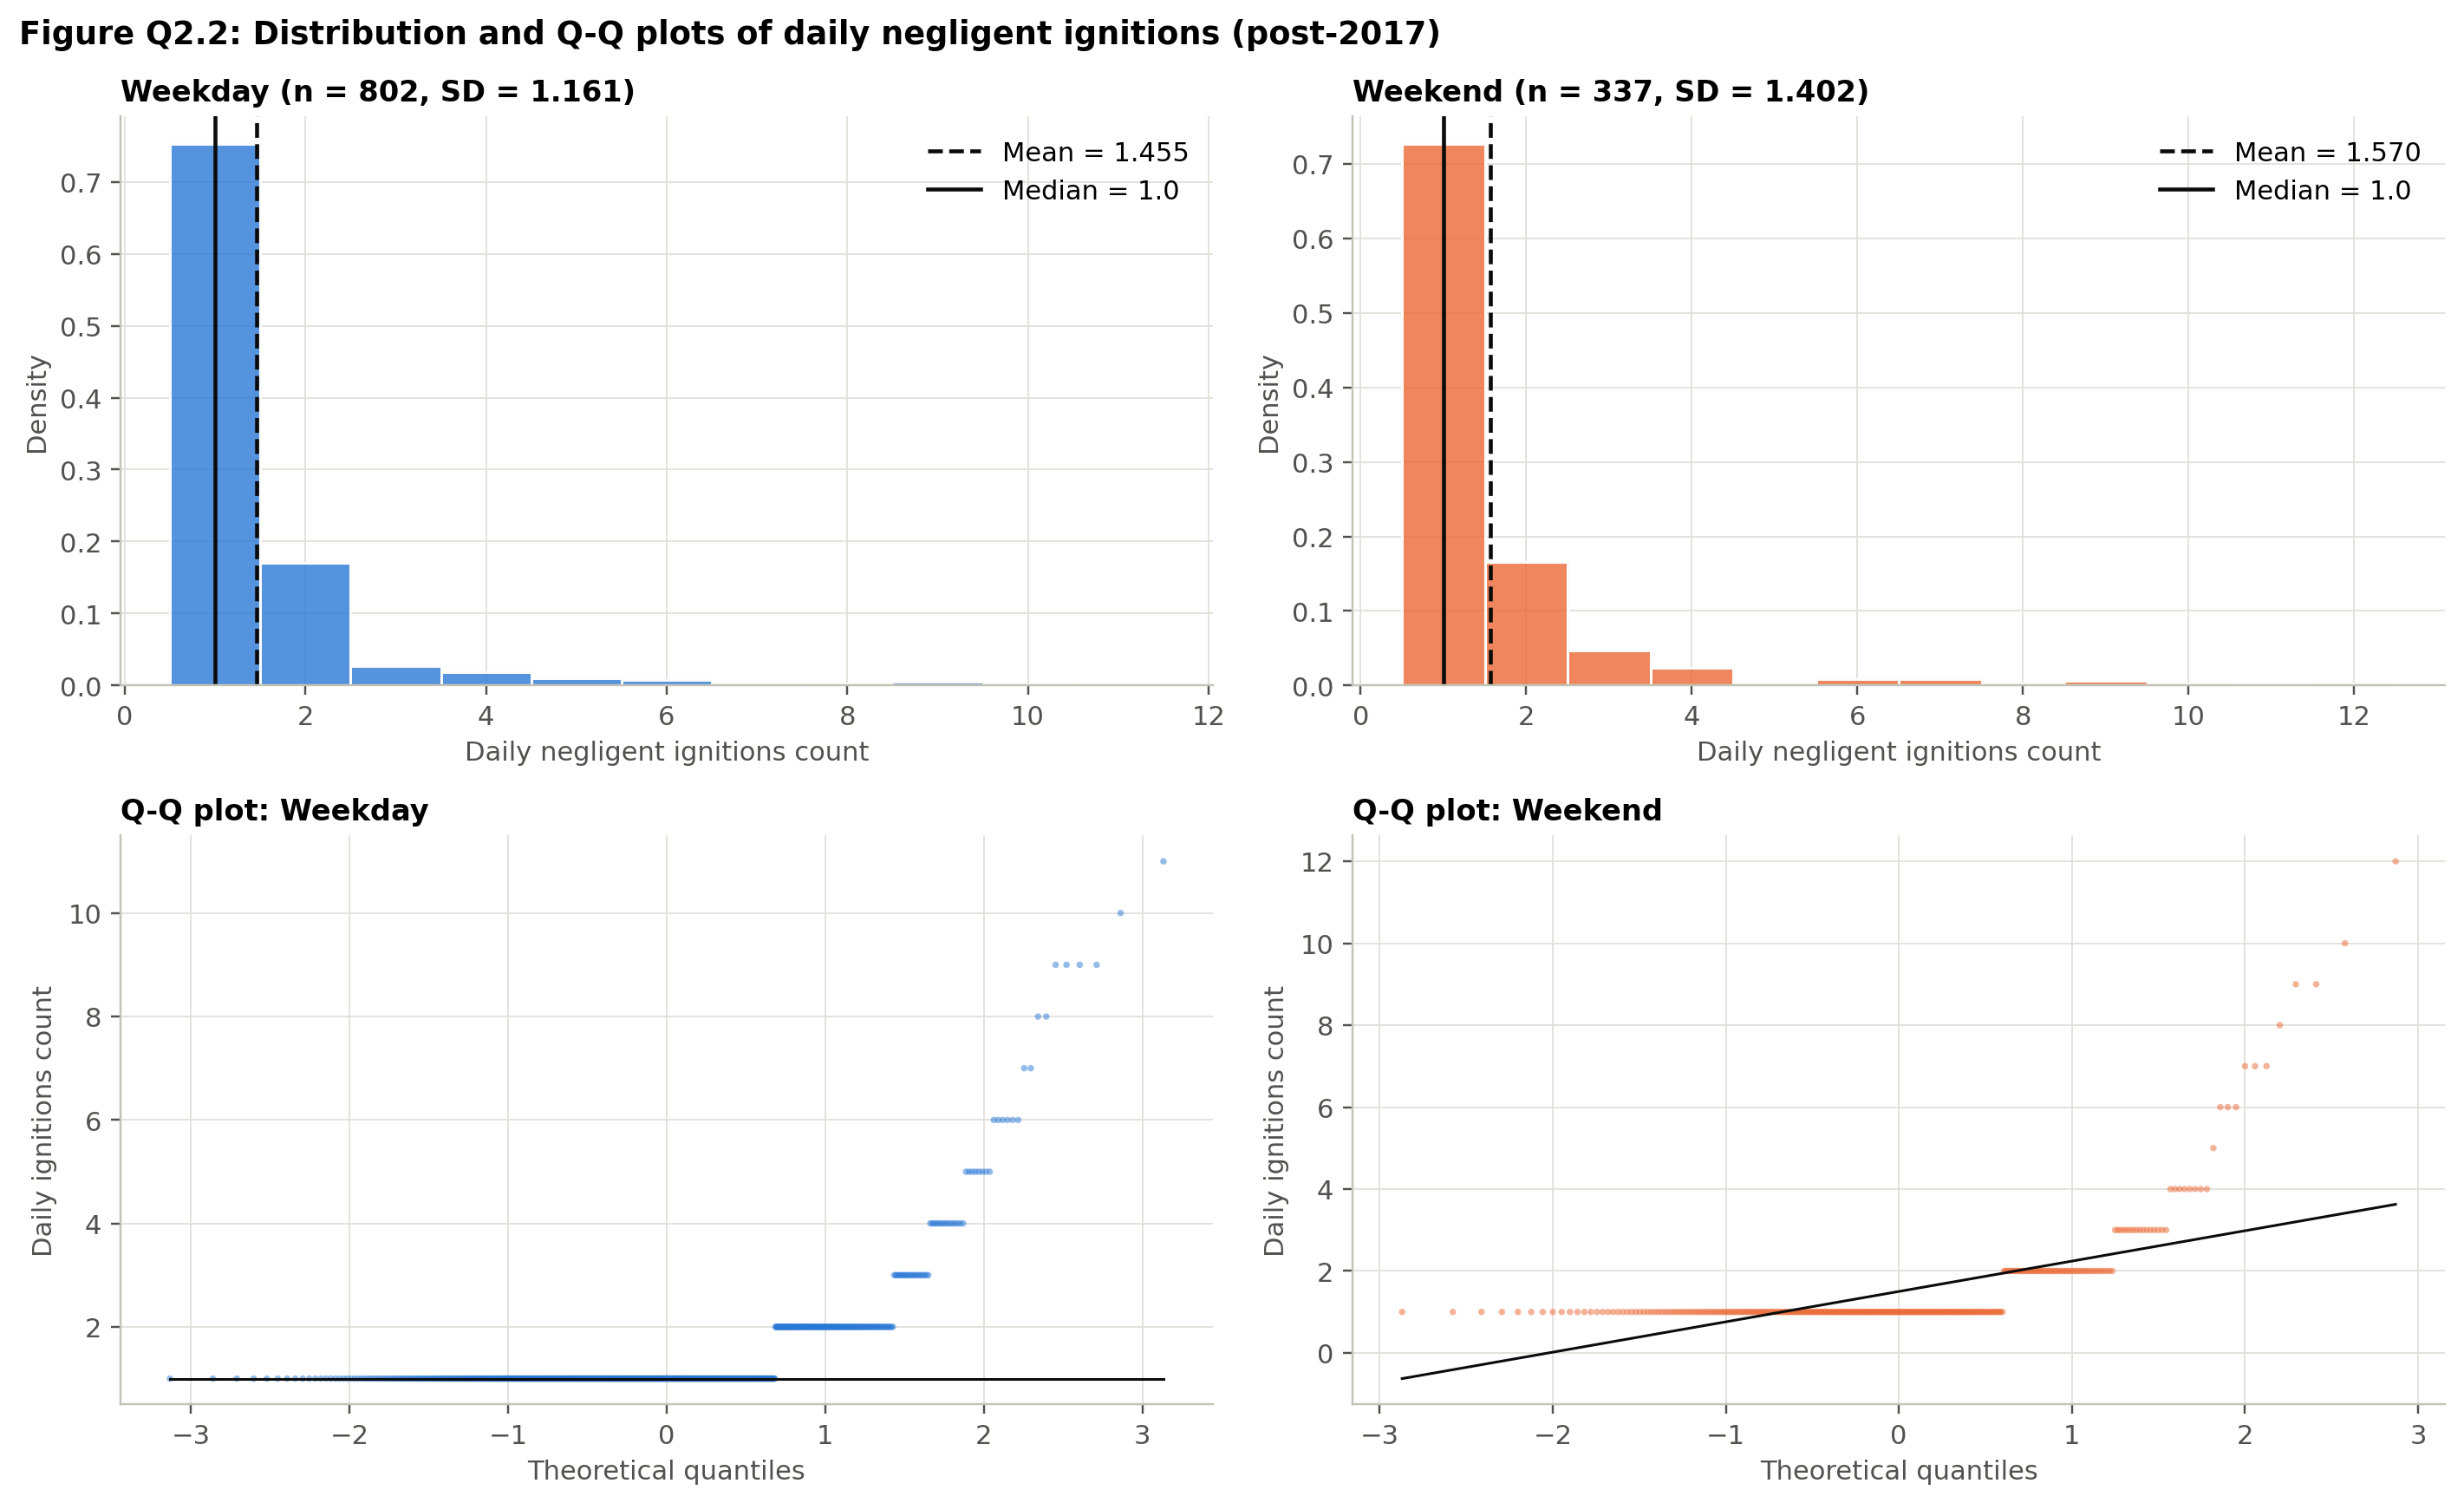

Post-2017 spread: Weekend SD = 1.402 (var = 1.966) | Weekday SD = 1.161 (var = 1.347) | SD ratio = 1.21 (variance ratio = 1.46)


In [37]:
# Post-2017 subset
post_data = q2[q2["Period"] == "Post-2017"].copy()

weekday_post = post_data[post_data["Day_Type"] == "Weekday"]["Daily_Ignitions_Count"]
weekend_post = post_data[post_data["Day_Type"] == "Weekend"]["Daily_Ignitions_Count"]

# Visual check of normality and spread: histograms + Q-Q plots (post-2017)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
groups_post = [("Weekday", weekday_post), ("Weekend", weekend_post)]

for i, (label, serie) in enumerate(groups_post):
    color = PAL_DAY[label]
    # histogram (top row)
    sns.histplot(serie, discrete=True, stat="density", color=color, alpha=0.8, edgecolor=SURFACE, ax=axes[0, i])
    axes[0, i].axvline(serie.mean(), color=INK, linestyle="--", linewidth=1.5, label=f"Mean = {serie.mean():.3f}")
    axes[0, i].axvline(serie.median(), color=INK, linestyle="-", linewidth=1.5, label=f"Median = {serie.median():.1f}")
    axes[0, i].set_title(f"{label} (n = {len(serie)}, SD = {serie.std(ddof=1):.3f})")
    axes[0, i].set_xlabel("Daily negligent ignitions count")
    axes[0, i].set_ylabel("Density")
    axes[0, i].legend()

    # normal Q-Q plot (bottom row)
    qq_panel(axes[1, i], serie, color, f"Q-Q plot: {label}", ylabel="Daily ignitions count")

fig_title(fig, "Figure Q2.2: Distribution and Q-Q plots of daily negligent ignitions (post-2017)")
plt.tight_layout()
plt.show()

var_ratio = weekend_post.var(ddof=1) / weekday_post.var(ddof=1)
print(f"Post-2017 spread: Weekend SD = {weekend_post.std(ddof=1):.3f} (var = {weekend_post.var(ddof=1):.3f}) | "
      f"Weekday SD = {weekday_post.std(ddof=1):.3f} (var = {weekday_post.var(ddof=1):.3f}) | "
      f"SD ratio = {np.sqrt(var_ratio):.2f} (variance ratio = {var_ratio:.2f})")

**Normality.** Over all calendar days, Y is zero on about 90% of municipality-days. On active days, it is an integer of at least 1, concentrated at 1 and strongly right-skewed (skewness 4.26 on weekdays and 4.02 on weekends), as the histograms and normal Q-Q plots in Figure Q2.2 show. With 3,272 weekend days and 8,188 weekdays in the primary test, and 337 and 802 in the complementary test, the group means are approximately normal (Section 4), so this departure is not a concern.

**Equal variances.** On active days, the standard deviations are 1.402 on weekends and 1.161 on weekdays, so the largest is 1.21 times the smallest (variance ratio 1.46), well below the limit of 2 set at the start of Section 4. Even so, Welch's two-sample t-test (`equal_var=False`) is used in both tests, because it adjusts the degrees of freedom (Welch-Satterthwaite) and does not assume equal variances.

#### Primary test: all calendar days (Welch's t-test)

The full post-2017 calendar is rebuilt with every municipality-day from 1 January 2018 to the last alert in the data (N = 11,460), with zeros for the days without negligent ignitions. The weekend and weekday means are compared with Welch's t-test, and the same difference is re-estimated with standard errors clustered by date. A supplementary two-proportion Z-test checks whether the probability of an active day, P(Y ≥ 1), differs between weekends and weekdays.

In [38]:
# Full post-2017 calendar: every municipality x day from 1 Jan 2018 to the last alert in the data
last_day = df_final["DataHoraAlerta"].max().normalize()
calendar = pd.MultiIndex.from_product([MUNICIPALITIES, pd.date_range("2018-01-01", last_day)], names=["Concelho", "Date"])
cal = (post_data.set_index(["Concelho", "Date"])["Daily_Ignitions_Count"]
       .reindex(calendar, fill_value=0).reset_index())
cal["Day_Type"] = pd.Categorical(np.where(cal["Date"].dt.day_of_week >= 5, "Weekend", "Weekday"), categories=DAY_ORDER)
assert cal["Daily_Ignitions_Count"].sum() == post_data["Daily_Ignitions_Count"].sum()
print(f"Calendar: {cal['Date'].min():%Y-%m-%d} to {cal['Date'].max():%Y-%m-%d}, {len(cal):,} municipality-days")

# Decomposition E[Y] = P(Y >= 1) x E[Y | Y >= 1]
decomp = cal.groupby("Day_Type", observed=False)["Daily_Ignitions_Count"].agg(
    municipality_days="size",
    active_days=lambda y: (y > 0).sum(),
    p_active=lambda y: (y > 0).mean(),
    mean_active_days=lambda y: y[y > 0].mean(),
    mean_all_days="mean",
)
display(decomp.round(4))

y_we = cal.loc[cal["Day_Type"] == "Weekend", "Daily_Ignitions_Count"]
y_wd = cal.loc[cal["Day_Type"] == "Weekday", "Daily_Ignitions_Count"]

# (a) unconditional mean: Welch's t-test and the same difference with standard errors clustered by date
t_all = stats.ttest_ind(y_we, y_wd, equal_var=False)
ci_all = t_all.confidence_interval(0.95)
diff_all = y_we.mean() - y_wd.mean()
print(f"Mean over all days: Weekend {y_we.mean():.4f} vs Weekday {y_wd.mean():.4f} "
      f"(diff = {diff_all:+.4f}, ratio = {y_we.mean() / y_wd.mean():.3f} or {100 * (y_we.mean() / y_wd.mean() - 1):+.1f}%)")
print(f"  Welch t({t_all.df:.1f}) = {t_all.statistic:.3f}, p = {t_all.pvalue:.4f}, "
      f"95% CI for the difference [{ci_all.low:.4f}, {ci_all.high:.4f}] "
      f"([{100 * ci_all.low / y_wd.mean():+.1f}%, {100 * ci_all.high / y_wd.mean():+.1f}%] of weekday mean)")
ols_all = smf.ols("Daily_Ignitions_Count ~ weekend", data=cal.assign(weekend=(cal["Day_Type"] == "Weekend").astype(int))).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(cal["Date"])[0]})
print(f"  SE clustered by date: p = {ols_all.pvalues['weekend']:.4f}")

# (b) supplementary check on probability of an active day: two-proportion Z-test
z_act, p_act = smp.proportions_ztest([(y_we > 0).sum(), (y_wd > 0).sum()], [len(y_we), len(y_wd)])
print(f"Supplementary check, P(Y >= 1): Weekend {(y_we > 0).mean():.3f} vs Weekday {(y_wd > 0).mean():.3f}; "
      f"Z = {z_act:.3f}, p = {p_act:.4f}")

Calendar: 2018-01-01 to 2025-11-04, 11,460 municipality-days


,municipality_days,active_days,p_active,mean_active_days,mean_all_days
Day_Type,,,,,
Weekday,8188,802,0.0979,1.4551,0.1425
Weekend,3272,337,0.1030,1.5697,0.1617


Mean over all days: Weekend 0.1617 vs Weekday 0.1425 (diff = +0.0191, ratio = 1.134 or +13.4%)
  Welch t(5312.2) = 1.468, p = 0.1423, 95% CI for the difference [-0.0064, 0.0447] ([-4.5%, +31.4%] of weekday mean)
  SE clustered by date: p = 0.1925
Supplementary check, P(Y >= 1): Weekend 0.103 vs Weekday 0.098; Z = 0.816, p = 0.4147


**Interpretation.** Over all calendar days, the mean is 0.1617 negligent ignitions per municipality-day on weekends and 0.1425 on weekdays, a difference of 0.019 (13.4% of the weekday mean). Welch's t-test gives t(5312.2) = 1.468 and p = 0.142, and the 95% confidence interval for the difference (−0.006 to 0.045) includes zero. With standard errors clustered by date, p = 0.193. The probability of an active day is also similar on weekends and weekdays (10.3% and 9.8%, Z = 0.816, p = 0.415). H₀ is not rejected.

The complementary test below asks whether, on days with at least one negligent ignition, weekends have more ignitions than weekdays.

#### Complementary test: active days (Welch's t-test)

In [39]:
# Welch's t-test (equal_var=False)
t_stat, p_val = stats.ttest_ind(weekend_post, weekday_post, equal_var=False)

# Welch-Satterthwaite degrees of freedom
s1, s2 = np.var(weekend_post, ddof=1), np.var(weekday_post, ddof=1)
n1, n2 = len(weekend_post), len(weekday_post)
df_welch = ((s1 / n1 + s2 / n2) ** 2) / (
    ((s1 / n1) ** 2) / (n1 - 1) + ((s2 / n2) ** 2) / (n2 - 1)
)

# Critical value (two-sided, alpha = 0.05) and 95% confidence interval
alpha = 0.05
t_crit = stats.t.ppf(1 - alpha / 2, df=df_welch)
diff_mean = weekend_post.mean() - weekday_post.mean()
se_diff = np.sqrt(s1 / n1 + s2 / n2)
ci_low, ci_high = stats.t.interval(
    1 - alpha, df=df_welch, loc=diff_mean, scale=se_diff
)

print("Welch's two-sample t-test (post-2017):")
print(f"Mean Weekend: {weekend_post.mean():.3f} (SD = {weekend_post.std(ddof=1):.3f}, n = {n1})")
print(f"Mean Weekday: {weekday_post.mean():.3f} (SD = {weekday_post.std(ddof=1):.3f}, n = {n2})")
print(f"Difference in means (Weekend - Weekday): {diff_mean:.3f} (SE = {se_diff:.4f})")
print(f"Welch t-statistic (t_obs): {t_stat:.4f}")
print(f"Degrees of freedom (df): {df_welch:.2f}")
print(f"Critical value (t_crit, alpha = 0.05 two-sided): ±{t_crit:.4f}")
print(f"p-value: {p_val:.4f}")
print(f"95% confidence interval for the difference: [{ci_low:.3f}, {ci_high:.3f}]")
decision = "Reject H0" if p_val < alpha else "Fail to reject H0"
print(f"Decision: {decision} (|t_obs| = {abs(t_stat):.4f}, t_crit = {t_crit:.4f}, p = {p_val:.4f}, alpha = {alpha})")

# Effect size: ratio of means and Cohen's d (pooled SD)
mean_ratio = weekend_post.mean() / weekday_post.mean()
sd_pooled = np.sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / (n1 + n2 - 2))
cohen_d = diff_mean / sd_pooled
print(f"\nEffect size: ratio of means (Weekend / Weekday) = {mean_ratio:.3f} ({100 * (mean_ratio - 1):+.1f}%), Cohen's d = {cohen_d:.3f}")
print(f"95% CI for the difference relative to the weekday mean: "
      f"[{100 * ci_low / weekday_post.mean():+.1f}%, {100 * ci_high / weekday_post.mean():+.1f}%]")

Welch's two-sample t-test (post-2017):
Mean Weekend: 1.570 (SD = 1.402, n = 337)
Mean Weekday: 1.455 (SD = 1.161, n = 802)
Difference in means (Weekend - Weekday): 0.115 (SE = 0.0867)
Welch t-statistic (t_obs): 1.3223
Degrees of freedom (df): 538.57
Critical value (t_crit, alpha = 0.05 two-sided): ±1.9644
p-value: 0.1866
95% confidence interval for the difference: [-0.056, 0.285]
Decision: Fail to reject H0 (|t_obs| = 1.3223, t_crit = 1.9644, p = 0.1866, alpha = 0.05)

Effect size: ratio of means (Weekend / Weekday) = 1.079 (+7.9%), Cohen's d = 0.093
95% CI for the difference relative to the weekday mean: [-3.8%, +19.6%]


**Interpretation.** On active days, the difference is 0.115 ignitions per day (1.570 on weekends against 1.455 on weekdays), with t(538.6) = 1.322 and p = 0.187. The 95% confidence interval (−0.056 to 0.285) includes zero, and the effect size is very small (Cohen's d = 0.09; Cohen, 1988). H₀ is not rejected, in agreement with the primary test.

#### Robustness checks

##### Controlling for municipality

As the table below shows, the four municipalities differ in daily negligent ignition counts on active days. The weekend mean ranges from about 1.05 ignitions per day in Tomar to 1.99 in Montalegre, and the weekday mean from 1.08 in Ourém to 1.82 in Montalegre. To check that pooling the four municipalities does not hide a weekend effect in a single one, Welch's t-test on active days is repeated within each municipality and the 95% confidence intervals for the difference in means are plotted.

Welch's t-test by municipality (Bonferroni alpha = 0.05/4 = 0.0125; all p > 0.05):


,Municipality,n_Weekend,n_Weekday,Mean_Weekend,Mean_Weekday,Diff (Wknd - Wkdy),CI_95,p_value
0,Chaves,84,181,1.369,1.238,0.131,"[-0.028, 0.291]",0.1063
1,Montalegre,153,363,1.993,1.824,0.170,"[-0.178, 0.517]",0.3365
2,Ourém,44,131,1.136,1.084,0.052,"[-0.065, 0.170]",0.3754
3,Tomar,56,127,1.054,1.094,-0.041,"[-0.137, 0.056]",0.4029
4,All (pooled),337,802,1.570,1.455,0.115,"[-0.056, 0.285]",0.1866


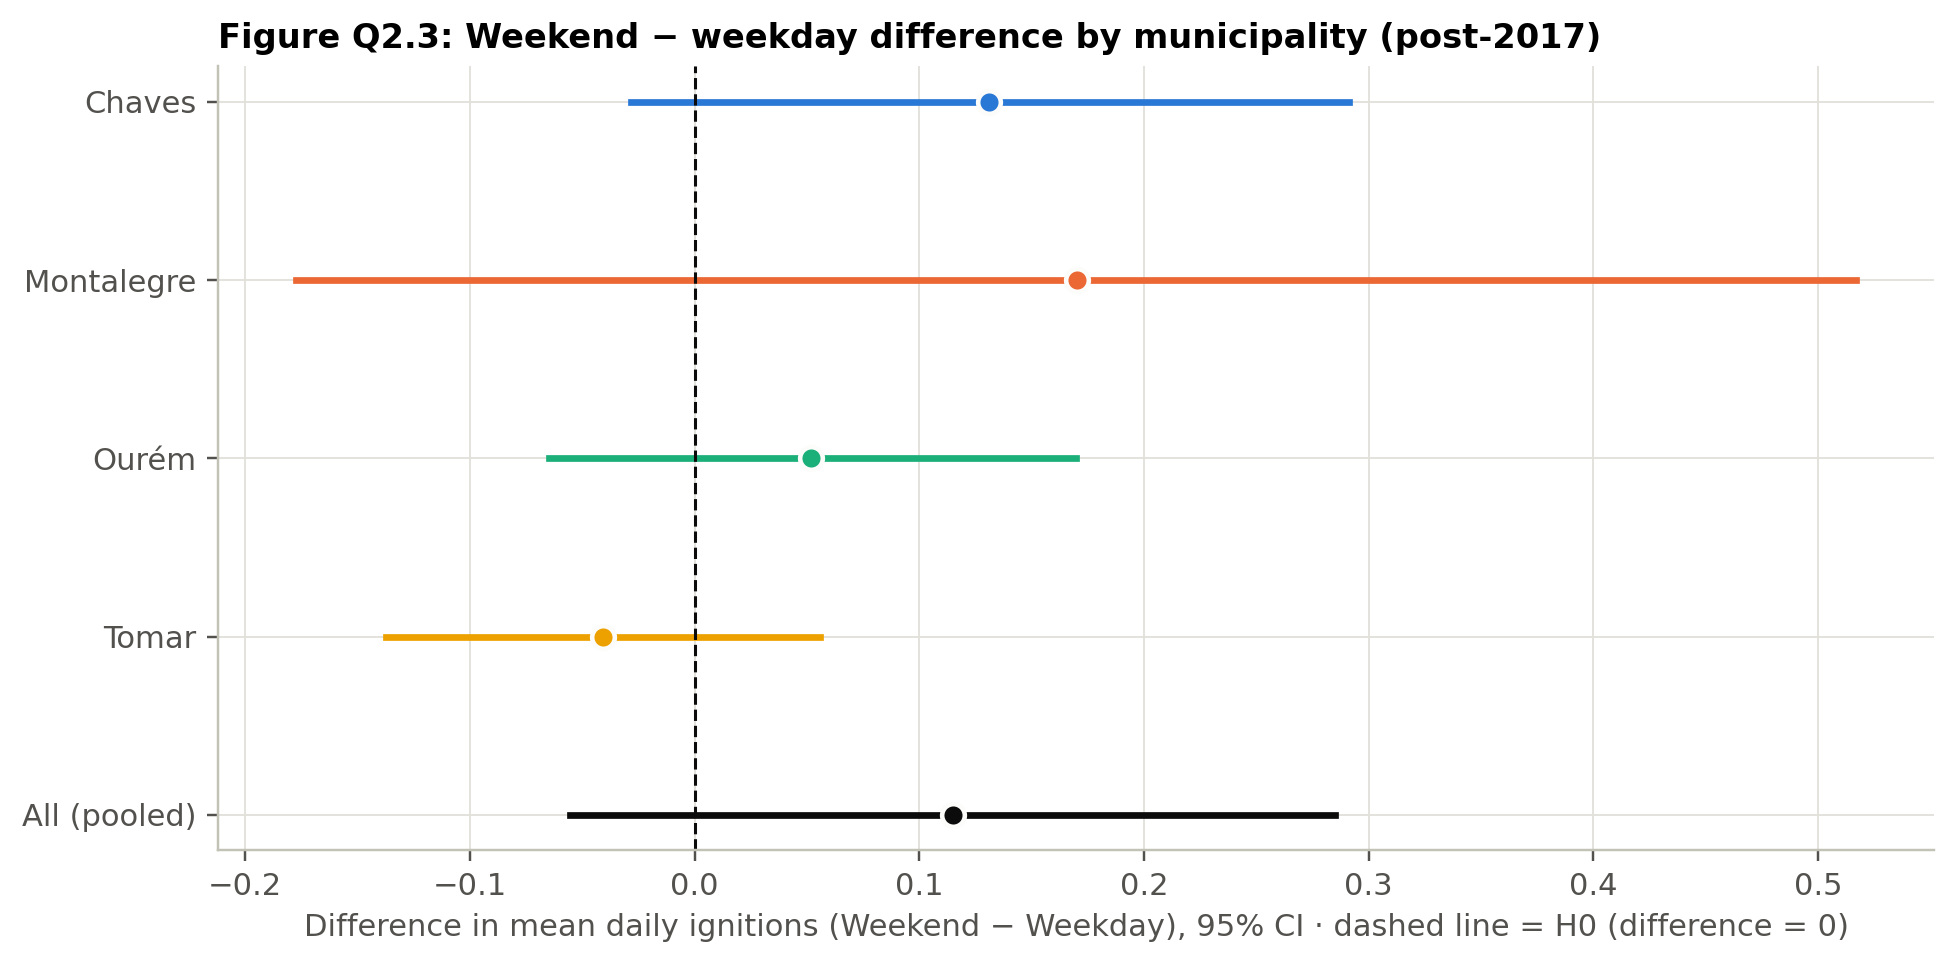

In [40]:
# Welch's t-test by municipality in the post-2017 period
alpha_bonf_mun = 0.05 / 4  # Bonferroni correction for 4 municipalities (0.0125)
mun_rows = []
for mun in MUNICIPALITIES:
    sub_m = post_data[post_data["Concelho"] == mun]
    wknd_m = sub_m[sub_m["Day_Type"] == "Weekend"]["Daily_Ignitions_Count"]
    wkdy_m = sub_m[sub_m["Day_Type"] == "Weekday"]["Daily_Ignitions_Count"]
    if len(wknd_m) >= 2 and len(wkdy_m) >= 2:
        t_m, p_m = stats.ttest_ind(wknd_m, wkdy_m, equal_var=False)
        v1_m, v2_m = wknd_m.var(ddof=1), wkdy_m.var(ddof=1)
        n1_m, n2_m = len(wknd_m), len(wkdy_m)
        se_m = np.sqrt(v1_m / n1_m + v2_m / n2_m)
        df_m = ((v1_m / n1_m + v2_m / n2_m) ** 2) / (((v1_m / n1_m) ** 2) / (n1_m - 1) + ((v2_m / n2_m) ** 2) / (n2_m - 1))
        diff_m = wknd_m.mean() - wkdy_m.mean()
        ci_l, ci_h = stats.t.interval(0.95, df=df_m, loc=diff_m, scale=se_m)
        mun_rows.append({
            "Municipality": mun,
            "n_Weekend": n1_m,
            "n_Weekday": n2_m,
            "Mean_Weekend": round(wknd_m.mean(), 3),
            "Mean_Weekday": round(wkdy_m.mean(), 3),
            "Diff (Wknd - Wkdy)": round(diff_m, 3),
            "CI_95": f"[{ci_l:.3f}, {ci_h:.3f}]",
            "p_value": round(p_m, 4),
            "CI_95_low": ci_l,
            "CI_95_high": ci_h,
        })

# Pooled row (all municipalities, post-2017) for visual comparison
mun_rows.append({
    "Municipality": "All (pooled)",
    "n_Weekend": n1,
    "n_Weekday": n2,
    "Mean_Weekend": round(weekend_post.mean(), 3),
    "Mean_Weekday": round(weekday_post.mean(), 3),
    "Diff (Wknd - Wkdy)": round(diff_mean, 3),
    "CI_95": f"[{ci_low:.3f}, {ci_high:.3f}]",
    "p_value": round(p_val, 4),
    "CI_95_low": ci_low,
    "CI_95_high": ci_high,
})

mun_df = pd.DataFrame(mun_rows)
cols_show = ["Municipality", "n_Weekend", "n_Weekday", "Mean_Weekend", "Mean_Weekday", "Diff (Wknd - Wkdy)", "CI_95", "p_value"]
print(f"Welch's t-test by municipality (Bonferroni alpha = 0.05/4 = {alpha_bonf_mun:.4f}; all p > 0.05):")
display(mun_df[cols_show])

# Forest plot of the 95% confidence intervals for (mu_Weekend - mu_Weekday)
fig, ax = plt.subplots(figsize=(9, 4.5))
y_pos = np.arange(len(mun_df))

for idx, row in mun_df.iterrows():
    col = INK if row["Municipality"] == "All (pooled)" else PAL_MUN[row["Municipality"]]
    ax.plot([row["CI_95_low"], row["CI_95_high"]], [idx, idx], color=col, linewidth=2.2)
    ax.scatter(row["Diff (Wknd - Wkdy)"], idx, s=55, color=col, zorder=3, edgecolor=SURFACE, linewidth=1.5)

ax.axvline(0, color=INK, linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(mun_df["Municipality"])
ax.invert_yaxis()
ax.set_xlabel("Difference in mean daily ignitions (Weekend − Weekday), 95% CI · dashed line = H0 (difference = 0)")
ax.set_title("Figure Q2.3: Weekend − weekday difference by municipality (post-2017)")
plt.tight_layout()
plt.show()

**Interpretation.** All four 95% confidence intervals include zero (Figure Q2.3), and every p-value is above 0.05, and therefore also above the Bonferroni threshold of 0.05 / 4 = 0.0125. Pooling the four municipalities does not hide a weekend effect in any of them.

##### Dependence between municipalities on the same day

The municipalities are close to each other in pairs (Chaves and Montalegre, Ourém and Tomar), and on many dates more than one municipality had negligent ignitions. Observations sharing a date are exposed to the same weather and always have the same day type, so the Welch standard error may be too small. The difference in means is therefore re-estimated as a regression on a weekend indicator (its coefficient equals the difference in means) with standard errors clustered by date.

In [41]:
# Same-day dependence: share of active dates with more than one active municipality
mun_per_date = post_data.groupby("Date").size()
print(f"Post-2017 active dates: {len(mun_per_date):,}; with more than one active municipality: {(mun_per_date > 1).mean():.1%}")

# Difference in means (Weekend - Weekday) with standard errors clustered by date
reg_data = post_data.assign(weekend=(post_data["Day_Type"] == "Weekend").astype(int))
ols_cl = smf.ols("Daily_Ignitions_Count ~ weekend", data=reg_data).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(reg_data["Date"])[0]})
ci_cl = ols_cl.conf_int().loc["weekend"]
print(f"Difference = {ols_cl.params['weekend']:.3f}, SE clustered by date = {ols_cl.bse['weekend']:.4f} "
      f"(Welch SE = {se_diff:.4f}), p = {ols_cl.pvalues['weekend']:.4f}, 95% CI [{ci_cl.iloc[0]:.3f}, {ci_cl.iloc[1]:.3f}]")

Post-2017 active dates: 869; with more than one active municipality: 27.0%
Difference = 0.115, SE clustered by date = 0.0885 (Welch SE = 0.0867), p = 0.1955, 95% CI [-0.059, 0.288]


**Interpretation.** On 27.0% of the active dates more than one municipality had negligent ignitions. With standard errors clustered by date, the standard error of the difference rises only from 0.0867 to 0.0885, and p = 0.196, so the conclusion does not change.

---

### 4.3 Q3: One-way ANOVA

This section tests whether the mean log burnt area per fire, and therefore the geometric mean burnt area, differs between the four municipalities in 2018–2025.

#### Terminology

- **$Y$**: the log10 of the burnt area of one fire (`Log_Total_Burnt_Area`), for fires with an area above 0 ha in 2018–2025.
- **$\mu_{\text{Chaves}}$**, **$\mu_{\text{Montalegre}}$**, **$\mu_{\text{Ourém}}$** and **$\mu_{\text{Tomar}}$**: the population mean of $Y$ in each municipality; $10^{\mu}$ is the geometric mean burnt area.
- **$\alpha$**: the significance level, set at 0.05.

#### Hypotheses

- **H₀:** $\mu_{\text{Chaves}} = \mu_{\text{Montalegre}} = \mu_{\text{Ourém}} = \mu_{\text{Tomar}}$.
- **H₁:** at least one of these means differs.

The records cover all fires registered in SGIF for these municipalities and years. They are treated as realisations of the fire-generating process in each municipality, so the tests refer to that process rather than to sampling from a finite list of records.

#### Checking the assumptions

The one-way ANOVA model is $y_{ij} = \mu_i + \varepsilon_{ij}$, where the errors $\varepsilon_{ij}$ must be independent, normal and of equal variance in all groups. Normality and equal variances are checked on the residuals $e_{ij} = y_{ij} - \bar y_i$, on three response scales.

1. **Independence.** See the shared assumptions at the start of Section 4. The robustness checks repeat the test allowing fires on the same day to be correlated.
2. **Normality.** It is checked below with the skewness, the excess kurtosis and the Shapiro-Wilk statistic of each scale, and with a normal Q-Q plot of the residuals.
3. **Equal variances.** They are checked with the ratio of the largest to the smallest group standard deviation, following the criterion set at the start of Section 4, and with the Levene and Brown-Forsythe tests.

In [42]:
def diagnostics(samples):
    resid = np.concatenate([x - x.mean() for x in samples])
    var = np.array([x.var(ddof=1) for x in samples])
    return pd.Series({"n": len(resid),
                      "residual skewness": stats.skew(resid),
                      "residual excess kurtosis": stats.kurtosis(resid),
                      "max |skewness| within groups": max(abs(stats.skew(x)) for x in samples),
                      "max excess kurtosis within groups": max(stats.kurtosis(x) for x in samples),
                      "min Shapiro-Wilk W (groups)": min(stats.shapiro(x).statistic for x in samples),
                      "largest / smallest SD": np.sqrt(var.max() / var.min()),
                      "largest / smallest variance": var.max() / var.min(),
                      "Levene p (mean)": stats.levene(*samples, center="mean").pvalue,
                      "Brown-Forsythe p (median)": stats.levene(*samples, center="median").pvalue})

raw_groups = [q3.loc[q3["Concelho"] == m, Y].to_numpy() for m in MUNICIPALITIES]
log_groups = [q3_log.loc[q3_log["Concelho"] == m, LOG].to_numpy() for m in MUNICIPALITIES]
diag = pd.DataFrame({"original (ha)": diagnostics(raw_groups),
                     "log10(1 + area)": diagnostics([np.log10(1 + x) for x in raw_groups]),
                     "log10(area)": diagnostics(log_groups)})
display(diag.map(lambda v: f"{v:.4g}"))
print("SD of log10(area) by municipality:", {m: round(float(x.std(ddof=1)), 3) for m, x in zip(MUNICIPALITIES, log_groups)})

,original (ha),log10(1 + area),log10(area)
n,2739,2739,2738
residual skewness,20.98,2.774,0.1287
residual excess kurtosis,493,9.991,0.2666
max |skewness| within groups,28.66,6.743,0.4091
max excess kurtosis within groups,894.1,54.06,1.438
min Shapiro-Wilk W (groups),0.0601,0.3343,0.962
largest / smallest SD,5.407,2.108,1.147
largest / smallest variance,29.24,4.443,1.316
Levene p (mean),0.02315,3.543e-73,0.0001075
Brown-Forsythe p (median),0.4372,6.77e-44,0.0002396


SD of log10(area) by municipality: {'Chaves': 1.178, 'Montalegre': 1.221, 'Ourém': 1.178, 'Tomar': 1.065}


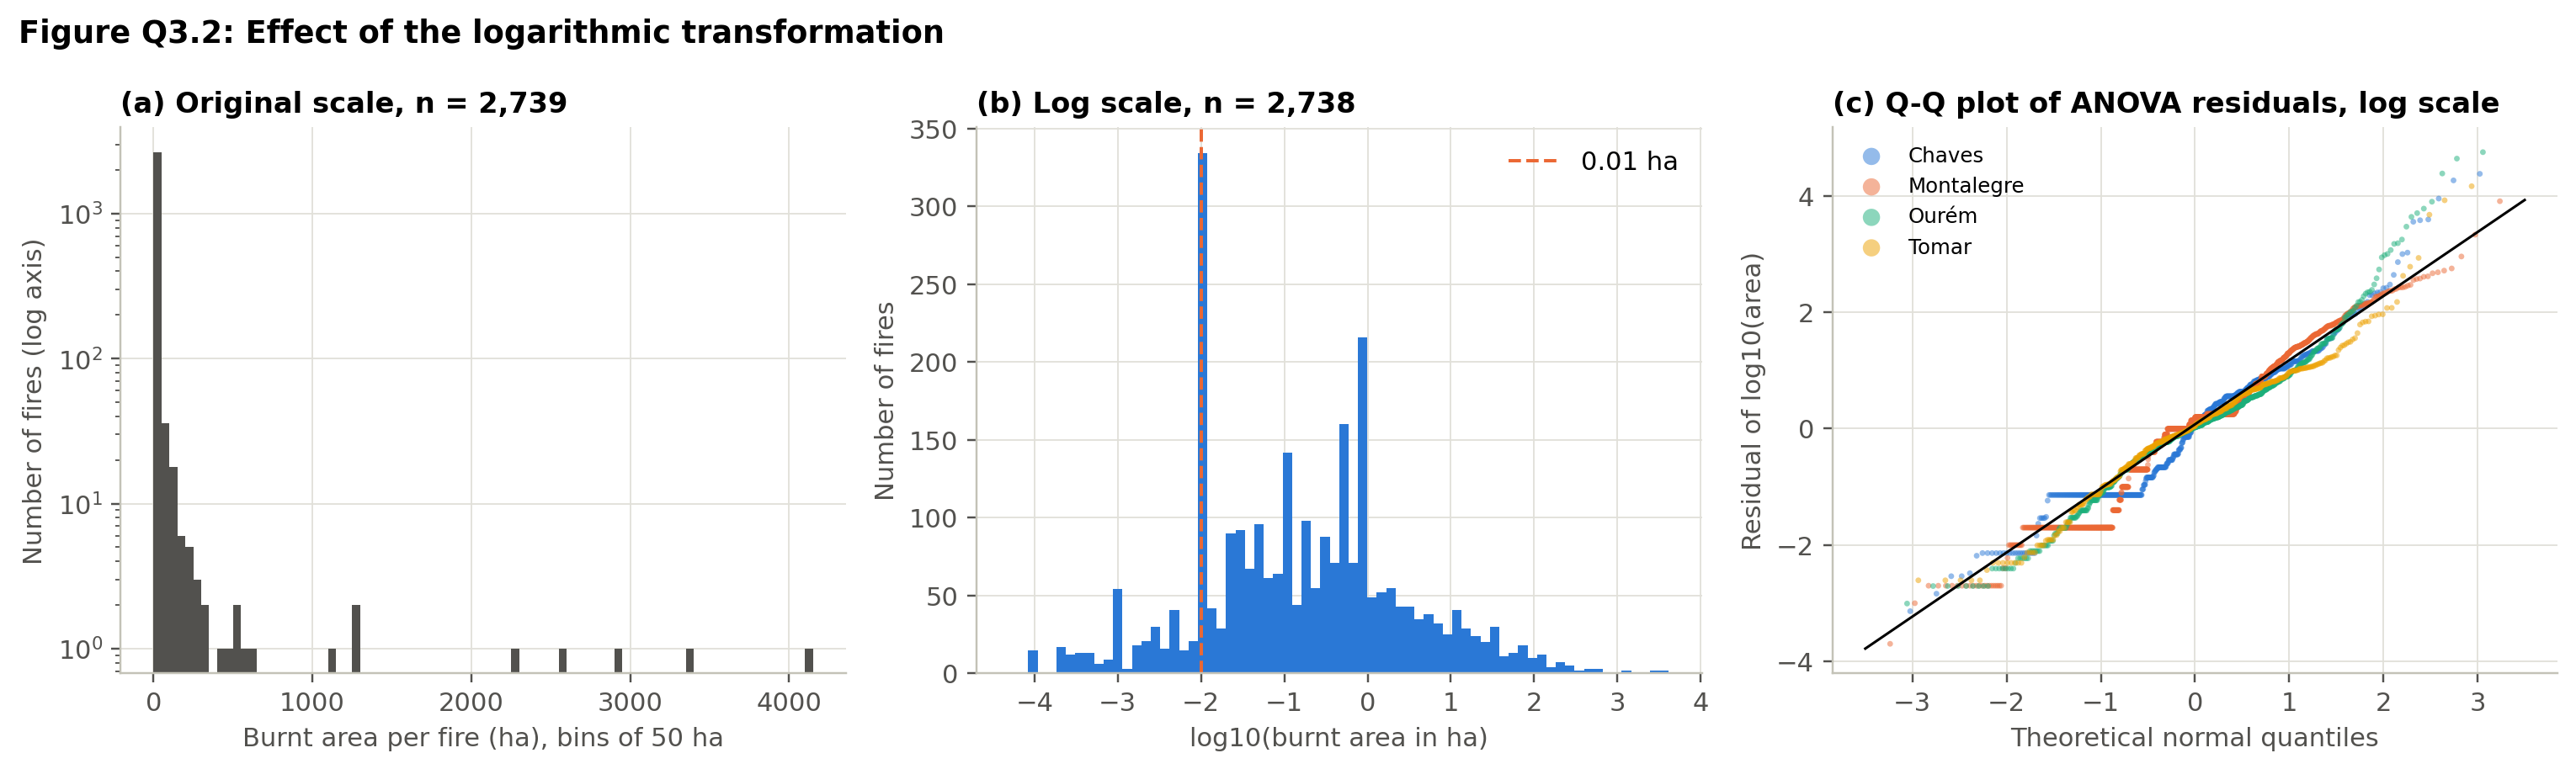

In [43]:
# Figure Q3.2 - effect of the log transformation and normal Q-Q plot of the ANOVA residuals
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

axes[0].hist(q3[Y], bins=np.arange(0, q3[Y].max() + 50, 50), color=MUTED)
axes[0].set_yscale("log")
axes[0].set_xlabel("Burnt area per fire (ha), bins of 50 ha")
axes[0].set_ylabel("Number of fires (log axis)")
axes[0].set_title("(a) Original scale, n = 2,739")

axes[1].hist(q3_log[LOG], bins=70, color=BLUE)
axes[1].axvline(np.log10(0.01), color=ORANGE, linestyle="--", linewidth=1.3, label="0.01 ha")
axes[1].set_xlabel("log10(burnt area in ha)")
axes[1].set_ylabel("Number of fires")
axes[1].set_title("(b) Log scale, n = 2,738")
axes[1].legend(frameon=False)

resid = np.concatenate([x - x.mean() for x in log_groups])
for m, x in zip(MUNICIPALITIES, log_groups):
    (osm, osr), _ = stats.probplot(x - x.mean(), dist="norm")
    axes[2].scatter(osm, osr, s=5, alpha=.5, color=PAL_MUN[m], edgecolor="none", label=m)
lo, hi = np.percentile(resid, [25, 75])
z = stats.norm.ppf(.75) - stats.norm.ppf(.25)
zz = np.linspace(-3.5, 3.5, 2)
axes[2].plot(zz, np.median(resid) + (hi - lo) / z * zz, color="black", linewidth=1)
axes[2].set_xlabel("Theoretical normal quantiles")
axes[2].set_ylabel("Residual of log10(area)")
axes[2].set_title("(c) Q-Q plot of ANOVA residuals, log scale")
axes[2].legend(frameon=False, markerscale=3, fontsize=8)

fig_title(fig, "Figure Q3.2: Effect of the logarithmic transformation")
plt.tight_layout()
plt.show()

| Assumption | Original scale (ha) | log10(area) |
|---|---|---|
| Independence | Not testable; possible clustering by place and time | Same |
| Normality of residuals | Severely violated: skewness 21.0, excess kurtosis 493 | Approximately symmetric: skewness 0.13, excess kurtosis 0.27; Shapiro-Wilk still rejects (W ≥ 0.96) |
| Equal variances | Largest SD 5.4 times the smallest (variance ratio 29.2, Levene p = 0.023). Brown-Forsythe p = 0.44: absolute deviations from the median do not differ significantly, because the large ratio is driven by a few extreme fires | Largest SD 1.15 times the smallest (variance ratio 1.32), but Levene and Brown-Forsythe reject (p ≤ 0.0003) |

**Choice of scale.** The original scale is far from normal, and `log10(1 + area)` is not used either, because log10(1 + x) is almost proportional to x for areas below 1 ha (78% of the fires) and leaves strong skewness (2.8). The analysis therefore uses log10(area). This scale was chosen on distributional grounds, not on the basis of test results, and the research question was then stated on it. Because the choice was informed by the data, the robustness checks verify that the conclusion does not depend on it.

**Normality.** On the log10(area) scale, the residuals are approximately symmetric (skewness 0.13, excess kurtosis 0.27), and within-group skewness is at most 0.41 in absolute value. The Q-Q plot follows the reference line closely except for stair-steps in the lower tail, produced by repeated rounded areas such as 0.01 ha, and a somewhat heavier upper tail in Ourém (excess kurtosis 1.4). Shapiro-Wilk still rejects normality, but with at least 418 fires per group the group means are approximately normal (Section 4), and the F test is robust to moderate departures of this kind, so this departure is not a concern.

**Equal variances.** Equal variances cannot be claimed exactly, because the Levene and Brown-Forsythe tests reject homogeneity (p ≤ 0.0003). The largest standard deviation is only 1.15 times the smallest, well below the limit of 2 set at the start of Section 4, so the classical one-way ANOVA is used, followed by Tukey HSD. The largest group (Montalegre) also has the largest variance, which makes the classical F test conservative rather than liberal. Welch's ANOVA, which does not assume equal variances, is reported as a robustness check in Appendix A.2.

#### One-way ANOVA on log10(burnt area)

The ANOVA compares the variation between municipality means (SSB) with the variation of fires within municipalities (SSW): F = MSB / MSW, with k − 1 = 3 and N − k = 2,734 degrees of freedom. Under H₀, F is close to 1. The table is computed directly from the formulas and checked against `scipy.stats.f_oneway`. The effect size η² = SSB / SST is the share of the variance of log10(area) associated with municipality; ω², which is less biased, is reported alongside it.

In [44]:
N, k = len(q3_log), len(log_groups)
grand = q3_log[LOG].mean()
ssb = sum(len(x) * (x.mean() - grand) ** 2 for x in log_groups)
ssw = sum(((x - x.mean()) ** 2).sum() for x in log_groups)
df_b, df_w = k - 1, N - k
msb, msw = ssb / df_b, ssw / df_w
F, p_anova = msb / msw, stats.f.sf(msb / msw, df_b, df_w)
assert np.allclose((F, p_anova), stats.f_oneway(*log_groups)), "manual ANOVA differs from scipy"
eta2, omega2 = ssb / (ssb + ssw), (ssb - df_b * msw) / (ssb + ssw + msw)

anova_tab = pd.DataFrame({"SS": [ssb, ssw, ssb + ssw], "df": [df_b, df_w, N - 1], "MS": [msb, msw, np.nan],
                          "F": [F, np.nan, np.nan], "p-value": [f"{p_anova:.3g}", "", ""]},
                         index=["Between municipalities", "Within (residual)", "Total"])
display(anova_tab.round(2))
print(f"F({df_b}, {df_w}) = {F:.2f}, p = {p_anova:.3g} | eta^2 = {eta2:.3f}, omega^2 = {omega2:.3f}")

# Group means on the log scale, back-transformed to geometric means (ha) with 95% t-intervals
rows = {}
for m, x in zip(MUNICIPALITIES, log_groups):
    half = stats.t.ppf(.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    rows[m] = {"n": len(x), "mean log10(area)": x.mean(), "sd log10(area)": x.std(ddof=1),
               "geometric mean (ha)": 10 ** x.mean(),
               "95% CI low (ha)": 10 ** (x.mean() - half), "95% CI high (ha)": 10 ** (x.mean() + half)}
gm = pd.DataFrame(rows).T.astype({"n": int})
display(gm.round(3))

,SS,df,MS,F,p-value
Between municipalities,586.69,3,195.56,140.43,1.27e-84
Within (residual),3807.47,2734,1.39,NaN,
Total,4394.17,2737,NaN,NaN,


F(3, 2734) = 140.43, p = 1.27e-84 | eta^2 = 0.134, omega^2 = 0.133


,n,mean log10(area),sd log10(area),geometric mean (ha),95% CI low (ha),95% CI high (ha)
Chaves,555,-0.859,1.178,0.139,0.110,0.174
Montalegre,1146,-0.297,1.221,0.505,0.429,0.594
Ourém,619,-1.291,1.178,0.051,0.041,0.063
Tomar,418,-1.390,1.065,0.041,0.032,0.052


**Interpretation.** F(3, 2734) = 140.4, p < 0.001, so H₀ is rejected at α = 0.05: the mean of log10(burnt area) is not the same in the four municipalities, which means that the geometric mean burnt area per fire differs between at least two of them. The geometric means are 0.50 ha (Montalegre), 0.14 ha (Chaves), 0.05 ha (Ourém) and 0.04 ha (Tomar).

The effect size is η² = 0.134 (ω² = 0.133): about 13% of the variance of log10(burnt area) is associated with municipality, close to the conventional threshold for a large effect (0.14; Cohen, 1988). It does not describe the variance of the area in hectares, and, as the data are observational, it is an association rather than a causal effect. Most of the variation (87%) is between fires within the same municipality.

These geometric means differ from those reported by municipality for Q4 in Section 4.4 because the two analyses use different samples. Q3 does not depend on the cause of the fire and therefore includes all causes, whereas Q4 compares causes and includes only intentional and negligent fires; Q4 also covers both periods.

#### Post-hoc comparisons (Tukey HSD)

Tukey HSD compares all six pairs while keeping the family-wise error rate at 5%. With unequal group sizes, `scipy.stats.tukey_hsd` applies the Tukey-Kramer version. Each difference in log10(area) is back-transformed (10 raised to the difference) into a ratio of geometric means, with the municipality with the larger geometric mean placed first.

To express each difference in a way that does not depend on the log transformation, the table also gives the probability of superiority: the probability that a randomly chosen fire from the first municipality burnt a larger area than a randomly chosen fire from the second (ties count as one half; 0.5 means no difference). It is a descriptive effect size, computed from the Mann-Whitney U statistic on the original areas, and is not used as a test.

,difference in log10(area),ratio of geometric means,95% CI low,95% CI high,adjusted p,significant,P(first > second)
comparison,,,,,,,
Montalegre / Chaves,0.562,3.645,2.540,5.232,< 0.0001,True,0.629
Montalegre / Ourém,0.994,9.868,6.965,13.981,< 0.0001,True,0.730
Montalegre / Tomar,1.093,12.387,8.310,18.463,< 0.0001,True,0.754
Chaves / Ourém,0.432,2.707,1.799,4.072,< 0.0001,True,0.598
Chaves / Tomar,0.531,3.398,2.161,5.342,< 0.0001,True,0.619
Ourém / Tomar,0.099,1.255,0.807,1.953,0.5492,False,0.514


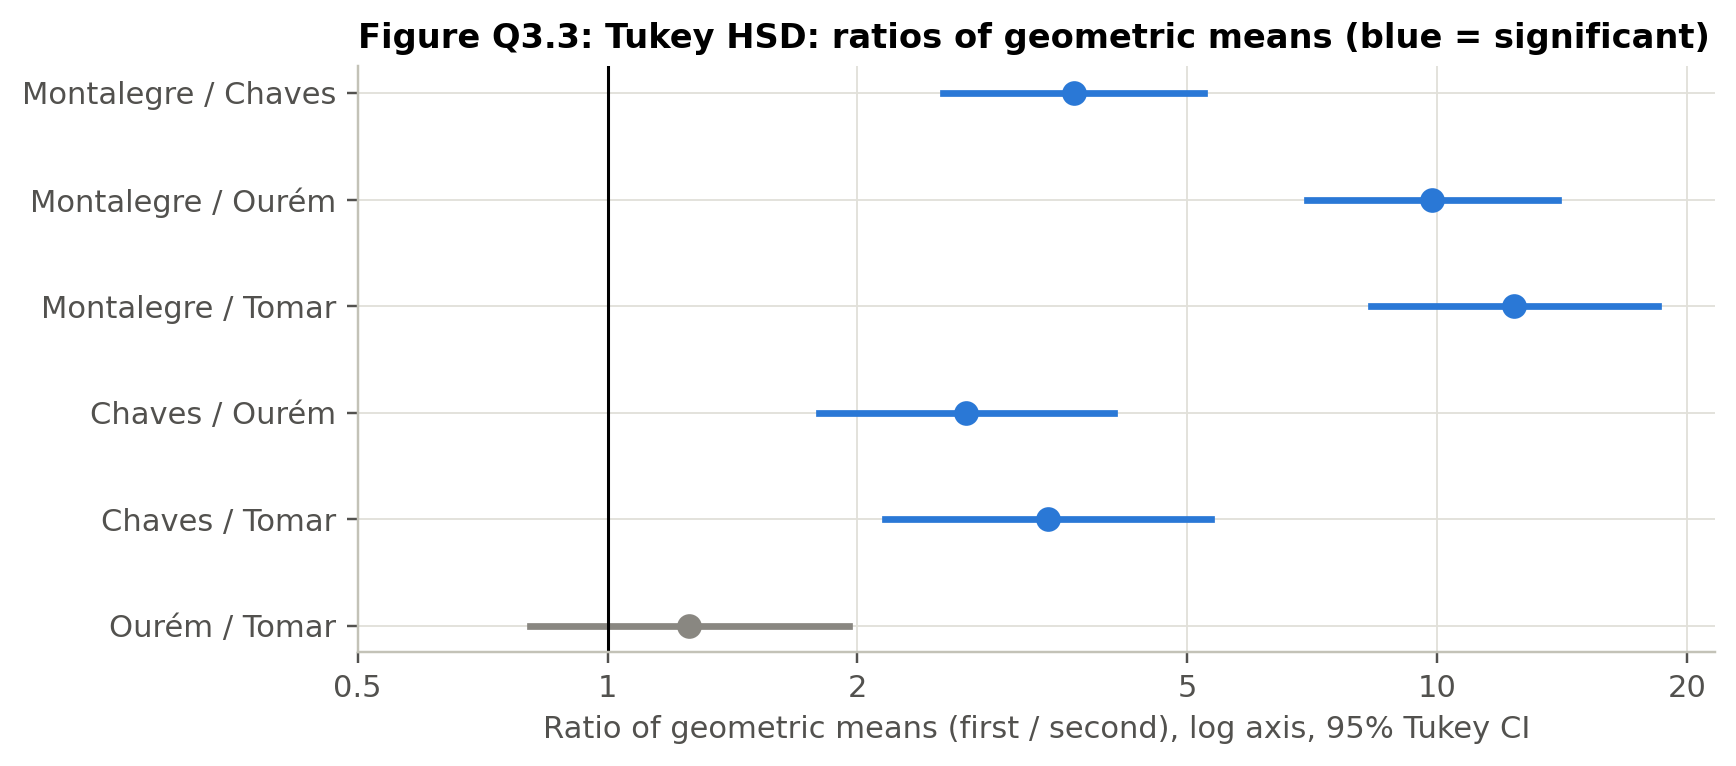

In [45]:
tk = stats.tukey_hsd(*log_groups)
ci = tk.confidence_interval(confidence_level=0.95)
order = np.argsort([-x.mean() for x in log_groups])            # larger geometric mean first

rows = []
for a_pos in range(k):
    for b_pos in range(a_pos + 1, k):
        i, j = order[a_pos], order[b_pos]
        rows.append({"comparison": f"{MUNICIPALITIES[i]} / {MUNICIPALITIES[j]}",
                     "difference in log10(area)": tk.statistic[i, j], "ratio of geometric means": 10 ** tk.statistic[i, j],
                     "95% CI low": 10 ** ci.low[i, j], "95% CI high": 10 ** ci.high[i, j],
                     "adjusted p": tk.pvalue[i, j], "significant": tk.pvalue[i, j] < 0.05,
                     "P(first > second)": stats.mannwhitneyu(raw_groups[i], raw_groups[j]).statistic
                                          / (len(raw_groups[i]) * len(raw_groups[j]))})
posthoc = pd.DataFrame(rows).set_index("comparison")
display(posthoc.round(3).assign(**{"adjusted p": posthoc["adjusted p"].map(lambda v: "< 0.0001" if v < 1e-4 else f"{v:.4f}")}))

# Figure Q3.3 - ratios of geometric means with 95% Tukey confidence intervals
fig, ax = plt.subplots(figsize=(8, 3.6))
ypos = np.arange(len(posthoc))[::-1]
for y_, (_, r) in zip(ypos, posthoc.iterrows()):
    col = BLUE if r["significant"] else "#898781"
    ax.plot([r["95% CI low"], r["95% CI high"]], [y_, y_], color=col, linewidth=2.2)
    ax.scatter(r["ratio of geometric means"], y_, s=50, color=col, zorder=3)
ax.axvline(1, color="black", linewidth=1)
ax.set_xscale("log")
ax.set_yticks(ypos, posthoc.index)
ax.set_xticks([0.5, 1, 2, 5, 10, 20], ["0.5", "1", "2", "5", "10", "20"])
ax.minorticks_off()
ax.set_xlabel("Ratio of geometric means (first / second), log axis, 95% Tukey CI")
ax.set_title("Figure Q3.3: Tukey HSD: ratios of geometric means (blue = significant)")
plt.tight_layout()
plt.show()

**Interpretation.** At a family-wise level of 5%:

- Montalegre has a larger geometric-mean burnt area than each of the other municipalities: about 3.6 times that of Chaves, 9.9 times Ourém and 12.4 times Tomar (adjusted p < 0.001).
- Chaves exceeds Ourém (about 2.7 times) and Tomar (about 3.4 times) (adjusted p < 0.001).
- Ourém and Tomar do not differ significantly (ratio 1.26, 95% CI 0.81 to 1.95, adjusted p = 0.55). This is not evidence that they are equal; the data are compatible with ratios from about 0.8 to 2.

Five of the six pairs therefore differ, giving the ordering Montalegre > Chaves > {Ourém, Tomar}.

**Practical size of the differences.** A randomly chosen fire in Montalegre burnt a larger area than one in Tomar in 75% of pairs, than one in Ourém in 73% and than one in Chaves in 63%; a fire in Chaves exceeded one in Ourém or Tomar in about 60% of pairs, whereas Ourém and Tomar were almost indistinguishable (51%). The differences are therefore clear but far from a complete separation: the distributions of the four municipalities overlap considerably.

#### Robustness checks

The primary result was repeated under six alternative decisions, namely Welch's ANOVA, standard errors clustered by alert date, a common 0.01 ha floor for very small fires, log10(area + 0.001) keeping the fire with 0 ha, the exclusion of the incomplete year 2025, and a year-by-year comparison. The full results are in Appendix A.2.

**Interpretation.** In every check the ANOVA remains highly significant (F between 110 and 143, p < 0.001), and Tukey HSD identifies the same five significant pairs. Montalegre has the largest and Chaves the second-largest geometric mean in each of the eight years. The size of the ratios, however, depends on how very small fires are recorded. With a common 0.01 ha floor, the Montalegre/Tomar ratio falls from 12.4 to 8.4, so the floor-based ratios are the more conservative estimates.

---

### 4.4 Q4: Two-way ANOVA

A two-way ANOVA was chosen because the response variable (`Log_Total_Burnt_Area`) is quantitative and there are two qualitative factors with two levels each, `Cause_Type` (Intentional, Negligent) and `Period` (Pre-2017, Post-2017). This design gives four groups and allows testing the effect of the cause, the effect of the period and the interaction between them. The research question is answered by the interaction term.

#### Terminology

- **$Y$**: the log10 of the burnt area of one fire (`Log_Total_Burnt_Area`), for intentional and negligent fires with an area above 0 ha.
- **$\mu_{ij}$**: the population mean of $Y$ for cause $i$ (I = intentional, N = negligent) in period $j$ (pre = Pre-2017, post = Post-2017); $10^{\mu_{ij}}$ is the geometric mean burnt area.
- **$\alpha$**: the significance level, set at 0.05.

#### Hypotheses

With sum-to-zero coding and Type III sums of squares, each main effect compares unweighted marginal means, that is, the average of the two cell means, whatever the number of fires in each cell.

**Cause_Type**

- **H₀:** $\frac{\mu_{I,pre} + \mu_{I,post}}{2} = \frac{\mu_{N,pre} + \mu_{N,post}}{2}$ (the mean of $Y$ is the same for intentional and negligent fires).
- **H₁:** $\frac{\mu_{I,pre} + \mu_{I,post}}{2} \neq \frac{\mu_{N,pre} + \mu_{N,post}}{2}$.

**Period**

- **H₀:** $\frac{\mu_{I,pre} + \mu_{N,pre}}{2} = \frac{\mu_{I,post} + \mu_{N,post}}{2}$ (the mean of $Y$ is the same before and after 2017).
- **H₁:** $\frac{\mu_{I,pre} + \mu_{N,pre}}{2} \neq \frac{\mu_{I,post} + \mu_{N,post}}{2}$.

**Interaction** (`Cause_Type × Period`)

- **H₀:** $\mu_{N,post} - \mu_{I,post} = \mu_{N,pre} - \mu_{I,pre}$ (the difference between causes is the same in both periods).
- **H₁:** $\mu_{N,post} - \mu_{I,post} \neq \mu_{N,pre} - \mu_{I,pre}$ (the difference between causes changes from one period to the other).

Q4 asks whether the gap narrowed, which is a one-sided question. The interaction is tested two-sided so that a change in either direction can be detected and reported.

#### Checking the assumptions

1. **Independence.** See the shared assumptions at the start of Section 4. Effect sizes are reported alongside the p-values, and the trend and step model in the robustness checks uses standard errors clustered by year.
2. **Normality.** It is checked below with histograms and normal Q-Q plots for each of the four Cause_Type × Period groups.
3. **Equal variances.** They are checked with the ratio of the largest to the smallest group standard deviation, following the criterion set at the start of Section 4, and with the Brown-Forsythe test.

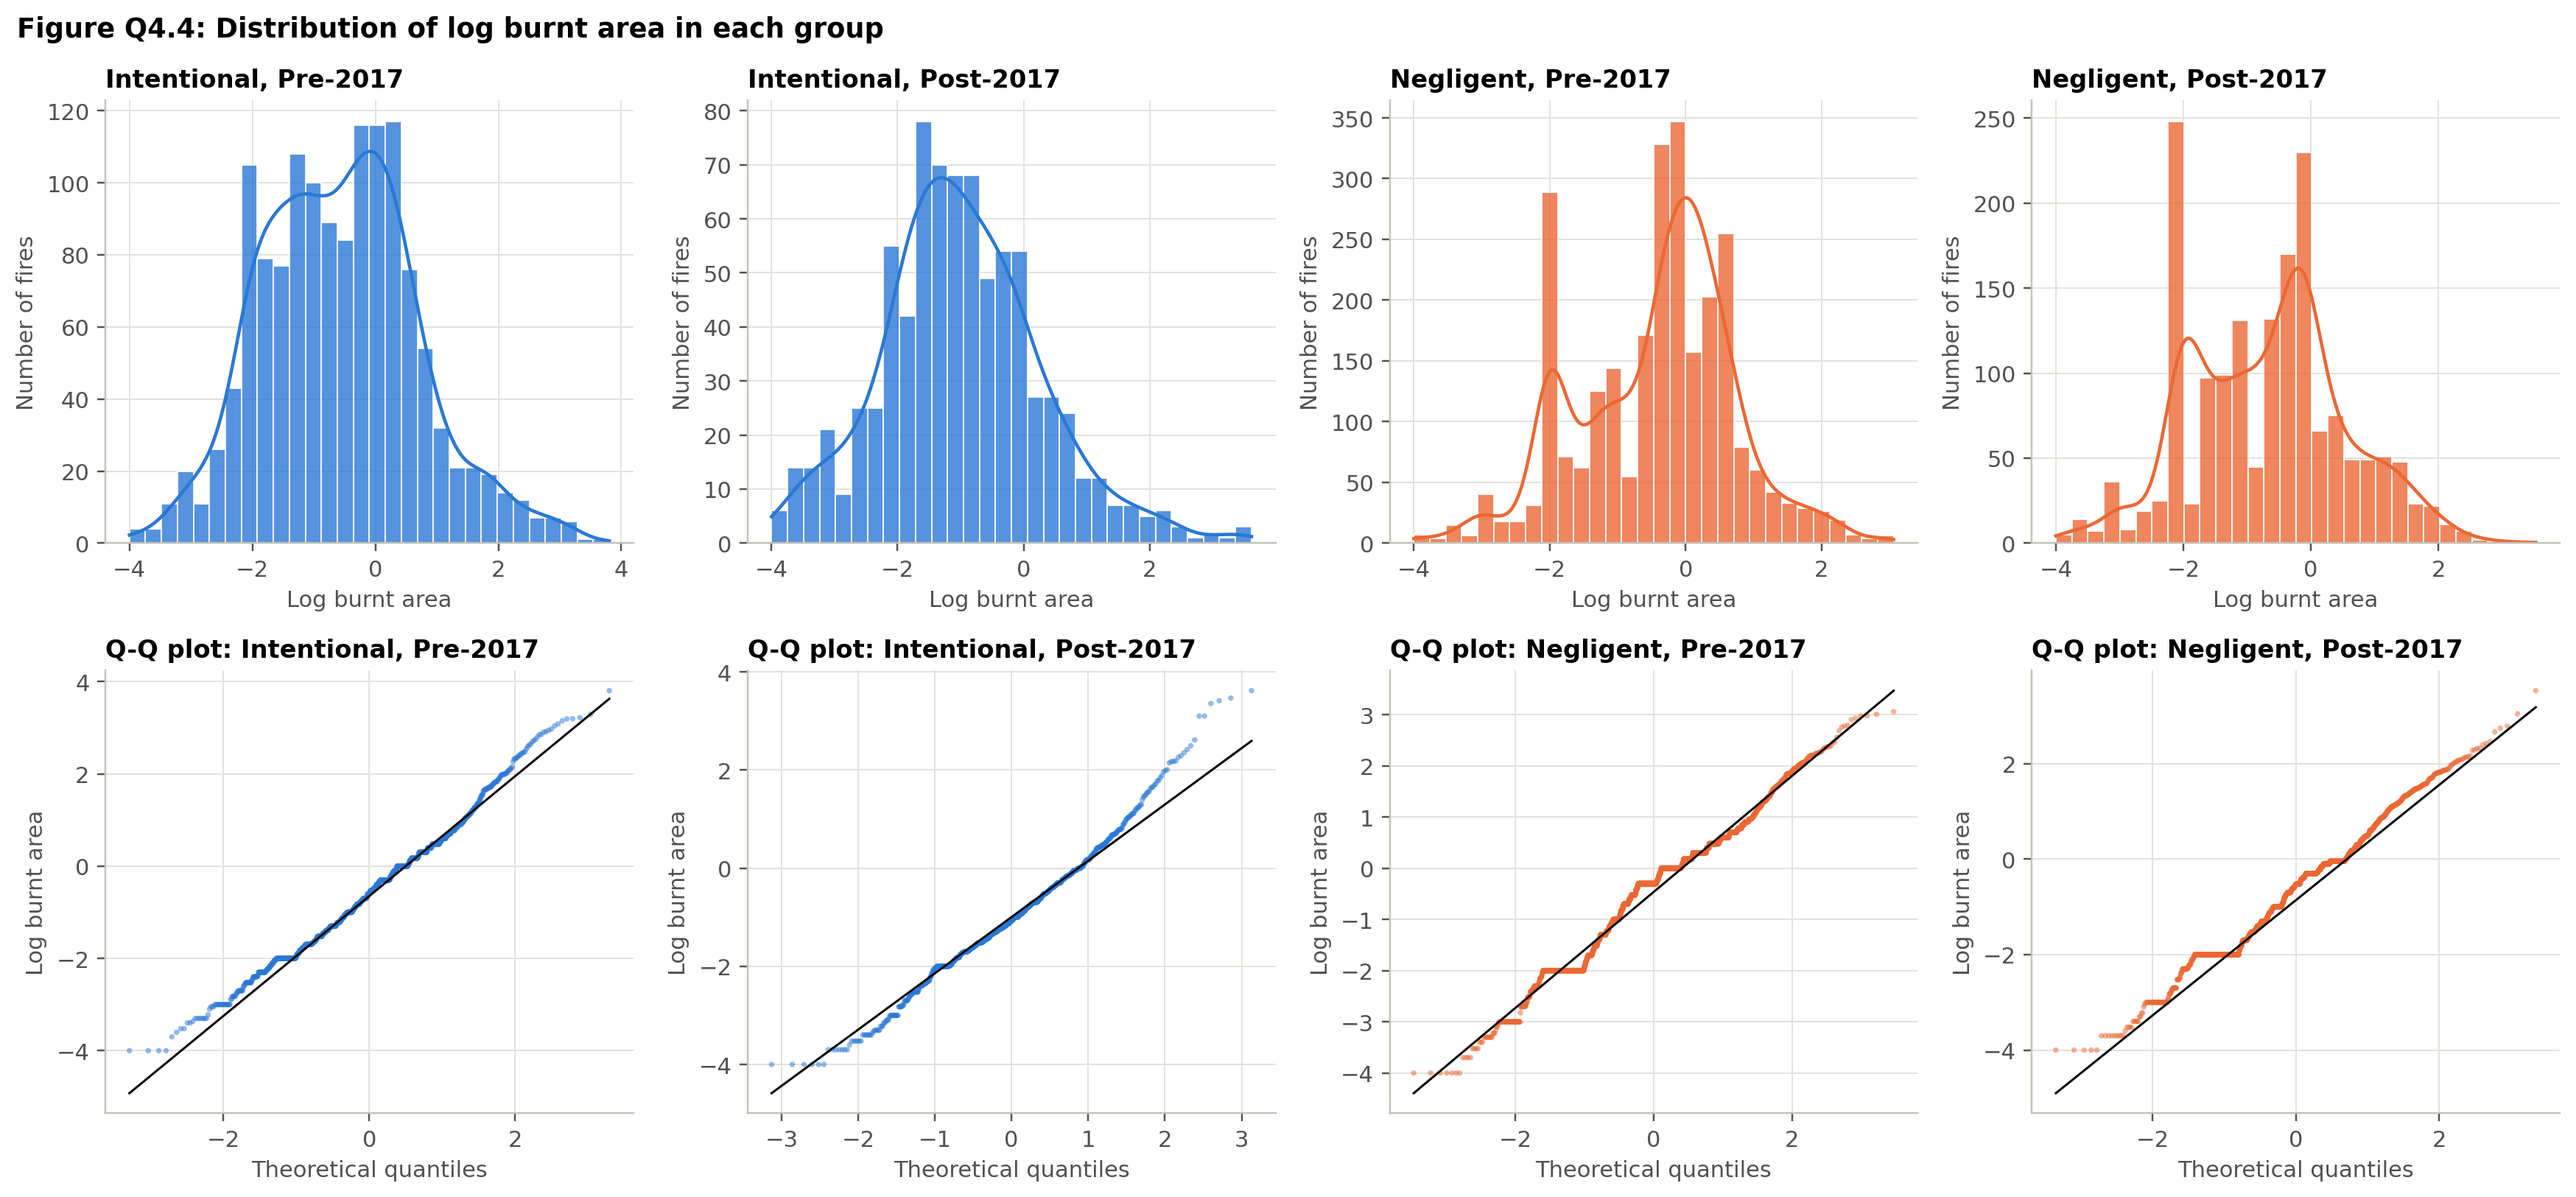

    Cause_Type     Period  Log_Total_Burnt_Area
0  Intentional   Pre-2017                 1.272
1  Intentional  Post-2017                 1.281
2    Negligent   Pre-2017                 1.149
3    Negligent  Post-2017                 1.221

Largest SD / smallest SD: 1.11
Brown-Forsythe test: W = 11.61, p = 1.39e-07


In [46]:
# Normality within each group
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for i, ((cause, period), g) in enumerate(q4.groupby(["Cause_Type", "Period"], observed=True)):
    x = g["Log_Total_Burnt_Area"]
    sns.histplot(x, bins=30, kde=True, color=PAL_CAUSE[cause], alpha=0.8, edgecolor=SURFACE, ax=axes[0, i])
    axes[0, i].set_title(f"{cause}, {period}")
    axes[0, i].set_xlabel("Log burnt area")
    axes[0, i].set_ylabel("Number of fires")
    qq_panel(axes[1, i], x, PAL_CAUSE[cause], f"Q-Q plot: {cause}, {period}", ylabel="Log burnt area")
fig_title(fig, "Figure Q4.4: Distribution of log burnt area in each group")
plt.tight_layout()
plt.show()

# Constant variance: standard deviation of each group
sd_q4 = q4.groupby(["Cause_Type", "Period"], observed=True)["Log_Total_Burnt_Area"].std()
print(sd_q4.round(3).reset_index())
print(f"\nLargest SD / smallest SD: {sd_q4.max() / sd_q4.min():.2f}")

# Complementary test for equal variances (Brown-Forsythe, i.e. median-centred Levene)
groups_q4 = [g["Log_Total_Burnt_Area"].values
             for _, g in q4.groupby(["Cause_Type", "Period"], observed=True)]
lev = stats.levene(*groups_q4, center="median")
print(f"Brown-Forsythe test: W = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

**Normality.** On the log scale, the distributions are much closer to symmetric than the original data, but they are not normal. The intentional groups have a longer right tail, which corresponds to a small number of very large fires. The negligent groups show two peaks (at about −2 and 0) caused by the many fires recorded with exactly 0.01 ha and 1 ha. These peaks reflect the rounding of the recorded areas and also explain the horizontal steps in the Q-Q plots. The boxplots in Figure Q4.1 show a few outliers in each group (at most 16), which are genuine fires and are not removed. With at least 789 fires per group, the group means are approximately normal (Section 4), so this departure is not a concern.

**Equal variances.** Equal variances cannot be claimed exactly, because the Brown-Forsythe test rejects homogeneity (p < 0.001). The standard deviations range from 1.15 to 1.28, so the largest is only 1.11 times the smallest, well below the limit of 2 set at the start of Section 4, and the classical two-way ANOVA is used. The ANOVA with heteroscedasticity-consistent standard errors (HC3), which does not assume equal variances, is reported as a robustness check in Appendix A.3.

#### Two-way ANOVA

The model includes the two main effects (Cause_Type and Period) and their interaction. Because the groups have different sizes, Type III sums of squares are used, so that each effect is tested after accounting for the others. Sum-to-zero coding is used so that each main effect is tested as an average across the levels of the other factor.

The effect size of each term is measured with partial eta squared (partial η²), which is the proportion of variability explained by the effect after removing the variability explained by the other effects. The usual reference values are 0.01 (small), 0.06 (medium) and 0.14 (large) (Cohen, 1988).

In [47]:
model_q4 = smf.ols(
    "Log_Total_Burnt_Area ~ C(Cause_Type, Sum) * C(Period, Sum)", data=q4
).fit()

anova_q4 = sm.stats.anova_lm(model_q4, typ=3)
ss_res = anova_q4.loc["Residual", "sum_sq"]
anova_q4["partial_eta_sq"] = anova_q4["sum_sq"] / (anova_q4["sum_sq"] + ss_res)
anova_q4.loc[["Intercept", "Residual"], "partial_eta_sq"] = np.nan
anova_q4.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
anova_q4.round(4)

,sum_sq,df,F,PR(>F),partial_eta_sq
Intercept,2371.8246,1.0,1617.0371,0.0000,NaN
Cause_Type,82.0506,1.0,55.9396,0.0000,0.0085
Period,147.1931,1.0,100.3517,0.0000,0.0152
Cause_Type x Period,8.7289,1.0,5.9511,0.0147,0.0009
Residual,9551.6190,6512.0,NaN,NaN,NaN


**Interpretation.** All three effects are significant at α = 0.05.

- **Cause_Type.** F(1, 6512) = 55.94, p < 0.001. Negligent fires have a larger typical burnt area.
- **Period.** F(1, 6512) = 100.35, p < 0.001. The mean log burnt area is lower after 2017.
- **Interaction.** F(1, 6512) = 5.95, p = 0.015. The difference between causes changes between periods.

The effect sizes are small. Only Period reaches a small effect (partial η² = 0.015), Cause_Type is below this threshold (0.009) and the interaction is negligible (0.0009). The interaction is statistically significant because the large sample can detect very small differences, but its practical relevance is very limited. In other words, in the full model the difference between causes changed between periods, but by an amount that is small compared with the natural variation in burnt area from fire to fire.

#### Post-hoc comparisons (simple effects)

Since the interaction is significant, the main effects alone do not fully describe the results. In a 2 x 2 design, the most direct follow-up is to compare each factor within each level of the other (simple effects). The two causes are compared within each period, which shows how the difference between causes behaves before and after 2017, and each cause is compared between periods, which shows how much each cause changed. Comparisons across both factors at once (for example, intentional fires before 2017 vs negligent fires after 2017) do not answer the research question and are not made.

In [48]:
# Simple effects: each factor compared within each level of the other
# (Welch t-tests, Bonferroni correction over the 4 comparisons)
K = 4
alpha_bonf = 0.05 / K
y = "Log_Total_Burnt_Area"

def welch_row(label, a, b):
    t = stats.ttest_ind(a, b, equal_var=False)
    diff = a.mean() - b.mean()
    return {"comparison": label, "diff_log": diff,
            "ratio_geom_means": 10 ** diff,
            "t": t.statistic, "p_value": t.pvalue}

rows = []
for p in PERIOD_ORDER:                      # cause within each period
    sub = q4[q4["Period"] == p]
    rows.append(welch_row(f"Negligent - Intentional, {p}",
                          sub.loc[sub["Cause_Type"] == "Negligent", y],
                          sub.loc[sub["Cause_Type"] == "Intentional", y]))
for c in CAUSE_ORDER:                       # period within each cause
    sub = q4[q4["Cause_Type"] == c]
    rows.append(welch_row(f"Post-2017 - Pre-2017, {c}",
                          sub.loc[sub["Period"] == "Post-2017", y],
                          sub.loc[sub["Period"] == "Pre-2017", y]))

simple_q4 = pd.DataFrame(rows).set_index("comparison")
simple_q4["significant (Bonferroni)"] = simple_q4["p_value"] < alpha_bonf
print(f"Bonferroni significance level: 0.05 / {K} = {alpha_bonf:.4f}")
simple_q4.round(4)

Bonferroni significance level: 0.05 / 4 = 0.0125


,diff_log,ratio_geom_means,t,p_value,significant (Bonferroni)
comparison,,,,,
"Negligent - Intentional, Pre-2017",0.1660,1.4656,4.0630,0.0,True
"Negligent - Intentional, Post-2017",0.3267,2.1218,6.0049,0.0,True
"Post-2017 - Pre-2017, Intentional",-0.4103,0.3888,-7.1960,0.0,True
"Post-2017 - Pre-2017, Negligent",-0.2496,0.5628,-6.7238,0.0,True


**Interpretation.** Four comparisons were made, each factor within each level of the other, using Welch's t-test and a Bonferroni-corrected significance level of 0.05 / 4 = 0.0125.

- **Cause within each period.** Negligent fires have a significantly larger mean log burnt area than intentional fires both before and after 2017 (both p < 0.001). Back-transformed, the ratio of geometric means is about 1.5 before 2017 and about 2.1 after.
- **Period within each cause.** Both causes had significantly smaller fires after 2017 (both p < 0.001). The mean log burnt area fell by 0.41 log units for intentional fires and by 0.25 for negligent fires, which corresponds to geometric means about 61% and 44% lower, respectively.

Both causes decreased after 2017, but intentional fires decreased more, which moved the two causes further apart. The robustness checks below show whether this change in the gap between causes holds when municipality and the unequal number of years are taken into account.

#### Robustness checks

Three checks test whether the conclusions depend on the mix of municipalities in each group, on the unequal number of years before and after 2017 and on differences in fire weather between the periods. Two further checks, on the equal-variance assumption and on the rule for fires with 0 ha, are reported in Appendix A.3 and lead to the same conclusions.

##### Controlling for municipality

The four municipalities differ in typical fire size. Fires in Montalegre and Chaves are larger (geometric means of 0.66 ha and 0.34 ha), while fires in Ourém and Tomar are much smaller (0.07 ha and 0.08 ha). The municipalities also do not contribute equally to each group. Ourém accounts for 46% of intentional fires after 2017, compared with 26% before, while Montalegre accounts for more than half of all negligent fires. A change in the mix of municipalities could therefore create an apparent interaction. To check this, Municipality (`Concelho`) was added to the model as a blocking factor.

In [49]:
# Typical burnt area in each municipality
mun_q4 = q4.groupby("Concelho").agg(
    n=("Log_Total_Burnt_Area", "size"),
    mean_log=("Log_Total_Burnt_Area", "mean"),
    median_ha=("Total_Burnt_Area", "median"),
)
mun_q4["geom_mean_ha"] = 10 ** mun_q4["mean_log"]
mun_q4.sort_values("mean_log", ascending=False).round(3)

,n,mean_log,median_ha,geom_mean_ha
Concelho,,,,
Montalegre,2682,-0.179,0.960,0.663
Chaves,1501,-0.464,0.500,0.344
Tomar,1134,-1.112,0.076,0.077
Ourém,1199,-1.142,0.064,0.072


In [50]:
pd.crosstab(q4["Cause_Type_Period"], q4["Concelho"], normalize="index").round(2)

Concelho,Chaves,Montalegre,Ourém,Tomar
Cause_Type_Period,,,,
Intentional_Post-2017,0.18,0.11,0.46,0.25
Intentional_Pre-2017,0.29,0.15,0.26,0.31
Negligent_Post-2017,0.20,0.57,0.11,0.12
Negligent_Pre-2017,0.23,0.54,0.11,0.12


In [51]:
model_q4_mun = smf.ols(
    "Log_Total_Burnt_Area ~ C(Concelho, Sum) + C(Cause_Type, Sum) * C(Period, Sum)",
    data=q4
).fit()
anova_q4_mun = sm.stats.anova_lm(model_q4_mun, typ=3)
anova_q4_mun.index = ["Intercept", "Municipality", "Cause_Type", "Period",
                      "Cause_Type x Period", "Residual"]
anova_q4_mun.round(4)

,sum_sq,df,F,PR(>F)
Intercept,2849.2668,1.0,2192.8991,0.0000
Municipality,1094.3772,3.0,280.7575,0.0000
Cause_Type,35.8052,1.0,27.5570,0.0000
Period,103.7255,1.0,79.8309,0.0000
Cause_Type x Period,0.5011,1.0,0.3857,0.5346
Residual,8457.2418,6509.0,NaN,NaN


**Interpretation.** With municipality in the model, cause type and period remain significant (p < 0.001), but the interaction does not (F = 0.39, p = 0.53). The wider gap after 2017 can therefore be explained by a change in where fires occurred, mainly the larger share of intentional fires in Ourém, and not necessarily by a change in the relationship between cause and fire size.

##### Balanced windows and pre-2017 trend

The pre-2017 period covers twice as many years as the post-2017 period, so a gradual change in fire size over time could appear as a Period effect. Two checks are applied:

1. **Balanced windows.** The two-way ANOVA is repeated with 8 years on each side of 2017 (2009–2016 vs. 2018–2025).
2. **Trend and step model.** A linear regression with a separate linear trend and a separate step at 2017 for each cause (`Log_Total_Burnt_Area ~ neg * (year_c + post)`). The step answers whether fire size changed at 2017 beyond the trend, and the term `neg:post` answers whether that change differed between causes, which is the question of Q4. Standard errors are clustered by year.

In [52]:
# Check 1: balanced windows (8 years before vs 8 years after 2017)
q4_bal = q4[q4["Ano"].between(2009, 2025)].copy()
print(pd.crosstab(q4_bal["Cause_Type"], q4_bal["Period"], margins=True))

model_q4_bal = smf.ols(
    "Log_Total_Burnt_Area ~ C(Cause_Type, Sum) * C(Period, Sum)", data=q4_bal
).fit()
anova_q4_bal = sm.stats.anova_lm(model_q4_bal, typ=3)
ss_res_bal = anova_q4_bal.loc["Residual", "sum_sq"]
anova_q4_bal["partial_eta_sq"] = anova_q4_bal["sum_sq"] / (anova_q4_bal["sum_sq"] + ss_res_bal)
anova_q4_bal.loc[["Intercept", "Residual"], "partial_eta_sq"] = np.nan
anova_q4_bal.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
anova_q4_bal.round(4)

Period       Pre-2017  Post-2017   All
Cause_Type                            
Intentional      1069        789  1858
Negligent        2294       1695  3989
All              3363       2484  5847


,sum_sq,df,F,PR(>F),partial_eta_sq
Intercept,2621.6905,1.0,1879.7813,0.0000,NaN
Cause_Type,115.9231,1.0,83.1182,0.0000,0.0140
Period,49.4454,1.0,35.4529,0.0000,0.0060
Cause_Type x Period,0.5367,1.0,0.3848,0.5351,0.0001
Residual,8149.1065,5843.0,NaN,NaN,NaN


In [53]:
# Check 2: trend + step at 2017 for each cause (OLS, SE clustered by year)
q4_its = q4.assign(neg=(q4["Cause_Type"] == "Negligent").astype(int),
                   post=(q4["Period"] == "Post-2017").astype(int),
                   year_c=q4["Ano"] - 2017)

model_q4_its = smf.ols("Log_Total_Burnt_Area ~ neg * (year_c + post)", data=q4_its).fit(
    cov_type="cluster", cov_kwds={"groups": q4_its["Ano"].to_numpy()})

terms = {"year_c": "Trend per year, intentional",
         "neg:year_c": "Difference in trend (negligent - intentional)",
         "post": "Step at 2017, intentional",
         "neg:post": "Difference in step (negligent - intentional)"}
ci_its = model_q4_its.conf_int()
its_tab = pd.DataFrame({
    "estimate (log10 units)": model_q4_its.params[list(terms)],
    "95% CI low": ci_its.loc[list(terms), 0],
    "95% CI high": ci_its.loc[list(terms), 1],
    "p-value": model_q4_its.pvalues[list(terms)],
}).rename(index=terms)
print(its_tab.round(4).to_string())

step_neg = model_q4_its.t_test("post + neg:post = 0")
step_avg = model_q4_its.t_test("post + 0.5 * neg:post = 0")
print(f"\nStep at 2017, negligent      : {float(np.squeeze(step_neg.effect)):.4f} (p = {float(np.squeeze(step_neg.pvalue)):.4f})")
print(f"Step at 2017, average of both: {float(np.squeeze(step_avg.effect)):.4f} (p = {float(np.squeeze(step_avg.pvalue)):.4f})")

                                               estimate (log10 units)  95% CI low  95% CI high  p-value
Trend per year, intentional                                   -0.0797     -0.1309      -0.0286   0.0023
Difference in trend (negligent - intentional)                  0.0351      0.0012       0.0689   0.0425
Step at 2017, intentional                                      0.4271     -0.1597       1.0140   0.1537
Difference in step (negligent - intentional)                  -0.2578     -0.6325       0.1168   0.1774

Step at 2017, negligent      : 0.1693 (p = 0.4093)
Step at 2017, average of both: 0.2982 (p = 0.2106)


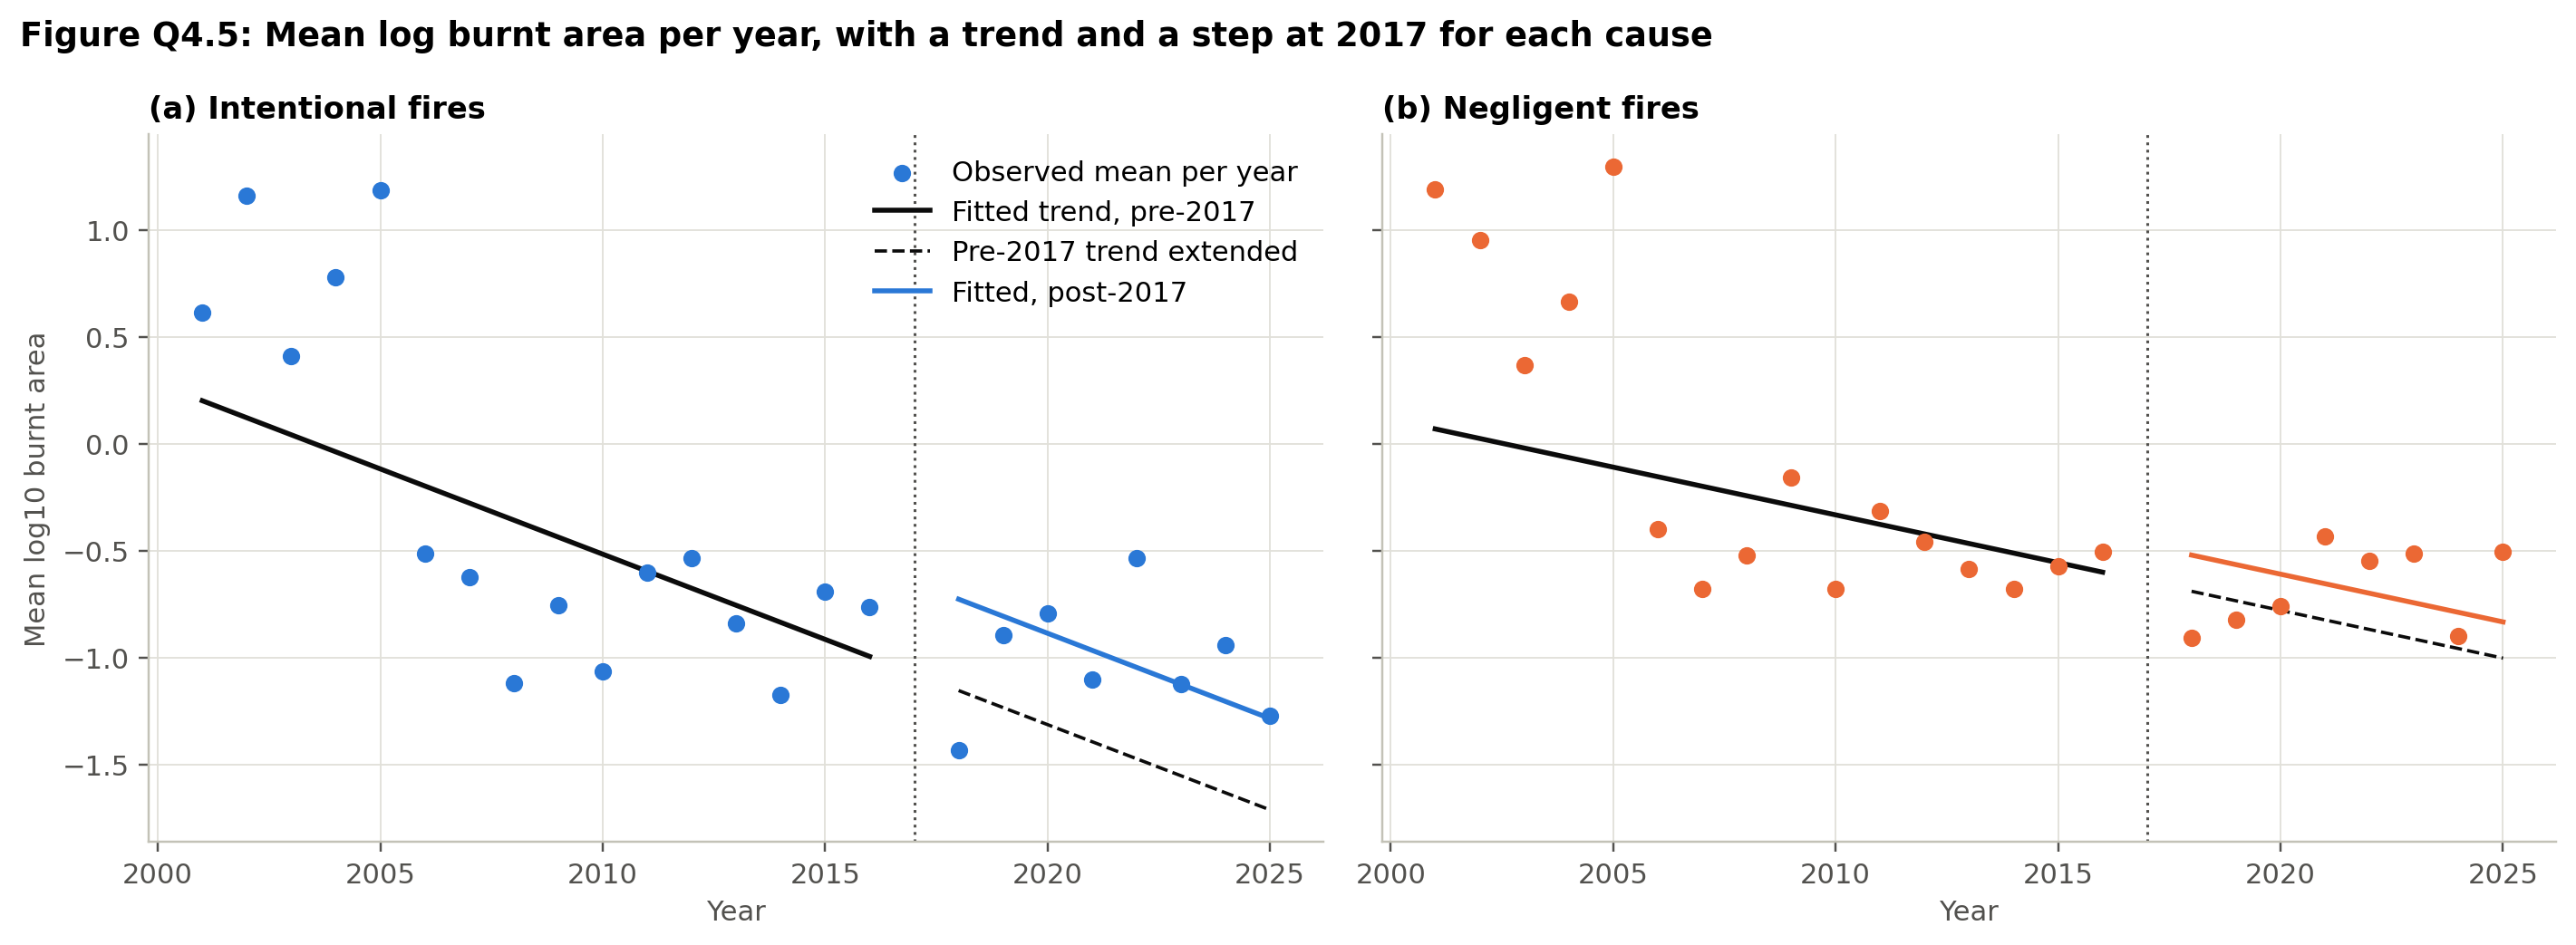

In [54]:
yearly_q4 = (q4.groupby(["Ano", "Cause_Type"], observed=True)["Log_Total_Burnt_Area"]
               .mean().reset_index())
years_pre, years_post = np.arange(2001, 2017), np.arange(2018, 2026)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for tag, ax, cause in zip("ab", axes, CAUSE_ORDER):
    flag = int(cause == "Negligent")
    def pred(yrs, post):
        return model_q4_its.predict(pd.DataFrame({"neg": flag, "year_c": yrs - 2017, "post": post}))
    obs = yearly_q4[yearly_q4["Cause_Type"] == cause]
    ax.scatter(obs["Ano"], obs["Log_Total_Burnt_Area"], color=PAL_CAUSE[cause], s=28, zorder=3, label="Observed mean per year")
    ax.plot(years_pre, pred(years_pre, 0), color=INK, linewidth=1.8, label="Fitted trend, pre-2017")
    ax.plot(years_post, pred(years_post, 0), color=INK, linewidth=1.2, linestyle="--", label="Pre-2017 trend extended")
    ax.plot(years_post, pred(years_post, 1), color=PAL_CAUSE[cause], linewidth=1.8, label="Fitted, post-2017")
    ax.axvline(2017, color=MUTED, linestyle=":", linewidth=1)
    ax.set_title(f"({tag}) {cause} fires")
    ax.set_xlabel("Year")
axes[0].set_ylabel("Mean log10 burnt area")
axes[0].legend(loc="upper right")
fig_title(fig, "Figure Q4.5: Mean log burnt area per year, with a trend and a step at 2017 for each cause")
plt.tight_layout()
plt.show()

**Interpretation.** With balanced windows (2009–2016 vs. 2018–2025), Cause_Type remains significant and becomes stronger (F = 83.12, p < 0.001, partial η² = 0.014). Period remains significant, but its effect is much smaller (F = 35.45, p < 0.001, partial η² = 0.006, below the threshold for a small effect, compared with F = 100.35 and 0.015 in the full analysis). The interaction is no longer significant (F = 0.38, p = 0.54), so the significant interaction found with the full period depends on the years 2001–2008.

In the trend and step model, fire size was already decreasing before 2017. The mean log burnt area of intentional fires fell by 0.080 log units per year (95% CI 0.029 to 0.131, p = 0.002) and that of negligent fires by about 0.045 log units per year, a significantly slower decrease (difference in trend p = 0.043). There is no step down at 2017. The average step is positive and not significant (0.30, p = 0.21), and so are the steps for intentional (0.43, p = 0.15) and negligent fires (0.17, p = 0.41). The difference in step between causes is not significant either (−0.26, p = 0.18).

Figure Q4.5 shows that much of the pre-2017 trend comes from 2001–2005, whose yearly means are far above those of later years, followed by a sharp drop around 2006. From 2006 onwards the yearly means change little. This pattern may reflect differences in how small fires were recorded in the oldest files rather than a real change in fire size, so the linear trend should be read with caution.

The Period effect of the two-way ANOVA therefore mostly reflects a decrease in fire size that was already under way before 2017, and cannot be attributed to the post-2017 period itself. There is no evidence that the gap between causes changed at 2017. In both analyses, the gap did not narrow.

##### Controlling for fire weather

If the years after 2017 had milder fire weather, the smaller fires of that period could reflect the weather rather than a change in the fires themselves. The two-way ANOVA is therefore repeated with the Fire Weather Index (FWI) as a covariate.

In [55]:
model_q4_fwi = smf.ols("Log_Total_Burnt_Area ~ FWI + C(Cause_Type, Sum) * C(Period, Sum)", data=q4_fwi).fit()
anova_q4_fwi = sm.stats.anova_lm(model_q4_fwi, typ=3)
anova_q4_fwi = anova_q4_fwi.rename(index={
    "C(Cause_Type, Sum)": "Cause_Type",
    "C(Period, Sum)": "Period",
    "C(Cause_Type, Sum):C(Period, Sum)": "Cause_Type x Period",
})
display(anova_q4_fwi.round(4))
print(f"n = {len(q4_fwi):,} of {len(q4):,} fires (FWI missing for {len(q4) - len(q4_fwi)})")
print(f"FWI coefficient: {model_q4_fwi.params['FWI']:.4f} log10 units per FWI point "
      f"(10 FWI points multiply the geometric mean by {10 ** (10 * model_q4_fwi.params['FWI']):.2f})")

,sum_sq,df,F,PR(>F)
Intercept,319.4156,1.0,219.9446,0.0000
Cause_Type,19.2152,1.0,13.2313,0.0003
Period,153.4236,1.0,105.6451,0.0000
Cause_Type x Period,4.0822,1.0,2.8109,0.0937
FWI,93.1812,1.0,64.1631,0.0000
Residual,9397.5409,6471.0,NaN,NaN


n = 6,476 of 6,516 fires (FWI missing for 40)
FWI coefficient: -0.0090 log10 units per FWI point (10 FWI points multiply the geometric mean by 0.81)


**Interpretation.** FWI is significantly associated with burnt area (F = 64.16, p < 0.001), but in the opposite direction to what fire danger alone would suggest: an increase of 10 points in FWI multiplies the typical burnt area by 0.81. FWI also reflects the season. High-FWI days fall mostly in the critical period, when surveillance and suppression resources are at their highest, while most negligent fires occur in cooler months with low FWI (Figure Q4.3). One possible explanation, which these data cannot test, is that fires on high-danger days are detected and attacked faster. Because FWI is strongly linked to the season, its coefficient mixes fire weather with seasonal differences in fuel, land use and suppression effort, and it should not be read as a causal effect of weather.

With FWI in the model, the Period effect remains significant (F = 105.65, p < 0.001, against F = 100.35 without FWI) and the interaction is not significant (F = 2.81, p = 0.094). The Cause_Type effect is smaller (F = 13.23, against 55.94), because part of the difference between causes is associated with the weather conditions in which each type of fire occurs. The decrease in fire size after 2017 is therefore not explained by differences in fire weather between the periods.

---

<a id="5-formulate-conclusions"></a>
## 5) Formulate Conclusions

This section gathers the answer to each secondary research question, based on the inferences drawn in Section 4.

### 5.1 Q1: Changes in Negligent Causes

#### Statistical decision (α = 0.05)

- **Critical period.** The two-proportion Z-test gives Z = −4.79 and p < 0.001, so H₀ is rejected. Among fires with a recorded human cause, the share of negligent fires fell from 55.7% before 2017 to 47.4% after 2017 (OR = 0.72, 95% CI 0.62 to 0.82).
- **Non-critical period.** The test gives Z = 4.10 and p < 0.001, so H₀ is also rejected, but the change goes in the opposite direction. The negligent share rose from 82.6% to 88.2% (OR = 1.57, 95% CI 1.26 to 1.95).
- **Comparison between seasons.** The Breslow-Day test (χ²(1) = 36.50, p < 0.001) and the likelihood-ratio test of the `Period × Season_Risk_Period` interaction (χ²(1) = 36.83, p < 0.001) show that the change after 2017 differed significantly between seasons (ratio of odds ratios of 2.19, 95% CI 1.70 to 2.83).
- **Controlling for municipality.** Within municipalities, the critical-period change is not significant (Mantel-Haenszel OR = 0.95, p = 0.54), whereas the non-critical increase remains (OR = 1.49, p < 0.001), and the difference between seasons is still significant (χ²(1) = 10.95, p < 0.001; Appendix A.1).

#### Interpretation

The change after 2017 differed between the two seasons. In the non-critical months the negligent share rose, also within municipalities. In the critical period, the pooled decrease reflects mainly the larger share of fires from Ourém, and it does not appear within the other municipalities.

A share can change because its numerator or its denominator changes. In the critical period, the annual mean of negligent fires fell (from 88.2 to 72.0 per year) while that of intentional fires rose (from 70.0 to 79.9), so the lower negligent share reflects both movements and cannot be read as an improvement in prevention alone. In the non-critical months, the annual mean of negligent fires almost doubled (from 77.6 to 140.0 per year). This increase coincides with the rise in the share of fires with a recorded human cause, from 36.4% to 90.7%, so it may reflect more complete cause investigation rather than more negligent ignitions. The data therefore show that the composition of recorded human causes changed differently in the two seasons, but they do not allow this change to be attributed to prevention measures or to a change in behaviour.

### 5.2 Q2: Daily Negligent Ignitions on Weekends and Weekdays

#### Statistical decision (α = 0.05)

- **All calendar days (primary test).** The mean was 0.1617 negligent ignitions per municipality-day on weekends (n = 3,272) and 0.1425 on weekdays (n = 8,188). The difference of 0.019 (ratio of 1.134, or +13.4%) gives Welch's t(5312.2) = 1.468 and p = 0.142, with a 95% CI from −0.006 to 0.045 (−4.5% to +31.4% of the weekday mean), so H₀ is not rejected.
- **Active days (complementary test).** The mean was 1.570 (SD = 1.402, n = 337) on weekends and 1.455 (SD = 1.161, n = 802) on weekdays, with a median of 1 in both groups. The difference of 0.115 (SE = 0.087) gives Welch's t(538.6) = 1.322 and p = 0.187, with a 95% CI from −0.056 to 0.285 (−3.8% to +19.6% of the weekday mean) and Cohen's d = 0.09, so H₀ is not rejected.
- **Robustness checks.** With standard errors clustered by date, the conclusion is the same over all calendar days (p = 0.193) and on active days (p = 0.196). When the active-day analysis is repeated within each municipality, all four 95% confidence intervals include zero and every p-value is above 0.05, and therefore also above the Bonferroni threshold of 0.0125.

#### Interpretation

There is not enough evidence that the mean number of daily negligent ignitions differed between weekends and weekdays after 2017. This does not show that the means are equal. The data are compatible with no difference, but also with a weekend increase of up to about one third over all calendar days, or about 20% on active days.

Because E[Y] = P(Y ≥ 1) × E[Y | Y ≥ 1], the mean over all days combines the probability of an active day (10.3% on weekends and 9.8% on weekdays, Z = 0.816, p = 0.415) and the mean count on active days (1.570 and 1.455, p = 0.187). Both components show a small, non-significant weekend excess in the pooled data. Within municipalities, the difference on active days was positive in Chaves, Montalegre and Ourém and slightly negative in Tomar (−0.04), and none was significant.

### 5.3 Q3: Burnt Area across Municipalities

#### Statistical decision (α = 0.05)

- **One-way ANOVA.** The mean log burnt area per fire differed significantly across the four municipalities in 2018–2025 (F(3, 2734) = 140.4, p < 0.001, η² = 0.13; n = 2,738), so H₀ is rejected. The geometric mean was highest in Montalegre (0.50 ha), followed by Chaves (0.14 ha), Ourém (0.05 ha) and Tomar (0.04 ha).
- **Tukey HSD.** Montalegre's geometric mean was 3.6 to 12.4 times those of the other municipalities, and Chaves's was 2.7 to 3.4 times those of Ourém and Tomar, while Ourém and Tomar could not be distinguished (ratio 1.26, 95% CI 0.81 to 1.95).
- **Robustness checks.** The result held with Welch's ANOVA, with standard errors clustered by alert date, with log10(area + 0.001) keeping the fire with 0 ha, without the incomplete year 2025, and when all areas below 0.01 ha were set to 0.01 ha (Appendix A.2). Montalegre had the largest and Chaves the second-largest geometric mean in each of the eight years. In the analysis with a common 0.01 ha floor, which compares the municipalities at the same recording resolution, the ratios were smaller (for example, 8.4 instead of 12.4 for Montalegre/Tomar): the ordering is robust, but the size of the ratios partly reflects how very small fires are recorded.

#### Interpretation

These results compare geometric means, that is, differences on a multiplicative scale; they are not a comparison of arithmetic mean burnt areas in hectares, for which the descriptive ranking is different (Chaves has the highest arithmetic mean) because a few very large fires dominate each mean. Because arithmetic means are dominated by a few extreme fires, these data do not support a reliable comparison of the expected burnt area per fire or of total burnt area, and Q3 makes no claim about either. In relative terms the differences are substantial (a fire in Montalegre burnt more than one in Tomar in 75% of pairs), but in absolute terms they are small: all geometric means are below 1 ha, whereas most of the total burnt area comes from rare extreme fires, which the log scale deliberately down-weights.

### 5.4 Q4: Burnt Area by Cause Type and Period

#### Statistical decision (α = 0.05)

- **Two-way ANOVA.** Cause_Type (F(1, 6512) = 55.94, p < 0.001) and Period (F(1, 6512) = 100.35, p < 0.001) are significant, and so is the interaction (F(1, 6512) = 5.95, p = 0.015), so the three null hypotheses are rejected. The interaction, however, has a negligible effect size (partial η² = 0.0009). The typical negligent fire was larger than the typical intentional fire in both periods, and fires of both causes were smaller after 2017.
- **Robustness checks.** The interaction disappears when municipality is included in the model (p = 0.53), when the comparison is limited to 8 years on each side of 2017 (p = 0.54) and when FWI is added as a covariate (p = 0.094). The effect of the cause type remains significant in every version of the analysis. With balanced windows the period effect is much smaller (partial η² = 0.006), and the trend and step model shows no step at 2017.

#### Interpretation

The disparity in final burnt area between intentional and negligent fires did not narrow after 2017. The effect of the cause type is the most stable result of Q4, whereas the significant interaction of the full model is very small and does not hold once municipality, the unequal number of years or fire weather are taken into account, so there is no consistent evidence that the gap between causes changed between periods.

Fires of both causes were smaller after 2017, but this reduction cannot be attributed to the post-2017 period. The yearly data show a decrease that was already under way before 2017, mostly concentrated in the early 2000s, and the period effect remains when fire weather is controlled for (F = 105.65, p < 0.001), so it is not explained by milder weather. Over the whole period, the typical intentional fire became smaller faster than the typical negligent one, although intentional fires include the largest events, as shown by their much higher arithmetic mean.

Since this is an observational study, and the post-2017 period mixes years before and after the 2021 law, none of these changes can be attributed to specific policy measures.

### 5.5 Overall Answer

The main question asked how human-caused ignitions and their burnt area changed before and after 2017, and how they differ across Chaves, Montalegre, Ourém and Tomar.

**Ignitions (Q1 and Q2).** Among fires with a recorded human cause, the change after 2017 depended on the season. In the remaining months, the share of negligent fires rose from 82.6% to 88.2%, and this increase holds within municipalities. In the critical period (June to September), the pooled share fell from 55.7% to 47.4%, but this decrease reflects mainly the larger share of fires from Ourém, where most human-caused fires are intentional, and it does not appear within the other municipalities. The difference between the two seasons is significant (Breslow-Day χ²(1) = 36.50, p < 0.001) and remains so within municipalities (χ²(1) = 10.95, p < 0.001). After 2017, the number of negligent ignitions per day did not differ significantly between weekends and weekdays, either on days with at least one ignition (p = 0.187) or over all calendar days (p = 0.142), and the same held in each municipality. The comparisons between periods should be read with the change in cause recording in mind, since only 36.4% of the pre-2017 fires have a recorded human cause, against 90.7% after 2017.

**Burnt area (Q3 and Q4).** In 2018–2025, the typical burnt area per fire differed clearly between the municipalities. It was largest in Montalegre, followed by Chaves, while Ourém and Tomar could not be distinguished, and this ordering held in each of the eight years. Between periods, the typical fire with a known human cause was smaller after 2017 for both causes, and negligent fires were larger than intentional ones in every model. The difference between causes did not narrow. The significant interaction of the full model was very small (partial η² = 0.0009) and disappeared once municipality was included, the periods were limited to eight years each, or fire weather was taken into account. The decrease in fire size was already under way before 2017, so it cannot be attributed to the post-2017 period. It is also not explained by milder fire weather, since the period effect remains after controlling for the Fire Weather Index (F = 105.65, p < 0.001).

**Overall.** Around 2017, the balance between negligent and intentional causes changed differently in summer and in the rest of the year, while the typical fire with a recorded human cause became smaller as part of a longer trend that weather does not explain. None of these changes can be linked to a specific measure. Municipality was the factor with the clearest and most stable association with fire size, and changes in the mix of municipalities between periods were enough to create an apparent change in Q1 and Q4, which shows that local conditions must be taken into account when the four municipalities are analysed together.

---

<a id="6-look-back-and-ahead"></a>
## 6) Look Back and Ahead

### 6.1 Limitations

#### Dataset
1. **Gradual reform.** The Period split is set at 2017, but the reform that followed was introduced gradually, and Decreto-Lei n.º 82/2021 only dates from October 2021. The post-2017 group therefore mixes years before and after the new system, so no change between periods can be attributed to a specific measure.
2. **Cause recording.** The share of fires with a recorded human cause (intentional or negligent) rose from 36.4% before 2017 to 90.7% after 2017 in the four municipalities. Before 2017, Q1 and Q4 therefore rely on about one third of the fires, and it is not known how those fires were selected for cause investigation. If larger or more visible fires were investigated more often, the pre-2017 sample is not representative of all fires. This affects the comparisons between periods (Q1 and Q4) more than the comparisons within the post-2017 period (Q2 and Q3).
3. **Rounded areas.** Burnt area appears to be estimated rather than measured for small fires, since rounded values such as 0.01, 0.5, 1 and 2 ha are much more frequent than intermediate values. This adds measurement error to the response variable of Q3 and Q4 and explains why the log burnt area is not normally distributed.
4. **Municipality composition.** In Q1, it explains most of the pooled decrease in the negligent share in the critical period, which does not appear within municipalities (Appendix A.1). In Q4, this change in composition was enough to produce a significant interaction that disappeared once municipality was added to the model, so results based on the pooled data should be read with this in mind.
5. **Unequal periods.** The pre-2017 period covers 16 years and the post-2017 period only 8, with 2025 incomplete. This does not bias the tests, which compare proportions and means, but the two periods are centred about 13 years apart, so a gradual change over time can look like a post-2017 effect. For Q4, this was checked in Section 4.4 with balanced windows of 8 years on each side of 2017 and with a model including a trend and a step at 2017. The effect of the cause type holds and the interaction is not significant in either check. The period effect remains significant, but its size becomes negligible (partial η² below 0.01), and it reflects a decrease in fire size that started well before 2017. The high burnt areas recorded in 2001–2005 are discussed in the Q4 limitations below.

#### Q1: Changes in negligent causes

1. **Recorded human cause.** Q1 compares the composition of fires with a recorded human cause. Because cause recording rose from 36.4% to 90.7%, the pre-2017 proportions rest on about one third of the fires, and a change in which fires were investigated could change the negligent share without any change in behaviour.
2. **Proportions rather than counts.** A share can change because its numerator or its denominator changes. The annual means in Section 3.1 show that both negligent and intentional fires changed, so the proportions alone do not show whether negligent ignitions became more or less frequent.
3. **Operational critical period.** The critical period is defined here as June to September, whereas under Decreto-Lei n.º 124/2006 the legal period ran by default from July to September. The results refer to the operational definition.
4. **Independence.** The Z-tests and the chi-square tests treat each fire as independent. Fires in the same year or on the same day share weather and local conditions, so the p-values may be somewhat too small. Unlike Q2, Q3 and the trend and step model of Q4, Q1 does not use clustered standard errors.
5. **Incomplete 2025.** The 2025 records end on 4 November, so most of November and December, months of traditional burnings in which most fires are negligent, are missing from the non-critical post-2017 group. This slightly underestimates the post-2017 negligent share in the non-critical months.

#### Q2: Daily negligent ignitions

1. **Active days and all calendar days.** The file `q2_daily_ignitions.xlsx` contains only active municipality-days, so the full calendar of 11,460 municipality-days had to be rebuilt in Section 4.2 to answer Q2 as it is stated. Both analyses reach the same conclusion, but the confidence interval over all days is wider in relative terms (−4.5% to +31.4% of the weekday mean).
2. **Spatial and temporal dependence.** The two-sample t-test assumes independent observations. Ignitions in neighbouring municipalities (for example, Chaves and Montalegre) or on consecutive days are often exposed to the same weather systems, such as heat waves or dry winds. Standard errors clustered by date account for the dependence between municipalities on the same day, but not for the dependence between consecutive days.
3. **Discrete and right-skewed counts.** On active days, counts are integers of at least 1 with skewness of about 4. The normal approximation for the means (Section 4) is adequate with these sample sizes, but count models would describe the discrete structure more naturally.
4. **Public holidays.** Public holidays falling on Monday to Friday are classified as weekdays, although human activity on them resembles that of weekends, which may slightly dilute a weekend effect.
5. **Recorded human cause.** Only fires recorded as negligent are counted. In the four municipalities, 90.7% of the fires after 2017 have a recorded human cause, against 36.4% before 2017, which may reflect lower cause-investigation coverage or a different mix of causes in the earlier period. This is why Q2 is restricted to the post-2017 period. Within 2018–2025, the fires without a recorded human cause (about 9.3%) would bias the weekend and weekday comparison only if recording rates differed systematically by day of the week.

#### Q3: Burnt area across municipalities

1. **Observational and unadjusted comparison.** The municipalities differ in vegetation, terrain, land use, weather and mix of ignition causes, so the differences cannot be attributed to any specific factor or policy.
2. **Independence.** Independence of the records cannot be verified. Allowing for correlation between fires on the same day leaves the conclusion unchanged, but other forms of clustering (for example, by parish or week) cannot be ruled out, so the p-values should be read as approximate.
3. **Model assumptions.** On the log scale, normality is approximate and variances are not exactly equal, although the largest standard deviation is only 1.15 times the smallest.
4. **Recording of small fires.** Recorded areas are often rounded, and the recording precision of very small fires differs between municipalities, which affects the size of the ratios but not their ordering.
5. **Sample.** One fire with 0 ha was excluded, 2025 is incomplete, and the 2018–2025 period combines years before and after the 2021 legislation.

#### Q4: Burnt area by cause type and period
1. **Selection of fires with a determined cause.** Q4 only includes fires classified as intentional or negligent. The first years of the series contribute far fewer of these fires: of the 4,032 pre-2017 fires in Q4, 3,363 are from 2009–2016, so 2001–2008 contribute only about 80 fires per year, compared with about 420 per year in 2009–2016. If, in the early years, causes were investigated mainly for larger fires, the pre-2017 sample overrepresents large fires. This would explain the high mean burnt areas of 2001–2005 (Figure Q4.5) and inflate the period effect. The interaction is less exposed, because this selection affects both causes, unless it differed between intentional and negligent fires.
2. **Changes in recording over time.** The data come from three ICNF files covering different decades, and the way burnt areas were estimated and recorded may have changed over time, especially for small fires (rounded values such as 0.01 ha and very small areas). Such changes can shift the mean log burnt area of a period for reasons unrelated to fire behaviour, which adds to the uncertainty of the period comparison.
3. **Incomplete 2025.** The 2025 records end on 4 November, so November and December, months of traditional burnings in which most fires are negligent, are missing. This slightly changes the composition of the post-2017 group, although the effect on the results is expected to be small.
4. **Fire weather.** The FWI is a daily index estimated for the area of the fire, not measured at the ignition point, and it describes the conditions on the day of the alert, not over the whole duration of large fires. It is missing for 0.6% of the Q4 fires, which were excluded from the analysis with FWI.

### 6.2 Alternative Approaches and Future Work

#### Q1: Changes in negligent causes

Looking back at Q1, the two-proportion Z-tests answer whether the negligent share changed in each season, while the Breslow-Day test and the logistic regression with a `Period × Season` interaction answer whether the change was the same in both seasons. The two analyses are complementary, but only the second addresses the second half of Q1 directly, and it is the result on which the conclusion about the seasons rests.

The main comparison is unadjusted. The four municipalities differ in fire size and in the mix of causes, and in Q4 adding municipality changed the conclusion about the interaction, so a pooled result for Q1 could also reflect a change in where fires occurred. The municipality check (Appendix A.1) confirmed this for the critical period, where the pooled decrease reflected the mix of municipalities, so municipality should be part of the model from the start. The post-2017 period could also be split into 2018–2020 and 2021–2025 to separate the years before and after the 2021 law.

#### Q2: Daily negligent ignitions

Looking back at Q2, the primary analysis needed the full calendar of municipality-days, because the processed file contains only the days with at least one negligent ignition. Building that calendar in Section 2.3, together with the other derived variables, would make the Q2 file directly usable for the primary test.

Looking ahead, a hurdle model or a zero-inflated Poisson or negative binomial model would estimate the probability of an ignition, P(Y > 0), and the count on active days, E[Y | Y > 0], jointly, with covariates and with an explicit treatment of the dependence between municipalities and consecutive days. Daily fire danger indicators (such as the Fire Weather Index, the Drought Code and wind speed) could be added to check whether weekend differences appear only under high fire danger. Treating public holidays as non-working days would test more directly the hypothesis behind Q2, that leisure activity in rural areas increases negligent ignitions.

#### Q3: Burnt area across municipalities

Looking back at Q3, the recording precision of very small fires differs between municipalities. The analysis with all areas below 0.01 ha set to 0.01 ha compares the municipalities at a common resolution and gives more conservative ratios, so these ratios should be read alongside those of the primary analysis. The comparison is also unadjusted; adding the year or the cause of the fire as a second factor would show how much of the difference between municipalities reflects when and why the fires started.

Looking ahead, Q3 could be extended to both periods (municipality × period) to relate it directly to the main research question. Because burnt area is recorded for every fire, including those whose cause was not classified, this comparison would not depend on the cause classification. Since most of the total burnt area comes from a few very large fires, the probability that a fire exceeds a given size (for example 1 ha or 10 ha) would also complement the comparison of typical fires.

#### Q4: Burnt area by cause type and period

Looking back at Q4, municipality was only added as a robustness check. Since it explained much more variability than cause type or period, including it in the model from the start, for example with a three-way ANOVA (Cause_Type x Period x Municipality), would have been a more appropriate design. It would also show whether the change between periods differed between municipalities.

Looking ahead, the post-2017 period could be split into 2018–2020 and 2021–2025 to separate the years before and after the law. Since burnt area is skewed and contains many rounded values, a model for the median, such as quantile regression, would also be a useful alternative to the comparison of means.

---

<a id="appendix-a"></a>
## Appendix A: Additional Robustness Checks

The checks below support the conclusions of Sections 4.1, 4.3 and 4.4 and are summarised there. They are kept in an appendix so that the main text concentrates on the primary analyses.

### A.1 Q1: Controlling for municipality

The four municipalities differ strongly in their mix of causes, and their share of the human-caused fires changed between periods. A pooled change in the negligent share could therefore reflect a change in where fires occurred rather than a change within municipalities. Two checks are applied:

1. **Mantel-Haenszel test.** In each season, the four municipalities are treated as strata, each with its own 2 × 2 table (Period × Cause). The Mantel-Haenszel common odds ratio estimates the change after 2017 within municipalities, and the Cochran-Mantel-Haenszel test checks whether it differs from 1.
2. **Logistic regression with municipality.** The `Period × Season_Risk_Period` interaction of Section 4.1 is tested again with municipality (`Concelho`) added to the model (likelihood-ratio test).

In [56]:
# Composition: share of each season's human-caused fires by municipality, and negligent share within each
print("Share of human-caused fires by municipality (rows sum to 1):")
display(pd.crosstab([q1_chi["Season_Risk_Period"], q1_chi["Period"]], q1_chi["Concelho"], normalize="index").round(3))
print("Negligent share by municipality:")
display(q1_chi.groupby(["Season_Risk_Period", "Concelho", "Period"])["Negligent"].mean().unstack().round(3))

# 1. Mantel-Haenszel common odds ratio (Post / Pre) within municipalities, for each season
mh_rows = []
for s in SEASON_ORDER:
    sub = q1_chi[q1_chi["Season_Risk_Period"] == s]
    st = StratifiedTable([table_pp(g).values.astype(float) for _, g in sub.groupby("Concelho")])
    lo, hi = st.oddsratio_pooled_confint()
    mh_rows.append({"Season": s, "pooled OR (Section 4.1)": chi_season.loc[s, "OR (Post / Pre)"],
                    "MH OR within municipalities": st.oddsratio_pooled, "95% CI low": lo, "95% CI high": hi,
                    "CMH p-value": st.test_null_odds().pvalue})
display(pd.DataFrame(mh_rows).set_index("Season").round(4))

# 2. Period x Season interaction with municipality in the model (likelihood-ratio test)
f_full_m = smf.logit("Negligent ~ C(Period, Treatment('Pre-2017')) * C(Season_Risk_Period, Treatment('Critical')) + C(Concelho)",
                     data=q1_chi).fit(disp=0)
f_red_m = smf.logit("Negligent ~ C(Period, Treatment('Pre-2017')) + C(Season_Risk_Period, Treatment('Critical')) + C(Concelho)",
                    data=q1_chi).fit(disp=0)
lr_m = 2 * (f_full_m.llf - f_red_m.llf)
inter_m = f_full_m.params.index[f_full_m.params.index.str.contains(":")][0]   # the Period x Season term
ror_m = np.exp(f_full_m.params[inter_m])
ror_m_lo, ror_m_hi = np.exp(f_full_m.conf_int().loc[inter_m])
print(f"Interaction with municipality in the model: chi2(1) = {lr_m:.2f}, p = {stats.chi2.sf(lr_m, 1):.2e}, "
      f"ratio of odds ratios = {ror_m:.2f} (95% CI {ror_m_lo:.2f} to {ror_m_hi:.2f})")

Share of human-caused fires by municipality (rows sum to 1):


Concelho                      Chaves  Montalegre  Ourém  Tomar
Season_Risk_Period Period                                     
Critical           Post-2017   0.234       0.235  0.302  0.230
                   Pre-2017    0.273       0.338  0.160  0.229
Non-Critical       Post-2017   0.154       0.606  0.146  0.093
                   Pre-2017    0.220       0.514  0.160  0.105

Negligent share by municipality:


Period                         Post-2017  Pre-2017
Season_Risk_Period Concelho                       
Critical           Chaves          0.563     0.520
                   Montalegre      0.860     0.862
                   Ourém           0.193     0.303
                   Tomar           0.358     0.330
Non-Critical       Chaves          0.913     0.795
                   Montalegre      0.938     0.891
                   Ourém           0.651     0.693
                   Tomar           0.831     0.778

,pooled OR (Section 4.1),MH OR within municipalities,95% CI low,95% CI high,CMH p-value
Season,,,,,
Critical,0.7155,0.9521,0.8133,1.1145,0.5407
Non-Critical,1.5691,1.4910,1.1917,1.8655,0.0004


Interaction with municipality in the model: chi2(1) = 10.95, p = 9.37e-04, ratio of odds ratios = 1.59 (95% CI 1.21 to 2.09)


**Interpretation.** The municipalities contribute very differently to each group. In the critical period, Ourém, where most human-caused fires are intentional, rose from 16% to 30% of the fires, while Montalegre, where most are negligent, fell from 34% to 23%. Within municipalities, the critical-period odds ratio is close to 1 (Mantel-Haenszel OR = 0.95, 95% CI 0.81 to 1.11, p = 0.54): the negligent share fell clearly only in Ourém, and changed little in Chaves, Montalegre and Tomar. The pooled decrease in the critical period therefore reflects mainly the change in the mix of municipalities. In the non-critical period, the increase holds within municipalities (OR = 1.49, 95% CI 1.19 to 1.87, p < 0.001).

With municipality in the model, the `Period × Season` interaction remains significant (χ²(1) = 10.95, p < 0.001), with a smaller ratio of odds ratios (1.59 instead of 2.19). The conclusion that the change after 2017 differed between seasons is therefore robust, but the decrease in the critical period is not.

### A.2 Q3: Burnt area across municipalities

The primary result of Section 4.3 is repeated under the alternative decisions that could most plausibly change it.

1. **Welch's ANOVA.** Brown-Forsythe rejects equal variances on the log scale.
2. **Standard errors clustered by alert date.** They allow fires that start on the same day (and share weather conditions) to be correlated, as a partial check of independence.
3. **A common 0.01 ha floor.** All areas below 0.01 ha are set to 0.01 ha (n = 2,739), because the recording precision of very small fires differs between municipalities (Section 3.3).
4. **log10(area + 0.001), keeping the fire with 0 ha.** This is an alternative to the rule of Section 2.3, which excludes it.
5. **Excluding 2025.** That year is incomplete (no records after early November).
6. **Year by year.** The municipalities' fires are not spread evenly over the years (44% of Tomar's fires occurred in 2018–2019, against about 24% elsewhere), and some years were much more severe than others. Comparing the municipalities within each year removes this imbalance.

Kruskal-Wallis and permutation tests were not retained because they test hypotheses about whole distributions rather than about means of log10(area). Welch's ANOVA protects the overall test against unequal variances; for the pairwise comparisons, the heterogeneity is small (largest SD 1.15 times the smallest), so Tukey-Kramer remains appropriate.

In [57]:
def classical(samples):
    # classical one-way ANOVA: F, p-value, eta^2, n
    F_, p_ = stats.f_oneway(*samples)
    allv = np.concatenate(samples)
    eta_ = sum(len(x) * (x.mean() - allv.mean()) ** 2 for x in samples) / ((allv - allv.mean()) ** 2).sum()
    return F_, p_, eta_, len(allv)

def significant_pairs(samples):
    p = stats.tukey_hsd(*samples).pvalue
    return {(i, j) for i in range(k) for j in range(i + 1, k) if p[i, j] < 0.05}

floor = [np.log10(np.clip(x, 0.01, None)) for x in raw_groups]          # all 2,739 fires, common 0.01 ha resolution
log10_var = [np.log10(q3.loc[q3["Concelho"] == m, Y].to_numpy() + 0.001) for m in MUNICIPALITIES]
no25 = [q3_log.loc[(q3_log["Concelho"] == m) & (q3_log["Ano"] != 2025), LOG].to_numpy() for m in MUNICIPALITIES]
welch = anova_oneway(log_groups, use_var="unequal")

# Same model as the one-way ANOVA, with standard errors clustered by alert date (Wald F test of the 3 municipality terms)
by_date = q3_log.assign(Concelho=q3_log["Concelho"].astype(str), date=q3_log["DataHoraAlerta"].dt.normalize())
clustered = smf.ols(f"{LOG} ~ C(Concelho)", data=by_date).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(by_date["date"])[0]}).f_test(np.eye(k)[1:])

rows = [{"analysis": "Primary: classical ANOVA on log10(area)", "n": N, "df": f"{df_b}, {df_w}", "F": F, "p-value": p_anova,
         "eta^2": eta2, "same significant Tukey pairs": "-"},
        {"analysis": "Welch ANOVA on log10(area)", "n": N, "df": f"{welch.df_num:.0f}, {welch.df_denom:.0f}",
         "F": welch.statistic, "p-value": welch.pvalue, "eta^2": np.nan, "same significant Tukey pairs": "-"},
        {"analysis": f"log10(area), SE clustered by alert date ({by_date['date'].nunique()} days)", "n": N,
         "df": f"{clustered.df_num:.0f}, {clustered.df_denom:.0f}", "F": float(np.squeeze(clustered.fvalue)),
         "p-value": float(clustered.pvalue), "eta^2": np.nan, "same significant Tukey pairs": "-"}]
for label, samples in [("Classical, areas below 0.01 ha set to 0.01 ha", floor),
                       ("Classical, log10(area + 0.001), 0 ha kept", log10_var),
                       ("Classical on log10(area), excluding 2025", no25)]:
    F_, p_, eta_, n_ = classical(samples)
    rows.append({"analysis": label, "n": n_, "df": f"{k - 1}, {n_ - k}", "F": F_, "p-value": p_, "eta^2": eta_,
                 "same significant Tukey pairs": significant_pairs(samples) == significant_pairs(log_groups)})
robust = pd.DataFrame(rows).set_index("analysis")
robust["F"] = robust["F"].map("{:.1f}".format)
robust["p-value"] = robust["p-value"].map("{:.2e}".format)
robust["eta^2"] = robust["eta^2"].map(lambda v: "-" if np.isnan(v) else f"{v:.3f}")
display(robust)

# Ratios of geometric means: primary analysis vs common 0.01 ha floor
tk_floor = stats.tukey_hsd(*floor)
pos = {m: i for i, m in enumerate(MUNICIPALITIES)}
floor_ratio = [10 ** tk_floor.statistic[pos[a], pos[b]] for a, b in (c.split(" / ") for c in posthoc.index)]
display(pd.DataFrame({"primary": posthoc["ratio of geometric means"], "0.01 ha floor": floor_ratio},
                     index=posthoc.index).round(2))

# Year by year: geometric mean (ha) of each municipality and the resulting ordering
gm_year = 10 ** q3_log.groupby(["Ano", "Concelho"], observed=True)[LOG].mean().unstack()
display(gm_year.round(3).assign(ordering=gm_year.apply(lambda r: " > ".join(r.sort_values(ascending=False).index), axis=1)))
early = 100 * q3.loc[q3["Ano"] <= 2019, "Concelho"].value_counts(sort=False) / q3["Concelho"].value_counts(sort=False)
print("Share of each municipality's fires that occurred in 2018-2019 (%):", early.round(1).to_dict())

,n,df,F,p-value,eta^2,same significant Tukey pairs
analysis,,,,,,
Primary: classical ANOVA on log10(area),2738,"3, 2734",140.4,1.27e-84,0.134,-
Welch ANOVA on log10(area),2738,"3, 1238",142.8,1.83e-79,-,-
"log10(area), SE clustered by alert date (1160 days)",2738,"3, 1159",112.6,5.54e-64,-,-
"Classical, areas below 0.01 ha set to 0.01 ha",2739,"3, 2735",126.8,6.70e-77,0.122,True
"Classical, log10(area + 0.001), 0 ha kept",2739,"3, 2735",139.4,4.58e-84,0.133,True
"Classical on log10(area), excluding 2025",2418,"3, 2414",110.5,4.89e-67,0.121,True


,primary,0.01 ha floor
comparison,,
Montalegre / Chaves,3.65,3.40
Montalegre / Ourém,9.87,6.82
Montalegre / Tomar,12.39,8.37
Chaves / Ourém,2.71,2.00
Chaves / Tomar,3.40,2.46
Ourém / Tomar,1.26,1.23


Concelho,Chaves,Montalegre,Ourém,Tomar,ordering
Ano,,,,,
2018,0.076,0.234,0.046,0.031,Montalegre > Chaves > Ourém > Tomar
2019,0.149,0.436,0.030,0.051,Montalegre > Chaves > Tomar > Ourém
2020,0.209,0.324,0.066,0.051,Montalegre > Chaves > Ourém > Tomar
2021,0.115,0.782,0.045,0.044,Montalegre > Chaves > Ourém > Tomar
2022,0.233,0.609,0.141,0.053,Montalegre > Chaves > Ourém > Tomar
2023,0.156,0.653,0.079,0.032,Montalegre > Chaves > Ourém > Tomar
2024,0.093,0.271,0.047,0.033,Montalegre > Chaves > Ourém > Tomar
2025,0.115,0.967,0.016,0.027,Montalegre > Chaves > Tomar > Ourém


Share of each municipality's fires that occurred in 2018-2019 (%): {'Chaves': 24.0, 'Montalegre': 25.0, 'Ourém': 23.4, 'Tomar': 44.0}


**Interpretation.** In every check the test remains highly significant (F between 110 and 143, p < 0.001), and wherever Tukey HSD applies it identifies the same five significant pairs. Allowing fires on the same day to be correlated lowers F only from 140.4 to 112.6. The answer to Q3 therefore does not depend on the assumption of equal variances, on same-day dependence between fires, on how very small fires are recorded, on the choice of log scale or on the incomplete year 2025.

The year-by-year table shows the same pattern within every year: Montalegre has the largest and Chaves the second-largest geometric mean in all eight years, while Ourém and Tomar share the last two places (Ourém is third in six years, Tomar in two), which is consistent with their non-significant difference. The result is therefore not produced by a few severe years or by the uneven distribution of each municipality's fires over time. The size of the differences does vary between years (Montalegre's geometric mean ranges from 0.23 to 0.97 ha), so the pooled ratios are averages over 2018–2025.

What does change is the size of the ratios. With a common 0.01 ha floor, the geometric means of Ourém and Tomar rise more than those of Chaves and Montalegre, and the Montalegre/Tomar ratio falls from 12.4 to 8.4 (Montalegre/Ourém from 9.9 to 6.8, Chaves/Tomar from 3.4 to 2.5, Chaves/Ourém from 2.7 to 2.0). The floor-based ratios compare the municipalities at a common recording resolution and are the more conservative estimates; the ratios of the post-hoc analysis partly reflect how very small fires are recorded.

### A.3 Q4: Unequal variances and fires with 0 ha

The two-way ANOVA of Section 4.4 is repeated under two alternative decisions.

1. **Unequal variances.** The ANOVA is repeated with heteroscedasticity-consistent standard errors (HC3).
2. **Fires with 0 ha.** Following the rule in Section 2.3, the 3 fires with 0 ha are excluded. The ANOVA is repeated keeping them, with log10(area + 0.001), which allows them to stay on the log scale.

In [58]:
# Check 1: ANOVA with heteroscedasticity-consistent errors (HC3)
anova_q4_hc3 = sm.stats.anova_lm(model_q4, typ=3, robust="hc3")
anova_q4_hc3.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
print(anova_q4_hc3[["F", "PR(>F)"]].round(4))

                             F  PR(>F)
Intercept            1514.4755  0.0000
Cause_Type             52.3916  0.0000
Period                 93.9869  0.0000
Cause_Type x Period     5.5737  0.0183
Residual                   NaN     NaN


In [59]:
# Check 2: fires with 0 ha kept, using log10(area + 0.001)
q4_all = df_final[df_final["Cause_Type"].notna() & (df_final["Period"] != "Transition")].copy()
q4_all["log_shifted"] = np.log10(q4_all["Total_Burnt_Area"] + 0.001)

model_q4_all = smf.ols("log_shifted ~ C(Cause_Type, Sum) * C(Period, Sum)", data=q4_all).fit()
anova_q4_all = sm.stats.anova_lm(model_q4_all, typ=3)
anova_q4_all.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
print(f"n = {len(q4_all)} (including {int((q4_all['Total_Burnt_Area'] == 0).sum())} fires with 0 ha)")
print(anova_q4_all[["F", "PR(>F)"]].round(4))

n = 6519 (including 3 fires with 0 ha)
                             F  PR(>F)
Intercept            1587.4279  0.0000
Cause_Type             52.6953  0.0000
Period                 96.5346  0.0000
Cause_Type x Period     5.0036  0.0253
Residual                   NaN     NaN


**Interpretation.** With HC3 standard errors, the conclusions are the same (Cause_Type F = 52.39, Period F = 93.99, interaction F = 5.57, p = 0.018). Keeping the 3 fires with 0 ha and using log10(area + 0.001) gives F = 52.70 for Cause_Type, F = 96.53 for Period and F = 5.00 for the interaction (p = 0.025). The conclusions therefore do not depend on the equal-variance assumption or on how fires with 0 ha are handled.

<a id="references"></a>
## References

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2nd ed.). Lawrence Erlbaum Associates.

Decreto-Lei n.º 124/2006, de 28 de junho. (2006). *Diário da República*, 1.ª série.

Decreto-Lei n.º 12/2018, de 16 de fevereiro. (2018). *Diário da República*, 1.ª série.

Decreto-Lei n.º 82/2021, de 13 de outubro. (2021). *Diário da República*, 1.ª série.

Fernandes, S., & Lourenço, L. (2019). Grandes incêndios florestais de março, junho e outubro (fora do período crítico) em Portugal Continental. *Territorium*, *26*(II), 15–34. https://doi.org/10.14195/1647-7723_26-2_2

Instituto da Conservação da Natureza e das Florestas. (n.d.). *Registos de incêndios rurais SGIF 2001–2010, 2011–2020 e 2021–2025* [Data set]. Retrieved November 15, 2026, from https://www.icnf.pt/florestas/gfr/gfrgestaoinformacao/estatisticas

Instituto da Conservação da Natureza e das Florestas. (2017). *10.º relatório provisório de incêndios florestais 2017: 01 de janeiro a 31 de outubro* (RIF10/2017). https://www.icnf.pt/api/file/doc/2c45facee8d3e4f8

Moore, D. S., McCabe, G. P., & Craig, B. A. (2017). *Introduction to the practice of statistics* (9th ed.). W. H. Freeman.

Resolução do Conselho de Ministros n.º 157-A/2017, de 27 de outubro. (2017). *Diário da República*, 1.ª série.